# 04 · NCO por refuerzo · Adaptación POMO con ventanas
**Desarrollo con geometrías separadas · Colab exclusivamente · GPU recomendada.**

Implementación propia de entrenamiento REINFORCE con múltiples primeros clientes y
baseline compartida entre trayectorias de la misma instancia. Reutiliza el encoder de
atención y decoder pointer del 03, con máscaras de visitas, capacidad, ventanas y regreso.
No requiere etiquetas heurísticas, certificados como ejemplos ni licencia Gurobi.

Se inspira en POMO. Las ventanas, el reloj y el orden de los vehículos rompen la simetría
exacta entre puntos de inicio; esta adaptación no es una reproducción del artículo ni
una integración de RL4CO. No se atribuyen los resultados del POMO original.

Requiere el banco v4 aceptado por 00, fijado por ID y hash en `BANK_REFERENCE`.
No genera instancias ni modifica ventanas,
flota, velocidad o ruido. Los certificados se verifican para admitir el banco y nunca
se entregan a la política, al costo de entrenamiento ni como solución inicial.

**Flujo:** verificar banco → pruebas Colab → fijar folds por geometría → entrenar y
seleccionar checkpoints con validación interna determinista → congelar modelos →
inferir en la geometría excluida → evaluar con módulo/escenarios comunes → Drive.

El objetivo de aprendizaje es viaje conservador normalizado con penalización de
decodificaciones incompletas. No se ha definido el costo completo `c+Q`: no se entrena
ni se demuestra el objetivo estocástico de dos etapas. Ningún escenario de tráfico,
incluidos `train`, `selection` y `evaluation`, se usa para calcular gradientes o seleccionar
checkpoints. Los escenarios `evaluation` sólo se consultan después de persistir las rutas.

Fuentes: [POMO: Policy Optimization with Multiple Optima](https://arxiv.org/abs/2010.16011)
y [código de sus autores](https://github.com/yd-kwon/POMO).


## 1. Configuración previa y recursos
El banco aceptado para desarrollo contiene cuatro geometrías, una por tamaño. Cada fold
reserva una geometría para inferencia, otra para validación y dos para entrenamiento.
Con tres semillas se entrenan **doce modelos**. Todos los derivados de cada geometría
mantienen su rol dentro del fold. Las permutaciones de índices no aumentan el número
de geometrías independientes.

La geometría excluida también tiene un tamaño ausente del entrenamiento. Este desarrollo
cruzado sirve para verificar funcionamiento; no constituye el test final ni permite
conclusiones estadísticas de superioridad. Las cuatro geometrías quedan fuera del futuro
test final.

Seleccionar GPU en Colab; el tipo no está garantizado. Se preservan PyTorch y CUDA del
runtime. `TRAIN_DEVICE='auto'` elige CUDA si está disponible y registra el dispositivo real.
Los presupuestos y parámetros se imprimen abajo; deben fijarse antes de ver resultados.
El límite por modelo excluye la persistencia de checkpoints y se comprueba entre batches;
un batch en curso y la validación pueden excederlo, con exceso registrado.

`RESUME_RUN_ID` reanuda inferencia/evaluación. El entrenamiento se recupera por identidad de
banco, código, configuración y folds; para otra réplica conservar los anteriores y cambiar
`replicate_id`. Cambiar entorno/dispositivo en una continuación parcial se rechaza.


In [1]:
import sys, os, json, shutil, subprocess, importlib.metadata
from pathlib import Path
try:
    import google.colab
except ImportError as exc:
    raise RuntimeError('Por instrucción del autor: ejecutar exclusivamente en Google Colab.') from exc
BANK_REFERENCE = {'bank_id': 'pilot00_280553a33c2ab594', 'protocol_version': 'pilot-00-v4', 'manifest_sha256': 'd8fe8d222f14acb9a32acfc62cdb105f3f364b85d47a4e8c96c7ef58c426fc02', 'acceptance_status': 'ready_for_method_development', 'role': 'development_only', 'validation_run_id': '20260917T021417Z_665a3a34', 'evidence': 'docs/NOTEBOOK_00_VALIDATION.md'}
BANK_ID = BANK_REFERENCE['bank_id']
SUPPORTED_BANK_PROTOCOLS = (BANK_REFERENCE['protocol_version'],)
RESUME_RUN_ID = ''
TRAIN_DEVICE = 'auto'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
WORK = Path('/content/TESIS_METHODS_04')
RUNTIME = WORK / 'runtime'
(RUNTIME / 'svrplab').mkdir(parents=True, exist_ok=True)
(RUNTIME / 'tests').mkdir(exist_ok=True)
(RUNTIME / 'svrplab/__init__.py').write_text('"""Métodos y evaluador sellado del banco de tesis."""\n')
os.chdir(RUNTIME)
def version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None
needed = ['numpy', 'pandas', 'matplotlib', 'pytest']
if version('torch') is None:
    raise RuntimeError('Se requiere un runtime Colab con PyTorch instalado; no reemplazar CUDA automáticamente.')
missing = [name for name in needed if version(name) is None]
if missing:
    constraints = RUNTIME / 'constraints.txt'
    protected = ['numpy','pandas','matplotlib','scipy','protobuf','torch','pillow']
    constraints.write_text(''.join(f'{name}=={version(name)}\n' for name in protected if version(name)))
    requirements = missing
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-c', str(constraints), *requirements], check=True)
print('Python:', sys.version)
print('Dependencias:', {name: version(name) for name in needed})
print('GPU recomendada; la asignación se verificará al importar PyTorch.')


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Dependencias: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'pytest': '8.4.2'}
GPU recomendada; la asignación se verificará al importar PyTorch.


In [2]:
CONFIG = {'schema_version': 'methods-v2', 'role': 'development_only', 'objective': 'conservative_upper_travel_minutes_v1', 'time_scale': 1000, 'seeds': [11, 29, 47], 'search_seconds': 120.0, 'scenario_split': 'evaluation', 'export_all_scenario_events': True, 'methods': {'aco': {'max_iterations': 200, 'ants': 20, 'alpha': 1.0, 'beta': 2.0, 'evaporation': 0.1, 'q0': 0.2}, 'tabu': {'max_iterations': 200, 'neighborhood_samples': 80, 'tenure': 15, 'initial_restarts': 20}, 'gurobi': {'threads': 1, 'mip_gap': 0.0}, 'am_supervised': {'n_samples': 16, 'permute_samples': False}, 'pomo': {'n_starts': 16, 'sampling_rounds': 1, 'permute_samples': False}, 'hbg_facs': {'ants': 16, 'iterations': 100, 'alpha': 1.0, 'evaporation': 0.1, 'temperature': 1.0, 'lambda_db': 0.5}}}
print(json.dumps(CONFIG, indent=2))


{
  "schema_version": "methods-v2",
  "role": "development_only",
  "objective": "conservative_upper_travel_minutes_v1",
  "time_scale": 1000,
  "seeds": [
    11,
    29,
    47
  ],
  "search_seconds": 120.0,
  "scenario_split": "evaluation",
  "export_all_scenario_events": true,
  "methods": {
    "aco": {
      "max_iterations": 200,
      "ants": 20,
      "alpha": 1.0,
      "beta": 2.0,
      "evaporation": 0.1,
      "q0": 0.2
    },
    "tabu": {
      "max_iterations": 200,
      "neighborhood_samples": 80,
      "tenure": 15,
      "initial_restarts": 20
    },
    "gurobi": {
      "threads": 1,
      "mip_gap": 0.0
    },
    "am_supervised": {
      "n_samples": 16,
      "permute_samples": false
    },
    "pomo": {
      "n_starts": 16,
      "sampling_rounds": 1,
      "permute_samples": false
    },
    "hbg_facs": {
      "ants": 16,
      "iterations": 100,
      "alpha": 1.0,
      "evaporation": 0.1,
      "temperature": 1.0,
      "lambda_db": 0.5
    }
  }
}


In [3]:
REINFORCEMENT_CONFIG = {'schema_version': 'reinforcement-04-v1', 'role': 'development_only', 'replicate_id': 'pilot_initial', 'split_strategy': 'leave_one_geometry_out_with_inner_validation', 'model': {'model_dim': 128, 'num_heads': 8, 'num_layers': 3, 'dropout': 0.0, 'tanh_clip': 10.0}, 'training': {'epochs': 30, 'steps_per_epoch': 16, 'gradient_accumulation': 4, 'learning_rate': 0.0001, 'weight_decay': 1e-06, 'gradient_clip_norm': 1.0, 'patience': 5, 'min_delta': 0.0001, 'seconds_per_model': 600.0, 'permute_nodes': True, 'deterministic_algorithms': True}, 'time_scale': 1000, 'objective': 'conservative_upper_travel_minutes_v1', 'rollout': {'n_starts': 8}}
print(json.dumps(REINFORCEMENT_CONFIG, indent=2))


{
  "schema_version": "reinforcement-04-v1",
  "role": "development_only",
  "replicate_id": "pilot_initial",
  "split_strategy": "leave_one_geometry_out_with_inner_validation",
  "model": {
    "model_dim": 128,
    "num_heads": 8,
    "num_layers": 3,
    "dropout": 0.0,
    "tanh_clip": 10.0
  },
  "training": {
    "epochs": 30,
    "steps_per_epoch": 16,
    "gradient_accumulation": 4,
    "learning_rate": 0.0001,
    "weight_decay": 1e-06,
    "gradient_clip_norm": 1.0,
    "patience": 5,
    "min_delta": 0.0001,
    "seconds_per_model": 600.0,
    "permute_nodes": true,
    "deterministic_algorithms": true
  },
  "time_scale": 1000,
  "objective": "conservative_upper_travel_minutes_v1",
  "rollout": {
    "n_starts": 8
  }
}


## 2. Drive y aceptación del banco
Se reutiliza la carga de 01/02: referencia al banco aceptado fijada por ID y SHA-256,
hashes antes de importar el evaluador y aceptación recalculada con el código sellado.
No se selecciona automáticamente otro banco existente en Drive. El acta de 00 habilita desarrollo;
no implica factibilidad estocástica de las soluciones producidas por este método.


In [4]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/TESIS-EHBG-FACS')
import hashlib
def verify_before_import(folder):
    folder = Path(folder)
    manifest = json.loads((folder / 'CHECKSUMS.json').read_text())
    actual = {str(f.relative_to(folder)) for f in folder.rglob('*')
              if f.is_file() and f.name != 'CHECKSUMS.json' and '__pycache__' not in f.relative_to(folder).parts}
    if actual != set(manifest):
        raise ValueError('Inventario del banco distinto del manifiesto.')
    for relative, expected in manifest.items():
        file = folder / relative
        if not file.resolve().is_relative_to(folder.resolve()):
            raise ValueError('Ruta de manifiesto fuera del banco.')
        if hashlib.sha256(file.read_bytes()).hexdigest() != expected:
            raise ValueError(f'Hash incorrecto: {relative}')
    return manifest
if BANK_ID != BANK_REFERENCE['bank_id']:
    raise ValueError('BANK_ID difiere de la referencia validada; actualizar la referencia común antes de cambiar banco.')
remote_bank = DRIVE_ROOT / 'banks' / BANK_ID
manifest = verify_before_import(remote_bank)
manifest_sha = hashlib.sha256(json.dumps(manifest, sort_keys=True, separators=(',', ':'),
                                        ensure_ascii=False, allow_nan=False).encode('utf-8')).hexdigest()
if manifest_sha != BANK_REFERENCE['manifest_sha256']:
    raise ValueError('El banco no coincide con el manifiesto aceptado en 00; no importar ni ejecutar.')
acceptance = json.loads((remote_bank / 'acceptance.json').read_text())
if (acceptance.get('status') != BANK_REFERENCE['acceptance_status']
        or acceptance.get('protocol_version') != BANK_REFERENCE['protocol_version']):
    raise ValueError('El acta no coincide con la aceptación esperada del banco.')
BANK = WORK / 'banks' / BANK_ID
if not BANK.exists():
    BANK.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(remote_bank, BANK)
if verify_before_import(BANK) != manifest:
    raise ValueError('La copia local no coincide con Drive.')
shutil.copy2(BANK / 'code/svrplab_pilot.py', RUNTIME / 'svrplab/pilot.py')
print('Banco validado en 00, copiado y hashes verificados:', BANK_ID, manifest_sha)


Mounted at /content/drive
Banco validado en 00, copiado y hashes verificados: pilot00_280553a33c2ab594 d8fe8d222f14acb9a32acfc62cdb105f3f364b85d47a4e8c96c7ef58c426fc02


## 3. Implementación legible incluida
El evaluador se copia del banco. Los módulos siguientes incluyen la política, el entorno
conservador, los folds, checkpoints recuperables y el runner común. `supervised.py`
aporta utilidades compartidas de checkpoint/dispositivo; no se construye un corpus ni
se ejecuta entrenamiento supervisado. Estas celdas sólo escriben archivos.


In [5]:
%%writefile svrplab/search.py
"""Contrato de búsqueda determinista; evaluación estocástica en pilot, sin certificados.

El objetivo es el viaje con una cota uniforme de medias por arco. No representa
el costo óptimo del SVRP ni el costo completo de recurso todavía pendiente.
"""
from __future__ import annotations

import math
import numpy as np

from . import pilot as p

OBJECTIVE = 'conservative_upper_travel_minutes_v1'


class SearchProblem:
    def __init__(self, x, spec, time_scale=1000):
        self.x = x
        self.n = x.n
        self.vehicles = len(x.capacities)
        self.capacities = x.capacities
        self.demands = x.demands
        self.open = np.maximum(x.windows[:, 0], x.appear_times)
        self.close = x.windows[:, 1]
        self.horizon = float(x.windows[0, 1])
        self.distances = p.distances(x)
        self.travel = p.nominal_upper_matrix(x, spec, time_scale) / time_scale
        self.time_scale = time_scale

    def route_stats(self, route, vehicle):
        clock = travel = late = 0.0
        node = 0
        starts = []
        for customer in route:
            leg = float(self.travel[node, customer])
            travel += leg
            clock = max(clock + leg, float(self.open[customer]))
            late += max(0.0, clock - float(self.close[customer]))
            starts.append(clock)
            node = customer
        if route:
            leg = float(self.travel[node, 0])
            clock += leg
            travel += leg
        return {'travel_minutes': travel, 'lateness_minutes': late,
                'depot_overtime_minutes': max(0.0, clock - self.horizon),
                'capacity_excess': max(0.0, float(sum(self.demands[j] for j in route)
                                                - self.capacities[vehicle])),
                'service_starts': starts, 'return_minutes': clock}

    def score(self, routes):
        p.validate_routes(self.x, routes)
        stats = [self.route_stats(route, v) for v, route in enumerate(routes)]
        return (sum(r['lateness_minutes'] + r['depot_overtime_minutes'] for r in stats),
                sum(r['travel_minutes'] for r in stats))

    def result(self, routes, status, elapsed, history, **metadata):
        if not math.isfinite(elapsed) or elapsed < 0:
            raise ValueError('Duración de búsqueda inválida.')
        if routes is not None:
            routes = [[int(j) for j in route] for route in routes]
            violation, cost = self.score(routes)
            metadata.update(search_violation_minutes=violation,
                            search_objective_minutes=cost,
                            conservative_feasible=violation <= 1e-9)
        metadata['objective_scope'] = OBJECTIVE
        return {'routes': routes, 'status': status, 'solve_seconds': float(elapsed),
                'history': history, 'metadata': metadata}


Writing svrplab/search.py


In [6]:
%%writefile svrplab/metaheuristics.py
"""Baselines ACO y búsqueda tabú de implementación propia para el notebook 02.

No son reproducciones oficiales de SVRPBench ni usan sus certificados. Se
construye desde cero y se optimiza lexicográficamente (violación temporal,
viaje), con cobertura, flota y capacidad siempre duras. La matriz conservadora
del problema guía la búsqueda; la evaluación estocástica común es posterior.

ACO emplea feromonas dirigidas, construcción por anexión, regla pseudoaleatoria
y refuerzo del mejor global/de iteración. La deseabilidad penaliza incremento
de viaje, espera y holgura; se prefiere la menor nueva violación temporal antes
del muestreo. Tabu usa relocate, swap y 2-opt muestreados, memoria de arcos
eliminados y aspiración por mejora del mejor global. Son variantes de desarrollo
explícitas, no implementaciones de un artículo específico ni parámetros afinados.

El presupuesto incluye inicialización, construcción y búsqueda. Se comprueba
entre pasos constructivos y vecinos; la operación en curso y la serialización
pueden excederlo ligeramente. No se cuentan evaluaciones posteriores como
búsqueda. Semilla e iteraciones fijas son reproducibles en el mismo entorno;
un límite temporal puede cortar en distinta iteración según la máquina.

La construcción vectoriza los pares vehículo/cliente: O(k*n²) por hormiga y
memoria O(n² + k*n), sin enumerar inserciones completas O(n³). Tabu muestrea un
máximo prefijado de vecinos por iteración. El reloj puede detener ambas búsquedas
antes de alcanzar max_iterations; no se promete completar 200 iteraciones en
300 clientes. El banco actual tiene capacidad no vinculante; en otros bancos,
los reinicios constructivos no garantizan resolver todo empaquetamiento factible.
"""
from __future__ import annotations

import math
import time
from collections.abc import Mapping

import numpy as np

from .search import SearchProblem


ACO_DEFAULTS = {
    'seconds': 120., 'max_iterations': 200, 'ants': 20,
    'alpha': 1., 'beta': 2., 'evaporation': .1, 'q0': .2,
}
TABU_DEFAULTS = {
    'seconds': 120., 'max_iterations': 200, 'neighborhood_samples': 80,
    'tenure': 15, 'initial_restarts': 20,
}
_TOL = 1e-9


def _configuration(defaults, config):
    if config is not None and not isinstance(config, Mapping):
        raise ValueError('La configuración debe ser un mapping.')
    unknown = set(config or {}) - set(defaults)
    if unknown:
        raise ValueError(f'Parámetros desconocidos: {sorted(unknown)}')
    result = defaults | dict(config or {})
    for name, value in result.items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
            raise ValueError(f'Parámetro numérico inválido: {name}')
        if not math.isfinite(float(value)):
            raise ValueError(f'Parámetro no finito: {name}')
    for name in ('max_iterations', 'ants', 'neighborhood_samples', 'tenure', 'initial_restarts'):
        if name in result:
            if int(result[name]) != result[name] or result[name] < 1:
                raise ValueError(f'{name} debe ser entero positivo.')
            result[name] = int(result[name])
    if result['seconds'] < 0:
        raise ValueError('seconds debe ser no negativo.')
    for name in ('alpha', 'beta'):
        if name in result and result[name] < 0:
            raise ValueError(f'{name} debe ser no negativo.')
    if 'evaporation' in result and not 0 < result['evaporation'] <= 1:
        raise ValueError('evaporation debe pertenecer a (0, 1].')
    if 'q0' in result and not 0 <= result['q0'] <= 1:
        raise ValueError('q0 debe pertenecer a [0, 1].')
    return {k: (v if isinstance(v, int) else float(v)) for k, v in result.items()}


def _seed_value(seed):
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError('La semilla debe ser un entero no negativo.')
    return int(seed)


def _capacity_screen(problem):
    """Condiciones necesarias; pasarlas no demuestra que exista partición."""
    if problem.vehicles == 0:
        return problem.n == 0
    return (float(np.sum(problem.demands[1:])) <= float(np.sum(problem.capacities)) + _TOL
            and (problem.n == 0 or float(np.max(problem.demands[1:]))
                 <= float(np.max(problem.capacities)) + _TOL))


def _history_row(started, iteration, score, phase, **extra):
    return {'iteration': int(iteration), 'elapsed_seconds': time.perf_counter() - started,
            'violation_minutes': float(score[0]), 'travel_minutes': float(score[1]),
            'phase': phase, **extra}


def _finish(problem, routes, score, started, config, seed, history, method,
            termination, iterations, **extra):
    elapsed = time.perf_counter() - started
    status = ('no_solution' if routes is None else
              'feasible' if score[0] <= _TOL else 'conservative_infeasible')
    result = problem.result(
        routes, status, elapsed, history, method=method, seed=seed,
        effective_config=config, termination=termination, iterations=int(iterations),
        implementation='project_own_implementation_v1',
        construction='from_scratch_without_certificates',
        search_objective='lexicographic_temporal_violation_then_conservative_travel_minutes',
        nominal_scope='conservative_upper_mean_matrix_not_stochastic_feasibility',
        budget_includes_construction=True,
        budget_overrun_seconds=max(0., elapsed - config['seconds']),
        time_limit_granularity='construction_step_or_neighborhood_candidate',
        seed_reproducibility='same_environment_and_iteration_cutoff; wall_time_cutoff_may_differ',
        **extra)
    # Incluir también la validación final del contrato común en el tiempo medido.
    elapsed = time.perf_counter() - started
    result['solve_seconds'] = elapsed
    result['metadata']['budget_overrun_seconds'] = max(0., elapsed - config['seconds'])
    return result


def _construct(problem, rng, deadline, pheromone, alpha, beta, q0):
    """Una hormiga/arranque: todos los clientes, incluidos demanda cero.

    La capacidad es dura. Un bloqueo de esta construcción no se confunde con
    una prueba de infactibilidad: se descarta ese intento y se permite otro.
    Se priorizan clientes con menos vehículos aún capaces de atenderlos para
    reducir bloqueos de empaquetamiento; no se reserva ningún testigo externo.
    """
    routes = [[] for _ in range(problem.vehicles)]
    remaining = np.arange(1, problem.n + 1, dtype=int)
    loads = np.zeros(problem.vehicles)
    clocks = np.zeros(problem.vehicles)
    tails = np.zeros(problem.vehicles, dtype=int)
    while len(remaining):
        if time.perf_counter() >= deadline:
            return None, 'time_limit'
        capacity_ok = (loads[:, None] + problem.demands[remaining][None, :]
                       <= problem.capacities[:, None] + _TOL)
        available = capacity_ok.sum(axis=0)
        if np.any(available == 0):
            return None, 'capacity_dead_end'
        # Atender primero las asignaciones de capacidad más escasas.
        allowed = capacity_ok & (available[None, :] == available.min())
        vehicle, offset = np.nonzero(allowed)
        customer = remaining[offset]
        previous = tails[vehicle]
        transit = problem.travel[previous, customer]
        arrival = clocks[vehicle] + transit
        start = np.maximum(arrival, problem.open[customer])
        late = np.maximum(0., start - problem.close[customer])
        old_overtime = np.maximum(0., clocks[vehicle] + problem.travel[previous, 0] - problem.horizon)
        new_overtime = np.maximum(0., start + problem.travel[customer, 0] - problem.horizon)
        violation_delta = late + new_overtime - old_overtime
        least_violation = float(violation_delta.min())
        eligible = np.flatnonzero(violation_delta <= least_violation + _TOL)
        detour = np.maximum(0., transit + problem.travel[customer, 0] - problem.travel[previous, 0])
        waiting = np.maximum(0., start - arrival)
        slack = np.maximum(0., problem.close[customer] - start)
        # Unidades: minutos; pesos prefijados, visibles en metadatos/documentación.
        denominator = 1. + detour + .2 * waiting + .02 * slack
        log_weight = (alpha * np.log(np.maximum(pheromone[previous, customer], 1e-12))
                      - beta * np.log(denominator))
        selected_weights = log_weight[eligible]
        if q0 >= 1 or rng.random() < q0:
            chosen = int(eligible[int(np.argmax(selected_weights))])
        else:
            weights = np.exp(selected_weights - np.max(selected_weights))
            chosen = int(rng.choice(eligible, p=weights / weights.sum()))
        v, j = int(vehicle[chosen]), int(customer[chosen])
        routes[v].append(j)
        loads[v] += problem.demands[j]
        clocks[v] = start[chosen]
        tails[v] = j
        remaining = remaining[remaining != j]
    return routes, 'complete'


def _arcs(routes):
    """Atributos dirigidos con vehículo, sin arco artificial 0→0 para vacíos."""
    return {(v, int(a), int(b)) for v, route in enumerate(routes) if route
            for a, b in zip([0] + list(route), list(route) + [0])}


def _reinforce(pheromone, routes, weight):
    for route in routes:
        if route:
            for a, b in zip([0] + list(route), list(route) + [0]):
                pheromone[a, b] += weight


def solve_aco(problem: SearchProblem, seed, config=None):
    """ACO constructivo; devuelve el mejor completo incluso con tardanza.

    Feromona inicial 1, evaporación global y depósitos por rango: 1 al mejor
    global y 0.5 al mejor de iteración. Se acota a [1e-6, 1e6]. La heurística
    usa 1/(1 + incremento_viaje + 0.2*espera + 0.02*holgura), con prioridad
    previa a la menor violación incremental entre asignaciones de capacidad
    más escasas. No se usan escenarios para construir ni seleccionar rutas.
    """
    started = time.perf_counter()
    cfg = _configuration(ACO_DEFAULTS, config)
    seed = _seed_value(seed)
    deadline = started + cfg['seconds']
    rng = np.random.default_rng(seed)
    best, best_score, history = None, None, []
    completed_iterations = constructed = capacity_dead_ends = 0
    termination = 'iteration_limit'
    if not _capacity_screen(problem):
        return _finish(problem, best, best_score, started, cfg, seed, history, 'aco',
                       'capacity_screen_failed', 0, constructed_solutions=0)
    pheromone = np.ones((problem.n + 1, problem.n + 1))
    for iteration in range(1, cfg['max_iterations'] + 1):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        iteration_best, iteration_score = None, None
        for _ in range(cfg['ants']):
            if time.perf_counter() >= deadline:
                termination = 'time_limit'
                break
            routes, reason = _construct(problem, rng, deadline, pheromone,
                                        cfg['alpha'], cfg['beta'], cfg['q0'])
            if routes is None:
                if reason == 'time_limit':
                    termination = 'time_limit'
                    break
                capacity_dead_ends += 1
                continue
            score = problem.score(routes)
            constructed += 1
            if iteration_score is None or score < iteration_score:
                iteration_best, iteration_score = routes, score
            if best_score is None or score < best_score:
                best, best_score = routes, score
                history.append(_history_row(started, iteration, best_score, 'incumbent',
                                            constructed_solutions=constructed))
        if termination == 'time_limit':
            break
        pheromone *= 1. - cfg['evaporation']
        if iteration_best is not None:
            _reinforce(pheromone, iteration_best, .5)
        if best is not None:
            _reinforce(pheromone, best, 1.)
        np.clip(pheromone, 1e-6, 1e6, out=pheromone)
        completed_iterations = iteration
        if best_score is not None:
            history.append(_history_row(started, iteration, best_score, 'iteration',
                                        constructed_solutions=constructed))
    if time.perf_counter() >= deadline:
        termination = 'time_limit'
    return _finish(problem, best, best_score, started, cfg, seed, history, 'aco',
                   termination, completed_iterations, constructed_solutions=constructed,
                   capacity_dead_ends=capacity_dead_ends,
                   heuristic_wait_weight=.2, heuristic_slack_weight=.02,
                   pheromone_rule='global_best_1_plus_iteration_best_0.5_after_evaporation')


def _apply_move(routes, kind, first, second):
    """Transformación pura; posiciones de relocate se refieren tras extracción."""
    candidate = [list(route) for route in routes]
    a, i = first
    b, j = second
    if kind == 'relocate':
        customer = candidate[a].pop(i)
        candidate[b].insert(j, customer)
    elif kind == 'swap':
        candidate[a][i], candidate[b][j] = candidate[b][j], candidate[a][i]
    elif kind == '2opt':
        if a != b:
            raise ValueError('2-opt requiere una sola ruta.')
        lo, hi = sorted((i, j))
        candidate[a][lo:hi + 1] = reversed(candidate[a][lo:hi + 1])
    else:
        raise ValueError(f'Movimiento desconocido: {kind}')
    return candidate


def _random_neighbor(routes, rng):
    positions = [(v, i) for v, route in enumerate(routes) for i in range(len(route))]
    if not positions:
        return None
    kind = ('relocate', 'swap', '2opt')[int(rng.integers(3))]
    if kind == 'relocate':
        first = positions[int(rng.integers(len(positions)))]
        target = int(rng.integers(len(routes)))
        target_length = len(routes[target]) - int(target == first[0])
        second = (target, int(rng.integers(target_length + 1)))
    elif kind == 'swap':
        if len(positions) < 2:
            return None
        left, right = rng.choice(len(positions), size=2, replace=False)
        first, second = positions[int(left)], positions[int(right)]
    else:
        eligible = [v for v, route in enumerate(routes) if len(route) >= 2]
        if not eligible:
            return None
        vehicle = int(rng.choice(eligible))
        left, right = rng.choice(len(routes[vehicle]), size=2, replace=False)
        first, second = (vehicle, int(left)), (vehicle, int(right))
    candidate = _apply_move(routes, kind, first, second)
    return None if candidate == routes else (candidate, kind)


def _tabu_admissible(added_arcs, tabu_until, iteration, score, best_score):
    # Aspiración estricta: únicamente superar al mejor global lexicográfico.
    return score < best_score or not any(iteration < tabu_until.get(arc, 0) for arc in added_arcs)


def _capacity_valid(problem, routes):
    return all(sum(float(problem.demands[j]) for j in route) <= problem.capacities[v] + _TOL
               for v, route in enumerate(routes))


def solve_tabu(problem: SearchProblem, seed, config=None):
    """Búsqueda tabú con multiaranque propio y vecinos de capacidad válida.

    Acepta deterioro y violaciones temporales para explorar. Un arco eliminado
    queda prohibido para reinserción durante las próximas ``tenure`` iteraciones;
    así la reversión de relocate, swap y 2-opt es tabú, salvo aspiración. Si el
    muestreo no encuentra movimiento admisible se avanza la iteración (expira la
    memoria) y se vuelve a muestrear, sin declarar óptimo local ni infactibilidad.
    """
    started = time.perf_counter()
    cfg = _configuration(TABU_DEFAULTS, config)
    seed = _seed_value(seed)
    deadline = started + cfg['seconds']
    rng = np.random.default_rng(seed)
    best, best_score, history = None, None, []
    restarts = capacity_dead_ends = iterations = accepted = evaluated = 0
    termination = 'iteration_limit'
    if not _capacity_screen(problem):
        return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                       'capacity_screen_failed', 0, initial_attempts=0)
    # Construcción determinista inicial, seguida de intentos estocásticos;
    # todos se cobran al mismo reloj y ninguno usa una solución de otro método.
    neutral_pheromone = np.ones((problem.n + 1, problem.n + 1))
    for restart in range(cfg['initial_restarts']):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        restarts += 1
        routes, reason = _construct(problem, rng, deadline, neutral_pheromone,
                                    alpha=0., beta=2., q0=1. if restart == 0 else .5)
        if routes is None:
            if reason == 'time_limit':
                termination = 'time_limit'
                break
            capacity_dead_ends += 1
            continue
        score = problem.score(routes)
        if best_score is None or score < best_score:
            best, best_score = routes, score
            history.append(_history_row(started, 0, best_score, 'initialization', restart=restart))
    if best is None:
        if termination != 'time_limit':
            termination = 'construction_failed'
        return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                       termination, 0, initial_attempts=restarts, capacity_dead_ends=capacity_dead_ends)
    current = [list(route) for route in best]
    current_score = best_score
    tabu_until = {}
    for iteration in range(1, cfg['max_iterations'] + 1):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        current_arcs = _arcs(current)
        chosen = chosen_score = chosen_removed = chosen_kind = None
        seen = set()
        for _ in range(cfg['neighborhood_samples']):
            if time.perf_counter() >= deadline:
                termination = 'time_limit'
                break
            proposed = _random_neighbor(current, rng)
            if proposed is None:
                continue
            candidate, kind = proposed
            key = tuple(tuple(route) for route in candidate)
            if key in seen:
                continue
            seen.add(key)
            if not _capacity_valid(problem, candidate):
                continue
            score = problem.score(candidate)
            evaluated += 1
            candidate_arcs = _arcs(candidate)
            added = candidate_arcs - current_arcs
            if not _tabu_admissible(added, tabu_until, iteration, score, best_score):
                continue
            if chosen_score is None or score < chosen_score:
                chosen, chosen_score = candidate, score
                chosen_removed, chosen_kind = current_arcs - candidate_arcs, kind
        if chosen is not None:
            current, current_score = chosen, chosen_score
            accepted += 1
            for arc in chosen_removed:
                tabu_until[arc] = iteration + cfg['tenure'] + 1
            if current_score < best_score:
                best, best_score = [list(route) for route in current], current_score
        tabu_until = {arc: expiry for arc, expiry in tabu_until.items() if expiry > iteration}
        iterations = iteration
        history.append(_history_row(started, iteration, best_score, 'iteration',
                                    current_violation_minutes=float(current_score[0]),
                                    current_travel_minutes=float(current_score[1]),
                                    accepted_move=chosen_kind, evaluated_neighbors=evaluated))
        if termination == 'time_limit':
            break
    if time.perf_counter() >= deadline:
        termination = 'time_limit'
    return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                   termination, iterations, initial_attempts=restarts,
                   capacity_dead_ends=capacity_dead_ends, evaluated_neighbors=evaluated,
                   accepted_moves=accepted, tabu_rule='removed_directed_vehicle_arcs_forbid_readdition',
                   aspiration='strict_global_best_lexicographic_improvement')


Writing svrplab/metaheuristics.py


In [7]:
%%writefile svrplab/experiments.py
"""Ejecución Colab, evaluación única y checkpoints inmutables para métodos 01–06.

No modifica el banco ni entrega certificados a los algoritmos. Cada resultado
se reevalúa desde sus rutas persistidas con el pilot.py guardado en el banco.
"""
from __future__ import annotations

import csv
import json
import math
import shutil
import time
import uuid
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from . import pilot as p
from .search import OBJECTIVE, SearchProblem

SCHEMA = 'methods-v2'
SUMMARY_METRICS = [
    'scenarios', 'alpha', 'mean_travel_minutes', 'cvar_travel_minutes',
    'cost_variance_population', 'std_travel_minutes', 'scenario_strict_feasibility',
    'mean_customer_violation_fraction', 'mean_lateness_minutes',
    'mean_depot_overtime_minutes', 'mean_waiting_minutes', 'mean_base_minutes',
    'mean_net_execution_delta_minutes', 'mean_late_customers', 'mean_recourse_reorders',
    'used_vehicles', 'evaluation_seconds', 'trace_validation_seconds',
]


def write_csv(path, rows, fields=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = list(fields or dict.fromkeys(k for row in rows for k in row))
    with path.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def native(value):
    """Normaliza escalares del evaluador sellado sin modificar su implementación."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return [native(item) for item in value.tolist()]
    if isinstance(value, dict):
        return {key: native(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [native(item) for item in value]
    return value


def write_json(path, value):
    p.write_json(path, native(value))


def read_json(path):
    return json.loads(Path(path).read_text())


def validate_scenarios(scenarios, config):
    if set(scenarios) != set(config['scenarios']):
        raise ValueError('Splits del banco incompatibles.')
    seen = set()
    for split, count in config['scenarios'].items():
        seeds = scenarios[split]
        if (len(seeds) != count or len(set(seeds)) != count
                or any(isinstance(s, bool) or not isinstance(s, int) or s < 0 for s in seeds)
                or seen.intersection(seeds)):
            raise ValueError('Escenarios repetidos, solapados o con tamaño/tipo incorrecto.')
        seen.update(seeds)


def validate_config(config):
    if (config['schema_version'] != SCHEMA or config['role'] != 'development_only'
            or config['objective'] != OBJECTIVE or config['scenario_split'] != 'evaluation'
            or config['export_all_scenario_events'] is not True):
        raise ValueError('Contrato experimental incompatible.')
    if not math.isfinite(config['search_seconds']) or config['search_seconds'] <= 0:
        raise ValueError('Presupuesto debe ser positivo y finito.')
    seeds = config['seeds']
    if not seeds or len(set(seeds)) != len(seeds) or any(type(s) is not int or s < 0 for s in seeds):
        raise ValueError('Semillas de métodos inválidas.')
    if type(config['time_scale']) is not int or config['time_scale'] < 1:
        raise ValueError('Escala de tiempo inválida.')


def route_rows(x, routes, context):
    rows = []
    for vehicle, route in enumerate(routes):
        load = 0.0
        for position, node in enumerate([0, *route, 0]):
            load += float(x.demands[node])
            rows.append({**context, 'vehicle': vehicle, 'position': position,
                         'node': node, 'empty_vehicle': not bool(route),
                         'x': float(x.locations[node, 0]), 'y': float(x.locations[node, 1]),
                         'demand': float(x.demands[node]), 'cumulative_load': load,
                         'capacity': float(x.capacities[vehicle]),
                         'window_open': float(x.windows[node, 0]),
                         'window_close': float(x.windows[node, 1]),
                         'appear_time': float(x.appear_times[node])})
    return rows


def validate_trace(x, routes, trace, raw):
    for key, value in raw.items():
        actual = trace[key]
        if isinstance(value, float):
            if not math.isclose(actual, value, rel_tol=1e-12, abs_tol=1e-9):
                raise AssertionError(f'Traza distinta del evaluador: {key}')
        elif actual != value:
            raise AssertionError(f'Traza distinta del evaluador: {key}')
    p.validate_routes(x, trace['realized_routes'])
    if any(sorted(a) != sorted(b) for a, b in zip(routes, trace['realized_routes'])):
        raise AssertionError('El recurso cambió la asignación de vehículo.')
    events = trace['events']
    expected = x.n + sum(bool(r) for r in routes)
    if len(events) != expected:
        raise AssertionError('Eventos incompletos.')
    if any(type(e['vehicle']) is not int or not 0 <= e['vehicle'] < len(routes) for e in events):
        raise AssertionError('Vehículo inválido en eventos.')
    for vehicle, realized in enumerate(trace['realized_routes']):
        vehicle_events = [e for e in events if e['vehicle'] == vehicle]
        path = [0, *realized, 0] if realized else [0]
        if [(e['from'], e['to']) for e in vehicle_events] != list(zip(path, path[1:])):
            raise AssertionError('Arcos distintos de la ruta realizada.')
        previous = 0.0
        for event in vehicle_events:
            node = event['to']
            start = max(event['arrival'], x.windows[node, 0], x.appear_times[node]) if node else event['arrival']
            expected_late = max(0.0, start - x.windows[node, 1])
            if (not all(math.isfinite(event[k]) for k in ('departure', 'arrival', 'service_start', 'late'))
                    or not math.isclose(event['departure'], previous, abs_tol=1e-9)
                    or event['arrival'] < event['departure'] - 1e-9
                    or not math.isclose(event['service_start'], start, abs_tol=1e-9)
                    or not math.isclose(event['late'], expected_late, abs_tol=1e-9)):
                raise AssertionError('Horario de eventos incoherente.')
            previous = event['service_start']
    travel = sum(e['arrival'] - e['departure'] for e in events)
    waiting = sum(e['service_start'] - e['arrival'] for e in events)
    late = sum(e['late'] for e in events if e['to'] != 0)
    overtime = sum(e['late'] for e in events if e['to'] == 0)
    for value, key in [(travel, 'travel_minutes'), (waiting, 'waiting_minutes'),
                       (late, 'lateness_minutes'), (overtime, 'depot_overtime_minutes')]:
        if not math.isclose(value, raw[key], rel_tol=1e-10, abs_tol=1e-7):
            raise AssertionError(f'Eventos no reconcilian {key}.')


def evaluate_solution(x, solution, seeds, spec, policy, alpha, directory, context):
    """Nunca selecciona/tunea con evaluation; puntúa una solución ya congelada."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    write_json(directory / 'environment.json', p.environment_report())
    routes = solution['routes']
    before = x.sha
    p.validate_routes(x, routes)
    summary, records = p.evaluate(x, routes, seeds, spec, policy, alpha)
    if [r['scenario_seed'] for r in records] != seeds:
        raise AssertionError('El evaluador cambió el conjunto u orden de escenarios.')
    trace_started = time.perf_counter()
    event_count = route_count = 0
    # Streaming: no acumular millones de eventos en RAM para n=300.
    with (directory / 'events.csv').open('w', newline='', encoding='utf-8') as ef, \
            (directory / 'realized_routes.csv').open('w', newline='', encoding='utf-8') as rf:
        ew = rw = None
        for record in records:
            seed = record['scenario_seed']
            trace = p.simulate(x, routes, seed, spec, policy, trace=True)
            validate_trace(x, routes, trace, record)
            trace_context = {**context, 'policy': policy, 'scenario_seed': str(seed)}
            for event_index, event in enumerate(trace['events']):
                row = {**trace_context, 'event_index': event_index, **event}
                if ew is None:
                    ew = csv.DictWriter(ef, fieldnames=list(row)); ew.writeheader()
                ew.writerow(row)
                event_count += 1
            for row in route_rows(x, trace['realized_routes'], trace_context):
                if rw is None:
                    rw = csv.DictWriter(rf, fieldnames=list(row)); rw.writeheader()
                rw.writerow(row)
                route_count += 1
    summary['trace_validation_seconds'] = time.perf_counter() - trace_started
    costs = [r['travel_minutes'] for r in records]
    for source in ['waiting_minutes', 'base_minutes', 'net_execution_delta_minutes',
                   'late_customers', 'recourse_reorders']:
        summary['mean_' + source] = float(np.mean([r[source] for r in records]))
    summary['std_travel_minutes'] = float(np.std(costs, ddof=0))
    # CVaR por integración de masa en la cola: control independiente de la fórmula de pilot.
    descending = sorted(costs, reverse=True)
    mass = len(costs) * (1 - alpha)
    whole = min(len(costs), int(math.floor(mass)))
    tail_sum = sum(descending[:whole])
    if whole < len(costs):
        tail_sum += (mass - whole) * descending[whole]
    if not math.isclose(tail_sum / mass, summary['cvar_travel_minutes'], rel_tol=1e-10):
        raise AssertionError('CVaR no coincide con integración de la cola.')
    if x.sha != before:
        raise AssertionError('La instancia cambió durante evaluación.')
    raw_rows = [{**context, 'policy': policy, **r, 'scenario_seed': str(r['scenario_seed'])}
                for r in records]
    write_csv(directory / 'scenario_metrics.csv', raw_rows)
    write_json(directory / 'summary.json', {**context, **summary})
    qc = {'status': 'passed', 'structural_valid': True, 'scenarios': len(records),
          'event_rows': event_count, 'realized_route_rows': route_count,
          'expected_event_rows': len(seeds) * (x.n + solution['nominal']['used_vehicles']),
          'expected_realized_route_rows': len(seeds) * (x.n + 2 * len(x.capacities)),
          'instance_unchanged': x.sha == before, 'trace_matches_evaluator': True,
          'recourse_preserves_vehicle_assignment': True, 'cvar_independently_checked': True,
          'nominal_feasible': solution['nominal']['strict_feasible'],
          'stochastic_feasibility_is_a_measurement': True}
    if qc['event_rows'] != qc['expected_event_rows'] or qc['realized_route_rows'] != qc['expected_realized_route_rows']:
        raise AssertionError('Número de filas de exportación incorrecto.')
    # Releer CSVs comprueba la persistencia, las semillas de 64 bits y el número de filas.
    for name, expected_rows in [('events.csv', event_count), ('realized_routes.csv', route_count),
                                ('scenario_metrics.csv', len(seeds))]:
        with (directory / name).open(newline='', encoding='utf-8') as stream:
            rows = csv.DictReader(stream)
            count = 0
            observed = set()
            for row in rows:
                observed.add(int(row['scenario_seed'])); count += 1
            if count != expected_rows or observed != set(seeds):
                raise AssertionError(f'Exportación incompleta: {name}')
    write_json(directory / 'validation.json', qc)
    return {**context, **summary}


def save_plot(x, routes, path, title):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 6))
    for vehicle, route in enumerate(routes):
        if not route:
            continue
        coords = x.locations[[0, *route, 0]]
        ax.plot(coords[:, 0], coords[:, 1], '-o', markersize=2, linewidth=.8,
                label=f'V{vehicle}')
    ax.scatter(*x.locations[0], marker='*', s=160, color='black', zorder=5)
    ax.set(title=title, xlabel='x (unidad fuente)', ylabel='y (unidad fuente)', aspect='equal')
    if sum(bool(r) for r in routes) <= 15:
        ax.legend(fontsize=6, ncol=3)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def _commit(directory, remote):
    p.seal_bundle(directory)
    _sync(directory, remote)


def _sync(local, remote):
    """Conservar staging interrumpido; promoverlo sólo si su hash es idéntico."""
    staging = remote.with_name(remote.name + '.partial')
    if not remote.exists() and staging.exists():
        try:
            complete = p.verify_bundle(staging) == p.verify_bundle(local)
        except (ValueError, OSError, json.JSONDecodeError):
            complete = False
        if complete:
            staging.rename(remote)
        else:
            staging.rename(staging.with_name(staging.name + '.interrupted_' + uuid.uuid4().hex[:8]))
    p.sync_verified(local, remote)


def _recover(local, remote):
    if (local / 'CHECKSUMS.json').exists():
        p.verify_bundle(local)
        _sync(local, remote)
        return True
    if remote.exists():
        # Conservar la escritura local incompleta, sin sobrescribirla ni mezclarla.
        if local.exists():
            local.rename(local.with_name(local.name + '.interrupted_' + uuid.uuid4().hex[:8]))
        _sync(remote, local)
        return True
    if local.exists():
        local.rename(local.with_name(local.name + '.interrupted_' + uuid.uuid4().hex[:8]))
    return False


def comparison_protocol(bank_hash, evaluator_hash, bank_config, config):
    """Mismo problema/evaluación/presupuesto; algoritmos y entrenamiento pueden diferir."""
    return {'schema_version': SCHEMA, 'bank_manifest_sha256': bank_hash,
            'evaluator_sha256': evaluator_hash,
            'runner_sha256': p.file_hash(__file__),
            'search_contract_sha256': p.file_hash(Path(__file__).with_name('search.py')),
            'objective': config['objective'], 'time_scale': config['time_scale'],
            'role': config['role'], 'solver_seeds': config['seeds'],
            'search_seconds': config['search_seconds'], 'scenario_split': config['scenario_split'],
            'policies': bank_config['policies'], 'alpha': bank_config['alpha_cvar'],
            'export_all_scenario_events': config['export_all_scenario_events']}


def provenance_columns(provenance):
    fields = ['training_id', 'model_checkpoint_sha256', 'fold_id', 'training_seed',
              'train_geometry_groups', 'validation_geometry_groups', 'heldout_geometry_groups',
              'training_seconds', 'validation_seconds', 'teacher_seconds', 'offline_cost_id',
              'offline_manifest_sha256', 'checkpoint_selection', 'training_scope']
    result = {key: provenance.get(key) for key in fields}
    for key in ['training_seconds', 'validation_seconds', 'teacher_seconds']:
        result[key] = provenance.get(key, 0.0)
        if isinstance(result[key], bool) or not isinstance(result[key], (float, int)) or not math.isfinite(result[key]) or result[key] < 0:
            raise ValueError(f'Costo offline inválido: {key}')
    for key, value in result.items():
        if isinstance(value, (dict, list, tuple)):
            result[key] = json.dumps(value, sort_keys=True, separators=(',', ':'))
    return result


def validate_learned_provenance(provenance, x, seed):
    groups = [provenance.get(role) for role in
              ['train_geometry_groups', 'validation_geometry_groups', 'heldout_geometry_groups']]
    if any(not isinstance(group, list) or not group for group in groups):
        raise ValueError('Faltan grupos de entrenamiento/validación/heldout del modelo.')
    train, validation, heldout = map(set, groups)
    if (train & validation or train & heldout or validation & heldout
            or x.provenance['geometry_group_sha256'] not in heldout
            or provenance.get('training_seed') != seed):
        raise ValueError('Procedencia del modelo tiene fuga de geometría o semilla distinta.')
    checkpoint = provenance.get('model_checkpoint_sha256', '')
    if not provenance.get('training_id') or len(checkpoint) != 64 or any(c not in '0123456789abcdef' for c in checkpoint):
        raise ValueError('Falta identidad/hash de checkpoint del modelo aprendido.')


def run_methods(bank, config, solvers, work_root, drive_root, run_id=None, validation_artifacts=(),
                method_availability=None, method_provenance=None):
    """solvers: {method: callable(problem, seed, config, output_dir)}.

    Rerun con run_id explícito recupera checkpoints; sin ID crea otra réplica
    trazable. La comparación usa comparison_id, sin confundir réplicas con N.
    """
    try:
        import google.colab  # noqa: F401
    except ImportError as exc:
        raise RuntimeError('Experimentación exclusivamente en Google Colab.') from exc
    validate_config(config)
    bank = Path(bank)
    instances = sorted(p.load_bank(bank), key=lambda x: x.n)
    bank_config = read_json(bank / 'config.json')
    bank_hash = p.verify_bundle(bank)
    spec = p.Traffic(**bank_config['traffic'])
    nominal_spec = p.Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    scenarios = {x.n: read_json(bank / f'scenarios/n{x.n:04d}.json') for x in instances}
    for value in scenarios.values():
        validate_scenarios(value, bank_config)
    if not solvers or not set(solvers).issubset(config['methods']):
        raise ValueError('Métodos solicitados incompatibles con configuración.')
    method_availability = method_availability or {name: 'enabled' for name in solvers}
    if set(method_availability) != set(solvers) or not set(method_availability.values()).issubset({'enabled', 'license_pending'}):
        raise ValueError('Disponibilidad de métodos inválida.')
    package = Path(__file__).parent
    source_hashes = {f.name: p.file_hash(f) for f in sorted(package.glob('*.py'))}
    method_provenance = method_provenance or {}
    protocol = comparison_protocol(bank_hash, p.file_hash(p.__file__), bank_config, config)
    comparison_id = p.digest(protocol)
    signature = p.digest({'protocol': protocol, 'config': config,
                          'methods': sorted(solvers), 'source_hashes': source_hashes,
                          'method_availability': method_availability, 'method_provenance': method_provenance})
    run_id = run_id or datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ_') + uuid.uuid4().hex[:8]
    if Path(run_id).name != run_id or run_id in ('.', '..'):
        raise ValueError('run_id debe ser un nombre de carpeta simple.')
    root = Path(work_root) / 'method_runs' / bank.name / run_id
    remote = Path(drive_root) / 'method_runs' / bank.name / run_id
    print(f'RUN_ID = {run_id}\nDrive: {remote}', flush=True)
    if _recover(root / 'meta', remote / 'meta'):
        if read_json(root / 'meta/plan.json')['signature'] != signature:
            raise ValueError('No se puede reanudar con otro banco/código/protocolo/configuración/disponibilidad de licencia. Use RUN_ID nuevo.')
    else:
        meta = root / 'meta'
        meta.mkdir(parents=True)
        write_json(meta / 'plan.json', {'run_id': run_id, 'signature': signature,
                     'comparison_id': comparison_id, 'protocol': protocol, 'config': config,
                     'methods': sorted(solvers), 'source_hashes': source_hashes,
                     'method_availability': method_availability,
                     'method_provenance': method_provenance,
                     'bank_id': bank.name, 'role': 'development_only',
                     'created_utc': datetime.now(timezone.utc).isoformat()})
        write_json(meta / 'environment.json', p.environment_report())
        for source in package.glob('*.py'):
            destination = meta / 'code' / source.name
            destination.parent.mkdir(exist_ok=True)
            shutil.copy2(source, destination)
        for source in map(Path, validation_artifacts):
            destination = meta / 'validation' / source.name
            destination.parent.mkdir(exist_ok=True)
            shutil.copy2(source, destination)
        write_json(meta / 'metrics_schema.json', metric_schema())
        _commit(meta, remote / 'meta')
    if _recover(root / 'report', remote / 'report'):
        for relative, expected in read_json(root / 'report/bundles.json').items():
            if p.verify_bundle(remote / relative) != expected:
                raise ValueError(f'Checkpoint remoto modificado: {relative}')
            if not _recover(root / relative, remote / relative):
                raise ValueError(f'Checkpoint ausente: {relative}')
        print('Reporte completo recuperado y verificado.', flush=True)
        return root
    summaries, failures = [], []
    for x in instances:
        for method, solver in solvers.items():
            for seed in config['seeds']:
                key = f'{method}/n{x.n:04d}/seed_{seed}'
                job, remote_job = root / key, remote / key
                learned = method_provenance.get(method, {}).get(f'{x.sha}:{seed}', {})
                if method in ('am_supervised', 'pomo', 'hbg_facs') and not learned:
                    raise ValueError('Falta procedencia del modelo entrenado para este intento.')
                if method in ('am_supervised', 'pomo', 'hbg_facs'):
                    validate_learned_provenance(learned, x, seed)
                context = {'schema_version': SCHEMA, 'comparison_id': comparison_id,
                    'run_id': run_id, 'bank_id': bank.name, 'bank_manifest_sha256': bank_hash,
                    'evaluator_sha256': p.file_hash(p.__file__), 'method': method,
                    'solver_seed': seed, 'instance_id': x.instance_id, 'instance_sha256': x.sha,
                    'geometry_group_sha256': x.provenance['geometry_group_sha256'],
                    'n_customers': x.n, 'objective_scope': OBJECTIVE,
                    'search_budget_seconds': config['search_seconds'],
                    'scenario_set_sha256': p.digest(scenarios[x.n]['evaluation']),
                    **provenance_columns(learned)}
                print(f'{key}: búsqueda / recuperación...', flush=True)
                solution_dir = job / 'solution'
                if not _recover(solution_dir, remote_job / 'solution'):
                    solution_dir.mkdir(parents=True)
                    started = time.perf_counter()
                    try:
                        problem = SearchProblem(x, spec, config['time_scale'])
                        preparation = time.perf_counter() - started
                        settings = {**config['methods'][method],
                                    'seconds': max(0.0, config['search_seconds'] - preparation)}
                        if settings['seconds'] <= 0:
                            solution = problem.result(None, 'time_limit_no_solution', preparation, [])
                        else:
                            solution = solver(problem, seed, settings, solution_dir)
                        solution['search_total_seconds'] = time.perf_counter() - started
                        solution['preparation_seconds'] = preparation
                        solution['nominal'] = None
                        if solution['routes'] is not None:
                            p.validate_routes(x, solution['routes'])
                            conservative = problem.score(solution['routes'])
                            solution['metadata'].update(search_violation_minutes=conservative[0],
                                search_objective_minutes=conservative[1],
                                conservative_feasible=conservative[0] <= 1e-9)
                            solution['nominal'] = p.simulate(x, solution['routes'], 0, nominal_spec,
                                                             'fixed_order', trace=True)
                            if conservative[0] <= 1e-9 and not solution['nominal']['strict_feasible']:
                                raise AssertionError('Solución conservadora viola el simulador nominal.')
                    except Exception as exc:
                        solution = {'routes': None, 'nominal': None, 'status': 'solver_error',
                                    'solve_seconds': time.perf_counter() - started,
                                    'search_total_seconds': time.perf_counter() - started,
                                    'history': [], 'metadata': {'error_type': type(exc).__name__,
                                    'error': str(exc), 'objective_scope': OBJECTIVE}}
                    write_json(solution_dir / 'solution.json', solution)
                    write_json(solution_dir / 'environment.json', p.environment_report())
                    # Read-back antes de evaluar: la solución persistida es la autoridad.
                    solution = read_json(solution_dir / 'solution.json')
                    write_json(solution_dir / 'identity.json', context)
                    write_csv(solution_dir / 'search_history.csv', solution['history'],
                              None if solution['history'] else ['iteration', 'elapsed_seconds'])
                    if solution['routes'] is not None:
                        write_csv(solution_dir / 'planned_routes.csv', route_rows(x, solution['routes'], context))
                        write_csv(solution_dir / 'nominal_events.csv',
                                  [{**context, **e} for e in solution['nominal']['events']])
                        save_plot(x, solution['routes'], solution_dir / 'routes.png',
                                  f'{method} · n={x.n} · seed={seed} · {solution["status"]}')
                    _commit(solution_dir, remote_job / 'solution')
                solution = read_json(solution_dir / 'solution.json')
                if read_json(solution_dir / 'identity.json') != context:
                    raise ValueError('Checkpoint de solución corresponde a otro intento.')
                meta = solution['metadata']
                base = {**context, 'solver_status': solution['status'],
                        'structural_valid': solution['routes'] is not None,
                        'nominal_feasible': solution['nominal']['strict_feasible'] if solution['nominal'] else None,
                        'conservative_feasible': meta.get('conservative_feasible'),
                        'search_violation_minutes': meta.get('search_violation_minutes'),
                        'search_objective_minutes': meta.get('search_objective_minutes'),
                        'solve_seconds': solution['solve_seconds'],
                        'search_total_seconds': solution['search_total_seconds'],
                        'best_bound': meta.get('best_bound'), 'relative_gap': meta.get('relative_gap'),
                        'surrogate_optimal': meta.get('surrogate_optimal'),
                        'model_load_seconds': meta.get('model_load_seconds', 0.0),
                        'tuning_seconds_this_run': 0.0}
                for policy in bank_config['policies']:
                    result_dir = job / policy
                    if solution['routes'] is None:
                        summary = {**base, 'policy': policy, 'evaluation_status': 'no_solution',
                                   **dict.fromkeys(SUMMARY_METRICS)}
                        failures.append({**context, 'policy': policy, 'status': solution['status'],
                                         'error': meta.get('error', '')})
                    else:
                        print(f'{key}: {policy}, {len(scenarios[x.n]["evaluation"])} escenarios...', flush=True)
                        if not _recover(result_dir, remote_job / policy):
                            evaluate_solution(x, solution, scenarios[x.n]['evaluation'], spec, policy,
                                              bank_config['alpha_cvar'], result_dir, context)
                            _commit(result_dir, remote_job / policy)
                        evaluated = read_json(result_dir / 'summary.json')
                        if any(evaluated.get(k) != v for k, v in context.items()) or evaluated.get('policy') != policy:
                            raise ValueError('Checkpoint de evaluación corresponde a otro intento o política.')
                        summary = {**base, **evaluated,
                                   'evaluation_status': 'validated'}
                    summaries.append(summary)
    if p.verify_bundle(bank) != bank_hash:
        raise AssertionError('El banco fue modificado.')
    report = root / 'report'
    report.mkdir(parents=True, exist_ok=True)
    write_csv(report / 'summary.csv', summaries)
    write_csv(report / 'failures.csv', failures, None if failures else ['method', 'n_customers', 'solver_seed', 'status'])
    write_json(report / 'summary.json', summaries)
    inventory = {'meta': p.verify_bundle(root / 'meta')}
    for x in instances:
        for method in solvers:
            for seed in config['seeds']:
                key = f'{method}/n{x.n:04d}/seed_{seed}'
                for part in ['solution', *bank_config['policies']]:
                    relative = f'{key}/{part}'
                    if (root / relative / 'CHECKSUMS.json').exists():
                        inventory[relative] = p.verify_bundle(root / relative)
                        if p.verify_bundle(remote / relative) != inventory[relative]:
                            raise ValueError(f'Copia Drive distinta: {relative}')
    write_json(report / 'bundles.json', inventory)
    save_summary_plot(summaries, report / 'metrics.png', bank_config['policies'])
    write_json(report / 'validation.json', {'status': 'completed', 'bank_unchanged': True,
        'attempts': len(instances) * len(solvers) * len(config['seeds']),
        'summary_rows': len(summaries), 'unsolved_policy_rows': len(failures),
        'not_a_claim_of_all_routes_feasible': True, 'ready_for_confirmatory_comparison': False})
    _commit(report, remote / 'report')
    print(f'COMPLETADO: exportaciones verificadas en {remote}', flush=True)
    return root


def save_summary_plot(summaries, path, policies):
    import matplotlib.pyplot as plt
    rows = [r for r in summaries if r['evaluation_status'] == 'validated']
    if not rows:
        return
    fig, axes = plt.subplots(len(policies), 2, figsize=(12, 4 * len(policies)), squeeze=False)
    for row, policy in enumerate(policies):
        for method in sorted({r['method'] for r in rows}):
            data = [r for r in rows if r['policy'] == policy and r['method'] == method]
            for column, metric in enumerate(['scenario_strict_feasibility', 'mean_travel_minutes']):
                axes[row, column].scatter([r['n_customers'] for r in data],
                                         [r[metric] for r in data], label=method, alpha=.65)
                axes[row, column].set(xlabel='Clientes (una geometría por tamaño)', ylabel=metric,
                                      title=f'{policy} · todas las semillas')
                axes[row, column].legend()
        axes[row, 0].set_ylim(-.03, 1.03)
    fig.suptitle('Piloto de desarrollo · costo de viaje y factibilidad deben interpretarse juntos')
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def metric_schema():
    return {'schema_version': SCHEMA, 'objective_scope': OBJECTIVE,
            'cost_scope': 'travel_only_not_full_recourse_cost',
            'scenario_strict_feasibility': 'Fracción de escenarios con cobertura, capacidad, ventanas y retorno válidos.',
            'cvar_travel_minutes': 'CVaR empírico con masa fraccionaria, alpha del banco.',
            'cost_variance_population': 'Varianza de viaje entre escenarios, ddof=0.',
            'mean_net_execution_delta_minutes': 'Viaje ejecutado menos viaje base planeado; puede ser negativo; no es Q óptimo.',
            'relative_gap': 'Gap Gurobi de la misma formulación conservadora; null si no disponible.',
            'search_total_seconds': 'Preparación y llamada al método; incluye construcción, extracción y artefactos propios del solver.',
            'evaluation_seconds': 'Tiempo informado por el evaluador común para Monte Carlo.',
            'trace_validation_seconds': 'Segunda pasada determinista, validación y escritura de trazas.',
            'missing_metrics': 'null en JSON / vacío en CSV cuando no hay solución; no convertir en cero.',
            'scenario_seed': 'Entero de 64 bits serializado en decimal: leer CSV como texto para evitar redondeo.',
            'independent_unit': 'geometry_group_sha256; semillas y escenarios no aumentan N.',
            'training_seconds': 'Costo total del modelo de ese fold/semilla, repetido por política; no sumar filas.',
            'teacher_seconds': 'Etiquetado compartido de geometrías train/validation; costos únicos en manifiesto offline.',
            'offline_cost_id': 'Identifica el inventario de costos únicos de entrenamiento/etiquetado.',
            'comparison_id': 'Mismo banco/evaluador/runner/objetivo/presupuesto/escenarios; no exige algoritmos iguales.',
            'solver_seed': 'En am_supervised/pomo/hbg_facs identifica entrenamiento y búsqueda; no equivale al mismo flujo RNG de ACO.',
            'comparison_keys': ['comparison_id', 'instance_sha256', 'solver_seed', 'policy'],
            'summary_metrics': SUMMARY_METRICS}


Writing svrplab/experiments.py


In [8]:
%%writefile svrplab/attention.py
"""Attention Model supervisado propio para 03; ejecución sólo en Google Colab.

Encoder de conjuntos sin posición y decoder pointer con atención y máscaras
conservadoras. Inspirado en la familia AM de Kool et al. (ICLR 2019), pero NO
reproduce su arquitectura exacta, REINFORCE ni sus resultados. Las etiquetas
proceden de búsquedas de desarrollo, nunca de certificados del banco.

Cada depósito seleccionado cierra el vehículo actual y avanza al siguiente.
La flota mantiene su orden original, incluso con capacidades heterogéneas y
rutas vacías. Una construcción bloqueada se informa como ausencia de solución;
no se repara ni se sustituye por una etiqueta. El costo conservador elige entre
el greedy y las muestras; no se consultan escenarios estocásticos.

Fuentes técnicas: https://arxiv.org/abs/1803.08475 y
https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html
"""
from __future__ import annotations

from collections.abc import Mapping
from dataclasses import asdict, dataclass
import math
import time

import numpy as np
import torch
from torch import nn

from .search import SearchProblem

IMPLEMENTATION = 'project_supervised_attention_v1'
INFERENCE_DEFAULTS = {'seconds': 120., 'n_samples': 16, 'permute_samples': False}
_TOL = 1e-9
_NODE_FEATURES = 9
_STATE_FEATURES = 6
_ACTION_FEATURES = 5


@dataclass(frozen=True)
class AttentionConfig:
    model_dim: int = 128
    num_heads: int = 8
    num_layers: int = 3
    dropout: float = .1
    tanh_clip: float = 10.

    def __post_init__(self):
        for name in ('model_dim', 'num_heads', 'num_layers'):
            value = getattr(self, name)
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
                raise ValueError(f'{name} debe ser entero positivo.')
        if self.model_dim % self.num_heads:
            raise ValueError('model_dim debe ser divisible entre num_heads.')
        for name in ('dropout', 'tanh_clip'):
            value = getattr(self, name)
            if (isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.number))
                    or not math.isfinite(float(value))):
                raise ValueError(f'{name} debe ser un número finito.')
        if not 0 <= self.dropout < 1 or self.tanh_clip <= 0:
            raise ValueError('dropout debe pertenecer a [0,1), tanh_clip debe ser positivo.')

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_value(cls, config):
        if isinstance(config, cls):
            return config
        if config is None:
            return cls()
        if not isinstance(config, Mapping):
            raise ValueError('La configuración del modelo debe ser un mapping.')
        aliases = {'dim': 'model_dim', 'heads': 'num_heads', 'layers': 'num_layers'}
        values = dict(config)
        for short, full in aliases.items():
            if short in values:
                if full in values:
                    raise ValueError(f'No mezcle {short} y {full}.')
                values[full] = values.pop(short)
        unknown = set(values) - set(cls.__dataclass_fields__)
        if unknown:
            raise ValueError(f'Parámetros de modelo desconocidos: {sorted(unknown)}')
        return cls(**values)


def _node_order(problem, node_order):
    """Permuta sólo clientes; el token de depósito conserva la posición cero."""
    if node_order is None:
        return np.arange(problem.n + 1, dtype=np.int64)
    order = list(node_order)
    if (any(isinstance(j, (bool, np.bool_)) or not isinstance(j, (int, np.integer)) for j in order)
            or sorted(order) != list(range(1, problem.n + 1))):
        raise ValueError('node_order debe ser una permutación de los clientes 1..n, sin depósito.')
    return np.array([0, *order], dtype=np.int64)


def _scales(problem):
    xy = problem.x.locations - problem.x.locations[0]
    coord = max(1., float(np.max(np.abs(xy))))
    horizon = max(1., abs(float(problem.horizon)), float(np.max(np.abs(problem.close))),
                  float(np.max(np.abs(problem.open))))
    capacity = max(1., float(np.max(problem.capacities)))
    return coord, horizon, capacity


def _node_features(problem, order, scales):
    coord, horizon, capacity = scales
    locations = (problem.x.locations - problem.x.locations[0]) / coord
    features = np.column_stack((locations, problem.demands / capacity,
                                problem.open / horizon, problem.close / horizon,
                                problem.x.appear_times / horizon,
                                np.arange(problem.n + 1) == 0,
                                problem.travel[0] / horizon, problem.travel[:, 0] / horizon))
    if not np.isfinite(features).all():
        raise ValueError('Features del modelo no finitos.')
    return np.asarray(features[order], dtype=np.float32)


class AttentionPolicy(nn.Module):
    """Encoder permutation-equivariant y decoder pointer condicionado por flota."""
    def __init__(self, config=None):
        super().__init__()
        self.config = AttentionConfig.from_value(config)
        c = self.config
        self.node_embedding = nn.Linear(_NODE_FEATURES, c.model_dim)
        # Capas construidas separadamente: no comparten pesos ni inicialización.
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(c.model_dim, c.num_heads,
                                       dim_feedforward=4 * c.model_dim,
                                       dropout=c.dropout, activation='gelu',
                                       batch_first=True, norm_first=True)
            for _ in range(c.num_layers)
        ])
        self.encoder_norm = nn.LayerNorm(c.model_dim)
        self.context = nn.Linear(2 * c.model_dim + _STATE_FEATURES, c.model_dim)
        self.action_embedding = nn.Linear(_ACTION_FEATURES, c.model_dim, bias=False)
        self.glimpse = nn.MultiheadAttention(c.model_dim, c.num_heads,
                                           dropout=c.dropout, batch_first=True)
        self.pointer_query = nn.Linear(c.model_dim, c.model_dim, bias=False)
        self.pointer_key = nn.Linear(c.model_dim, c.model_dim, bias=False)

    def encode(self, features):
        encoded = self.node_embedding(features).unsqueeze(0)
        for layer in self.encoder:
            encoded = layer(encoded)
        return self.encoder_norm(encoded).squeeze(0)

    def next_logits(self, encoded, current_local, state_features, action_features, blocked):
        if bool(blocked.all()):
            raise ValueError('No se calcula softmax de un estado sin acciones factibles.')
        query = self.context(torch.cat((encoded.mean(dim=0), encoded[current_local],
                                        state_features))).view(1, 1, -1)
        candidates = encoded + self.action_embedding(action_features)
        glimpse, _ = self.glimpse(query, candidates.unsqueeze(0), candidates.unsqueeze(0),
                                  key_padding_mask=blocked.unsqueeze(0), need_weights=False)
        logits = (self.pointer_key(candidates) * self.pointer_query(glimpse[0, 0])).sum(dim=-1)
        logits = self.config.tanh_clip * torch.tanh(logits / math.sqrt(self.config.model_dim))
        return logits.masked_fill(blocked, -torch.inf)


class _State:
    """Estado determinista CPU; sólo las features y la atención pasan al dispositivo."""
    def __init__(self, problem):
        self.problem = problem
        self.vehicle = 0
        self.node = 0
        self.clock = 0.
        self.load = 0.
        self.visited = np.zeros(problem.n + 1, dtype=bool)
        self.visited[0] = True
        self.routes = [[] for _ in range(problem.vehicles)]

    @property
    def done(self):
        return self.vehicle == self.problem.vehicles

    def inputs(self, order, scales):
        p = self.problem
        _, horizon, capacity = scales
        remaining = ~self.visited
        arrival = self.clock + p.travel[self.node]
        start = np.maximum(arrival, p.open)
        returned = start + p.travel[:, 0]
        allowed = (remaining & (self.load + p.demands <= p.capacities[self.vehicle] + _TOL)
                   & (start <= p.close + _TOL) & (returned <= p.horizon + _TOL))
        # Cerrar el último vehículo no puede dejar clientes sin atender, ni de demanda cero.
        can_close = self.clock + p.travel[self.node, 0] <= p.horizon + _TOL
        if self.vehicle == p.vehicles - 1:
            can_close = can_close and not bool(remaining.any())
        elif remaining.any():
            future = p.capacities[self.vehicle + 1:]
            can_close = (can_close and float(p.demands[remaining].sum()) <= float(future.sum()) + len(future) * _TOL
                         and float(p.demands[remaining].max()) <= float(future.max()) + _TOL)
        allowed[0] = can_close
        residual = float(p.capacities[self.vehicle]) - self.load
        state = np.array([self.clock / horizon, residual / capacity,
                          float(p.capacities[self.vehicle]) / capacity,
                          self.vehicle / max(1, p.vehicles - 1),
                          float(remaining.sum()) / max(1, p.n),
                          float(p.capacities[self.vehicle + 1:].sum()) /
                          max(1., float(p.capacities.sum()))], dtype=np.float32)
        action = np.column_stack((p.travel[self.node] / horizon, start / horizon,
                                  (p.close - start) / horizon, p.demands / capacity,
                                  returned / horizon))
        # El depósito significa regreso y cambio de vehículo, no servicio como cliente.
        action[0] = [p.travel[self.node, 0] / horizon,
                     (self.clock + p.travel[self.node, 0]) / horizon,
                     (p.horizon - self.clock - p.travel[self.node, 0]) / horizon,
                     0., (self.clock + p.travel[self.node, 0]) / horizon]
        return state, np.asarray(action[order], dtype=np.float32), ~allowed[order]

    def advance(self, customer):
        if customer == 0:
            self.vehicle += 1
            self.node, self.clock, self.load = 0, 0., 0.
        else:
            self.clock = max(self.clock + float(self.problem.travel[self.node, customer]),
                             float(self.problem.open[customer]))
            self.load += float(self.problem.demands[customer])
            self.node = customer
            self.visited[customer] = True
            self.routes[self.vehicle].append(customer)


def _tensors(state, order, scales, device):
    context, action, blocked = state.inputs(order, scales)
    return (torch.as_tensor(context, device=device), torch.as_tensor(action, device=device),
            torch.as_tensor(blocked, device=device))


def _prepare(model, problem, device, node_order):
    order = _node_order(problem, node_order)
    scales = _scales(problem)
    inverse = np.empty(problem.n + 1, dtype=np.int64)
    inverse[order] = np.arange(problem.n + 1)
    features = torch.as_tensor(_node_features(problem, order, scales), device=device)
    return model.encode(features), order, inverse, scales


def teacher_loss(model, problem, routes, device, node_order=None):
    """NLL media por decisión; el caller decide train/eval y ejecuta backward.

    Rechaza etiquetas sin cobertura/capacidad o no factibles en el modelo
    conservador. Devuelve (loss, {'decisions', 'nll_sum'}), con nll_sum numérico
    separado del grafo. Incluye un cierre por vehículo y clientes de demanda 0.
    No comprueba procedencia: el registro de profesores debe comprobarla antes.
    """
    violation, _ = problem.score(routes)
    if violation > _TOL:
        raise ValueError('La etiqueta no es factible bajo la matriz conservadora común.')
    encoded, order, inverse, scales = _prepare(model, problem, device, node_order)
    state = _State(problem)
    terms = []
    for route in routes:
        for customer in [*route, 0]:
            context, action, blocked = _tensors(state, order, scales, device)
            label = int(inverse[customer])
            if bool(blocked[label]):
                raise ValueError('Una acción del profesor está prohibida por las máscaras comunes.')
            logits = model.next_logits(encoded, int(inverse[state.node]), context, action, blocked)
            term = -torch.log_softmax(logits, dim=-1)[label]
            if not bool(torch.isfinite(term)):
                raise FloatingPointError('NLL no finita; no continuar el entrenamiento.')
            terms.append(term)
            state.advance(int(customer))
    if not state.done or not bool(state.visited.all()) or not terms:
        raise ValueError('Secuencia del profesor incompleta.')
    total = torch.stack(terms).sum()
    return total / len(terms), {'decisions': len(terms), 'nll_sum': float(total.detach().cpu())}


def _sync(device):
    device = torch.device(device)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)


def _expired(deadline, device):
    if deadline is None:
        return False
    _sync(device)
    return time.perf_counter() >= deadline


def decode(model, problem, device, mode='greedy', generator=None, deadline=None, node_order=None):
    """Construye sin reparar; None significa bloqueo o tiempo, no infactibilidad probada.

    En sample, generator debe corresponder al dispositivo de PyTorch utilizado.
    deadline es un instante de perf_counter, compartido por todos los intentos.
    La sincronización CUDA incluye el trabajo asíncrono en dicho presupuesto.
    """
    if mode not in ('greedy', 'sample'):
        raise ValueError('mode debe ser greedy o sample.')
    was_training = model.training
    model.eval()
    try:
        with torch.inference_mode():
            if _expired(deadline, device):
                return None
            encoded, order, inverse, scales = _prepare(model, problem, device, node_order)
            state = _State(problem)
            while not state.done:
                if _expired(deadline, device):
                    return None
                context, action, blocked = _tensors(state, order, scales, device)
                if bool(blocked.all()):
                    return None
                logits = model.next_logits(encoded, int(inverse[state.node]), context, action, blocked)
                if not bool(torch.isfinite(logits[~blocked]).all()):
                    raise FloatingPointError('Logits no finitos en la inferencia.')
                if mode == 'greedy':
                    local = int(torch.argmax(logits).item())
                else:
                    probabilities = torch.softmax(logits, dim=-1)
                    local = int(torch.multinomial(probabilities, 1, generator=generator).item())
                state.advance(int(order[local]))
            # La validación independiente también se incluye en el tiempo de solve_attention.
            violation, _ = problem.score(state.routes)
            return state.routes if violation <= _TOL else None
    finally:
        model.train(was_training)


def _inference_config(config):
    if config is not None and not isinstance(config, Mapping):
        raise ValueError('La configuración de inferencia debe ser un mapping.')
    unknown = set(config or {}) - set(INFERENCE_DEFAULTS)
    if unknown:
        raise ValueError(f'Parámetros de inferencia desconocidos: {sorted(unknown)}')
    result = INFERENCE_DEFAULTS | dict(config or {})
    seconds = result['seconds']
    if (isinstance(seconds, (bool, np.bool_)) or not isinstance(seconds, (int, float, np.number))
            or not math.isfinite(float(seconds)) or seconds < 0):
        raise ValueError('seconds debe ser finito y no negativo.')
    samples = result['n_samples']
    if isinstance(samples, (bool, np.bool_)) or not isinstance(samples, (int, np.integer)) or samples < 0:
        raise ValueError('n_samples debe ser entero no negativo.')
    if not isinstance(result['permute_samples'], bool):
        raise ValueError('permute_samples debe ser booleano.')
    return result | {'seconds': float(seconds), 'n_samples': int(samples)}


def solve_attention(problem: SearchProblem, seed, config, model, device):
    """Un greedy y hasta n_samples, todos dentro del mismo límite de inferencia."""
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError('La semilla debe ser un entero no negativo.')
    effective = _inference_config(config)
    device = torch.device(device)
    _sync(device)
    started = time.perf_counter()
    deadline = started + effective['seconds']
    generator = torch.Generator(device=device).manual_seed(int(seed) % (2**63 - 1))
    rng = np.random.default_rng(int(seed))
    best, best_score, history = None, (math.inf, math.inf), []
    attempts = completed = failed = 0
    termination = 'sample_limit'
    for attempt in range(effective['n_samples'] + 1):
        if _expired(deadline, device):
            termination = 'time_limit'
            break
        mode = 'greedy' if attempt == 0 else 'sample'
        order = (rng.permutation(np.arange(1, problem.n + 1))
                 if mode == 'sample' and effective['permute_samples'] else None)
        attempts += 1
        routes = decode(model, problem, device, mode=mode, generator=generator,
                        deadline=deadline, node_order=order)
        if routes is None:
            failed += 1
        else:
            score = problem.score(routes)
            completed += 1
            if score < best_score:
                best, best_score = routes, score
                _sync(device)
                history.append({'iteration': attempt, 'elapsed_seconds': time.perf_counter() - started,
                                'violation_minutes': float(score[0]), 'travel_minutes': float(score[1]),
                                'phase': mode})
        if _expired(deadline, device):
            termination = 'time_limit'
            break
    _sync(device)
    elapsed = time.perf_counter() - started
    result = problem.result(
        best, 'feasible' if best is not None else 'no_solution', elapsed, history,
        method='am_supervised', seed=int(seed), implementation=IMPLEMENTATION,
        model_config=model.config.to_dict(), effective_config=effective,
        termination=termination, attempts=attempts, completed_decodes=completed, failed_decodes=failed,
        inference_device=str(device), budget_includes_construction=True,
        budget_includes_encoding=True, budget_overrun_seconds=max(0., elapsed - effective['seconds']),
        time_limit_granularity='synchronized_decoder_step_or_completed_validation',
        search_objective='conservative_upper_travel_minutes',
        nominal_scope='conservative_upper_mean_matrix_not_stochastic_feasibility',
        construction='from_scratch_without_certificates_or_teacher_fallback',
        seed_reproducibility='same_environment_and_sample_cutoff; wall_time_cutoff_may_differ',
        no_solution_scope='decoder_dead_end_or_budget_not_infeasibility_proof',
        training_included_in_solve_seconds=False)
    _sync(device)
    elapsed = time.perf_counter() - started
    result['solve_seconds'] = elapsed
    result['metadata']['budget_overrun_seconds'] = max(0., elapsed - effective['seconds'])
    return result


Writing svrplab/attention.py


In [9]:
%%writefile svrplab/supervised_data.py
"""Corpus heurístico auditado y particiones por geometría para el método 03.

La construcción se ejecuta exclusivamente en Colab. Los profesores ACO/Tabú
parten de cero: nunca se leen rutas de certificados ni escenarios de evaluación.
Los cuatro folds del piloto son desarrollo cruzado, no un test confirmatorio.
"""
from __future__ import annotations

import math
import shutil
import time
from collections.abc import Mapping
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

from . import experiments as exp
from . import metaheuristics as mh
from . import pilot as p
from .search import OBJECTIVE, SearchProblem

SCHEMA = 'supervised-teachers-v1'
TEACHER_DEFAULTS = {
    'seeds': [101, 211, 307], 'seconds_per_method': 120., 'time_scale': 1000,
    'aco': {'max_iterations': 200, 'ants': 20, 'alpha': 1., 'beta': 2.,
            'evaporation': .1, 'q0': .2},
    'tabu': {'max_iterations': 200, 'neighborhood_samples': 80, 'tenure': 15,
             'initial_restarts': 20},
}
_ROLES = ('train_geometry_groups', 'validation_geometry_groups',
          'heldout_geometry_groups')
_COSTS = ('teacher_search_seconds', 'teacher_preparation_seconds',
          'teacher_validation_seconds', 'teacher_wall_seconds')


def _require_colab():
    try:
        import google.colab  # noqa: F401
    except ImportError as exc:
        raise RuntimeError('Experimentación exclusivamente en Google Colab.') from exc


def _registry(instances):
    rows = []
    for x in instances:
        group = x.provenance.get('geometry_group_sha256')
        if (not isinstance(group, str) or len(group) != 64
                or any(c not in '0123456789abcdef' for c in group)):
            raise ValueError('Cada instancia requiere geometry_group_sha256 válido.')
        rows.append({'instance_id': x.instance_id, 'instance_sha256': x.sha,
                     'geometry_group_sha256': group, 'n_customers': x.n})
    if not rows or len({r['instance_id'] for r in rows}) != len(rows):
        raise ValueError('Registro de instancias vacío o con identificadores repetidos.')
    if len({r['instance_sha256'] for r in rows}) != len(rows):
        raise ValueError('Registro de instancias con hashes repetidos.')
    return sorted(rows, key=lambda r: (r['geometry_group_sha256'], r['instance_sha256']))


def make_geometry_folds(instances):
    """Cada grupo es heldout una vez; validación es el siguiente hash circular.

    Con las cuatro geometrías del piloto quedan dos grupos de entrenamiento,
    uno de validación y uno excluido de ambos. Ningún derivado cambia de rol.
    """
    instances = list(instances)
    groups = sorted({r['geometry_group_sha256'] for r in _registry(instances)})
    if len(groups) < 3:
        raise ValueError('Se requieren al menos tres geometrías independientes para los folds.')
    folds = []
    for i, heldout in enumerate(groups):
        validation = groups[(i + 1) % len(groups)]
        fold = {'fold_id': f'geometry_{i:02d}',
                'train_geometry_groups': [g for g in groups if g not in (heldout, validation)],
                'validation_geometry_groups': [validation],
                'heldout_geometry_groups': [heldout]}
        validate_fold(fold, instances)
        folds.append(fold)
    return folds


def validate_fold(fold, instances):
    """Rechaza cualquier mezcla de roles, grupo ajeno u omisión del registro."""
    known = {r['geometry_group_sha256'] for r in _registry(instances)}
    if (not isinstance(fold, Mapping) or not isinstance(fold.get('fold_id'), str)
            or not fold['fold_id'] or Path(fold['fold_id']).name != fold['fold_id']
            or fold['fold_id'] in ('.', '..')):
        raise ValueError('fold_id inválido.')
    used = set()
    for role in _ROLES:
        values = fold.get(role)
        if (not isinstance(values, (list, tuple)) or not values
                or any(not isinstance(v, str) for v in values)
                or len(set(values)) != len(values)):
            raise ValueError(f'Rol vacío, repetido o inválido: {role}')
        group_set = set(values)
        if not group_set <= known or used & group_set:
            raise ValueError('Grupos desconocidos o solapados entre train/validation/heldout.')
        used.update(group_set)
    if used != known or len(fold['heldout_geometry_groups']) != 1:
        raise ValueError('Todos los grupos deben tener exactamente un rol y un solo heldout.')
    return True


def _configuration(config):
    if not isinstance(config, Mapping) or set(config) - set(TEACHER_DEFAULTS):
        raise ValueError('Configuración de profesores inválida o con campos desconocidos.')
    cfg = {**TEACHER_DEFAULTS, **dict(config)}
    seeds = cfg['seeds']
    if (not isinstance(seeds, (list, tuple)) or not seeds
            or any(type(s) is not int or s < 0 for s in seeds)
            or len(set(seeds)) != len(seeds)):
        raise ValueError('Semillas de profesores inválidas o repetidas.')
    seconds = cfg['seconds_per_method']
    if (type(seconds) not in (int, float) or not math.isfinite(seconds) or seconds <= 0
            or type(cfg['time_scale']) is not int or cfg['time_scale'] <= 0):
        raise ValueError('Presupuesto y escala temporal deben ser positivos y finitos.')
    cfg['seeds'] = list(seeds)
    cfg['seconds_per_method'] = float(seconds)
    for name, defaults in [('aco', mh.ACO_DEFAULTS), ('tabu', mh.TABU_DEFAULTS)]:
        if not isinstance(cfg[name], Mapping) or 'seconds' in cfg[name]:
            raise ValueError('Use seconds_per_method para el presupuesto común de profesores.')
        cfg[name] = mh._configuration(defaults, {**cfg[name], 'seconds': float(seconds)})
        cfg[name].pop('seconds')
    return cfg


def _check_hash(value, name):
    if (not isinstance(value, str) or len(value) != 64
            or any(c not in '0123456789abcdef' for c in value)):
        raise ValueError(f'Hash inválido: {name}')


def _check_result(problem, result, spec):
    """Validez de etiqueta: estructura, cota conservadora y simulador nominal."""
    validation = {'eligible_label': False, 'structural_valid': False,
                  'conservative_feasible': False, 'nominal_feasible': False,
                  'reason': 'no_solution', 'objective_scope': OBJECTIVE}
    nominal = None
    try:
        routes = result.get('routes')
        if routes is None:
            return validation, nominal
        p.validate_routes(problem.x, routes)
        validation['structural_valid'] = True
        violation, cost = problem.score(routes)
        if not math.isfinite(violation) or not math.isfinite(cost):
            raise ValueError('Puntuación de profesor no finita.')
        validation.update(search_violation_minutes=float(violation),
                          search_objective_minutes=float(cost),
                          conservative_feasible=violation <= 1e-9)
        nominal_spec = p.Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
        # El 0 es una identidad formal: nominal_mean no muestrea ruido.
        nominal = p.simulate(problem.x, routes, 0, nominal_spec, 'fixed_order', trace=True)
        validation['nominal_feasible'] = bool(nominal['strict_feasible'])
        validation['eligible_label'] = validation['conservative_feasible'] and validation['nominal_feasible']
        validation['reason'] = ('accepted_heuristic_label' if validation['eligible_label'] else
                                'conservative_infeasible' if not validation['conservative_feasible'] else
                                'nominal_infeasible')
    except Exception as exc:
        validation.update(reason='validation_error', error_type=type(exc).__name__, error=str(exc))
    return validation, nominal


def _run_attempt(x, spec, cfg, method, seed, identity, directory):
    """Persiste incluso soluciones rechazadas; retorna KeyboardInterrupt diferido."""
    directory.mkdir(parents=True)
    started = time.perf_counter()
    preparation = search_seconds = validation_seconds = 0.
    result = {'routes': None, 'history': [], 'metadata': {}, 'status': 'solver_error',
              'solve_seconds': 0.}
    validation = {'eligible_label': False, 'structural_valid': False,
                  'conservative_feasible': False, 'nominal_feasible': False,
                  'reason': 'solver_error'}
    nominal, interrupt = None, None
    problem, search_started = None, None
    try:
        problem = SearchProblem(x, spec, cfg['time_scale'])
        preparation = time.perf_counter() - started
        search_started = time.perf_counter()
        budget = max(0., cfg['seconds_per_method'] - preparation)
        solver = mh.solve_aco if method == 'aco' else mh.solve_tabu
        result = solver(problem, seed, {**cfg[method], 'seconds': budget})
        if not isinstance(result, dict):
            raise TypeError('El profesor debe devolver un diccionario de resultado.')
        search_seconds = time.perf_counter() - search_started
        search_started = None
        validation_started = time.perf_counter()
        validation, nominal = _check_result(problem, result, spec)
        validation_seconds = time.perf_counter() - validation_started
    except (Exception, KeyboardInterrupt) as exc:
        if search_started is not None:
            search_seconds = time.perf_counter() - search_started
        elif problem is None:
            preparation = time.perf_counter() - started
        if not isinstance(result, dict):
            result = {'routes': None, 'history': [], 'metadata': {}}
        result.update(status='interrupted' if isinstance(exc, KeyboardInterrupt) else 'solver_error')
        result['metadata'] = {**result.get('metadata', {}),
                              'error_type': type(exc).__name__, 'error': str(exc)}
        validation.update(eligible_label=False, reason=result['status'])
        if isinstance(exc, KeyboardInterrupt):
            interrupt = exc
    if x.sha != identity['instance_sha256']:
        raise AssertionError('El profesor modificó la instancia.')
    result.setdefault('history', [])
    result.setdefault('metadata', {})
    result.setdefault('routes', None)
    result.setdefault('solve_seconds', search_seconds)
    # JSON conserva rutas de intentos inválidos; el CSV sólo requiere estructura válida.
    exp.write_json(directory / 'result.json', result)
    exp.write_json(directory / 'nominal.json', nominal)
    exp.write_json(directory / 'validation.json', validation)
    exp.write_csv(directory / 'search_history.csv', result['history'],
                  None if result['history'] else ['iteration', 'elapsed_seconds'])
    rows = exp.route_rows(x, result['routes'], identity) if validation['structural_valid'] else []
    exp.write_csv(directory / 'planned_routes.csv', rows,
                  None if rows else ['instance_id', 'teacher_method', 'teacher_seed', 'vehicle', 'position', 'node'])
    if nominal is not None:
        exp.write_csv(directory / 'nominal_events.csv', nominal['events'])
    costs = {'teacher_preparation_seconds': float(preparation),
             'teacher_search_seconds': float(search_seconds),
             'teacher_validation_seconds': float(validation_seconds),
             'teacher_wall_seconds': time.perf_counter() - started,
             'wall_scope': 'preparation_search_validation_local_artifacts_before_final_record; excludes_drive_sync'}
    exp.write_json(directory / 'attempt.json', {**identity, **costs,
                   'status': result['status'], 'label_validation': validation,
                   'routes_sha256': p.digest(result['routes']) if result['routes'] is not None else None,
                   'construction': 'independent_from_scratch_without_certificates',
                   'label_kind': 'heuristic_not_proven_optimal'})
    return interrupt


def _cost_summary(attempts, groups):
    costs = []
    for group in sorted(groups):
        subset = [a for a in attempts if a['geometry_group_sha256'] == group]
        costs.append({'geometry_group_sha256': group, 'attempts': len(subset),
                      'accepted_attempts': sum(a['label_validation']['eligible_label'] for a in subset),
                      'rejected_attempts': sum(not a['label_validation']['eligible_label'] for a in subset),
                      **{key: sum(a[key] for a in subset) for key in _COSTS}})
    return costs


def build_teacher_corpus(instances, spec, config, work_root, drive_root, bank_id,
                         bank_sha256, evaluator_sha256):
    """Genera o recupera cada intento inmutable y retorna la raíz del corpus.

    El llamador debe cargar antes el banco aceptado mediante p.load_bank.
    Identidad: banco, registro íntegro, tráfico, código y configuración efectiva.
    Sólo se sella index/ al terminar: nunca la raíz que recibe nuevos intentos.
    """
    _require_colab()
    instances = list(instances)
    registry, cfg = _registry(instances), _configuration(config)
    folds = make_geometry_folds(instances)
    if not isinstance(bank_id, str) or Path(bank_id).name != bank_id or bank_id in ('', '.', '..'):
        raise ValueError('bank_id debe ser un nombre de carpeta simple.')
    _check_hash(bank_sha256, 'bank_sha256')
    _check_hash(evaluator_sha256, 'evaluator_sha256')
    if p.file_hash(p.__file__) != evaluator_sha256:
        raise ValueError('El evaluador activo no coincide con el banco sellado.')
    package = Path(__file__).parent
    source_hashes = {name: p.file_hash(package / name) for name in
                     ('supervised_data.py', 'metaheuristics.py', 'search.py', 'experiments.py')}
    source_hashes['pilot.py'] = evaluator_sha256
    protocol = {'schema_version': SCHEMA, 'role': 'development_geometry_crossfit',
                'bank_id': bank_id, 'bank_manifest_sha256': bank_sha256,
                'evaluator_sha256': evaluator_sha256, 'instances': registry,
                'traffic': asdict(spec), 'config': cfg, 'source_hashes': source_hashes,
                'objective_scope': OBJECTIVE, 'folds': folds,
                'labels': 'all_distinct_eligible_heuristic_final_incumbents',
                'independent_unit': 'geometry_group_sha256'}
    corpus_id = p.digest(protocol)
    root = Path(work_root) / 'teacher_corpora' / bank_id / corpus_id
    remote = Path(drive_root) / 'teacher_corpora' / bank_id / corpus_id
    if root.resolve() == remote.resolve():
        raise ValueError('Trabajo local y Drive requieren directorios distintos.')
    print(f'TEACHER_CORPUS_ID = {corpus_id}\nDrive: {remote}', flush=True)
    if exp._recover(root / 'meta', remote / 'meta'):
        if exp.read_json(root / 'meta/protocol.json') != protocol:
            raise ValueError('Protocolo de profesores distinto del checkpoint.')
    else:
        exp.write_json(root / 'meta/protocol.json', protocol)
        exp.write_json(root / 'meta/identity.json', {'corpus_id': corpus_id,
                       'created_utc': datetime.now(timezone.utc).isoformat()})
        exp.write_json(root / 'meta/environment.json', p.environment_report())
        code_dir = root / 'meta/code'
        code_dir.mkdir()
        for name in source_hashes:
            shutil.copy2(Path(p.__file__) if name == 'pilot.py' else package / name, code_dir / name)
        exp._commit(root / 'meta', remote / 'meta')
    attempts, labels, seen, inventory = [], [], set(), {'meta': p.verify_bundle(root / 'meta')}
    by_sha = {x.sha: x for x in instances}
    for row in registry:
        x = by_sha[row['instance_sha256']]
        for method in ('aco', 'tabu'):
            for seed in cfg['seeds']:
                key = f'attempts/{x.sha}/{method}/seed_{seed}'
                identity = {**row, 'corpus_id': corpus_id, 'bank_id': bank_id,
                            'bank_manifest_sha256': bank_sha256,
                            'evaluator_sha256': evaluator_sha256,
                            'teacher_method': method, 'teacher_seed': seed,
                            'search_budget_seconds': cfg['seconds_per_method'], 'attempt_key': key}
                directory = root / key
                if not exp._recover(directory, remote / key):
                    print(f'Profesor {method} · {x.instance_id} · seed={seed}', flush=True)
                    interrupt = _run_attempt(x, spec, cfg, method, seed, identity, directory)
                    exp._commit(directory, remote / key)
                    if interrupt is not None:
                        raise interrupt
                attempt = exp.read_json(directory / 'attempt.json')
                if any(attempt.get(k) != v for k, v in identity.items()):
                    raise ValueError('Identidad de intento incompatible con el corpus.')
                attempts.append(attempt)
                inventory[key] = p.verify_bundle(directory)
                if p.verify_bundle(remote / key) != inventory[key]:
                    raise ValueError('Intento en Drive distinto del local.')
                label_key = (x.sha, attempt['routes_sha256'])
                if attempt['label_validation']['eligible_label'] and label_key not in seen:
                    seen.add(label_key)
                    labels.append({**row, 'routes_sha256': attempt['routes_sha256'],
                                   'attempt_key': key, 'teacher_method': method, 'teacher_seed': seed,
                                   'objective_minutes': attempt['label_validation']['search_objective_minutes']})
    groups = {r['geometry_group_sha256'] for r in registry}
    missing = sorted(groups - {label['geometry_group_sha256'] for label in labels})
    costs = _cost_summary(attempts, groups)
    index = {'corpus_id': corpus_id, 'schema_version': SCHEMA,
             'status': 'no_labels_for_geometry' if missing else 'complete',
             'missing_geometry_groups': missing, 'protocol_sha256': p.digest(protocol),
             'instances': registry, 'labels': labels, 'attempts': len(attempts),
             'teacher_costs_by_geometry': costs, 'bundles': inventory,
             'label_kind': 'heuristic_not_proven_optimal',
             'ready_for_confirmatory_comparison': False}
    if exp._recover(root / 'index', remote / 'index'):
        if exp.read_json(root / 'index/corpus.json') != index:
            raise ValueError('Índice de corpus distinto de los intentos recuperados.')
    else:
        exp.write_json(root / 'index/corpus.json', index)
        # Una fila por intento, incluidos errores, duplicados y rutas no elegibles.
        export_rows = [{**{k: v for k, v in a.items() if k != 'label_validation'},
                        **a['label_validation']} for a in attempts]
        exp.write_csv(root / 'index/teacher_attempts.csv', export_rows)
        exp.write_csv(root / 'index/teacher_costs_by_geometry.csv', costs)
        exp.write_csv(root / 'index/labels.csv', labels,
                      None if labels else ['instance_sha256', 'geometry_group_sha256', 'attempt_key'])
        exp.write_json(root / 'index/folds.json', folds)
        exp._commit(root / 'index', remote / 'index')
    if _registry(instances) != registry:
        raise AssertionError('El registro del banco cambió durante los profesores.')
    if missing:
        raise RuntimeError('Corpus sin etiquetas válidas para geometrías: ' + ', '.join(missing)
                           + f'. Intentos y costos conservados en {remote}. '
                             'No se remuestrea ni se reutilizan certificados.')
    return root


def load_fold_examples(corpus_dir, instances, fold):
    """Retorna (train, validation, provenance), sin devolver rutas heldout.

    La verificación de integridad contempla todos los paquetes, pero sólo se
    abren result.json de grupos elegibles para entrenamiento o validación.
    """
    root = Path(corpus_dir)
    instances = list(instances)
    validate_fold(fold, instances)
    p.verify_bundle(root / 'index')
    meta_hash = p.verify_bundle(root / 'meta')
    index = exp.read_json(root / 'index/corpus.json')
    protocol = exp.read_json(root / 'meta/protocol.json')
    registry = _registry(instances)
    if (index.get('status') != 'complete' or index.get('instances') != registry
            or protocol.get('instances') != registry
            or index.get('corpus_id') != p.digest(protocol)
            or index.get('protocol_sha256') != p.digest(protocol)
            or index.get('bundles', {}).get('meta') != meta_hash
            or fold not in protocol.get('folds', [])):
        raise ValueError('Corpus incompleto, registro incompatible o fold ajeno al protocolo.')
    if protocol['evaluator_sha256'] != p.file_hash(p.__file__):
        raise ValueError('Evaluador del corpus distinto del módulo activo.')
    for key, expected in index['bundles'].items():
        relative = Path(key)
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Ruta de paquete inválida en corpus.')
        if p.verify_bundle(root / relative) != expected:
            raise ValueError('Paquete de profesores modificado.')
    by_sha = {x.sha: x for x in instances}
    groups = {'train': set(fold['train_geometry_groups']),
              'validation': set(fold['validation_geometry_groups'])}
    examples = {'train': [], 'validation': []}
    for label in index['labels']:
        role = next((role for role, selected in groups.items()
                     if label['geometry_group_sha256'] in selected), None)
        if role is None:
            continue
        key = label['attempt_key']
        if key not in index['bundles']:
            raise ValueError('Etiqueta sin intento sellado.')
        attempt = exp.read_json(root / key / 'attempt.json')
        result = exp.read_json(root / key / 'result.json')
        x = by_sha.get(label['instance_sha256'])
        if (x is None or label['instance_id'] != x.instance_id
                or label['geometry_group_sha256'] != x.provenance['geometry_group_sha256']
                or any(attempt.get(k) != label[k] for k in
                       ('instance_sha256', 'geometry_group_sha256', 'attempt_key',
                        'teacher_method', 'teacher_seed', 'routes_sha256'))
                or attempt['label_validation']['eligible_label'] is not True
                or p.digest(result['routes']) != label['routes_sha256']):
            raise ValueError('Identidad o validación de etiqueta incompatible.')
        p.validate_routes(x, result['routes'])
        examples[role].append({'instance_id': x.instance_id, 'instance_sha256': x.sha,
                               'geometry_group_sha256': label['geometry_group_sha256'],
                               'routes': result['routes'], 'teacher': {
                                   'method': label['teacher_method'], 'seed': label['teacher_seed'],
                                   'attempt_key': key, 'objective_minutes': label['objective_minutes'],
                                   'label_kind': 'heuristic_not_proven_optimal'}})
    for role in groups:
        if {e['geometry_group_sha256'] for e in examples[role]} != groups[role]:
            raise ValueError(f'Faltan etiquetas de una geometría del rol {role}.')
    costs = index['teacher_costs_by_geometry']
    selected = groups['train'] | groups['validation']
    provenance = {'corpus_id': index['corpus_id'], 'fold_id': fold['fold_id'],
                  'bank_id': protocol['bank_id'],
                  'bank_manifest_sha256': protocol['bank_manifest_sha256'],
                  'evaluator_sha256': protocol['evaluator_sha256'],
                  'teacher_costs_by_geometry': costs,
                  'selected_teacher_costs': {key: sum(c[key] for c in costs
                                                     if c['geometry_group_sha256'] in selected)
                                             for key in _COSTS},
                  **{f'{role}_teacher_costs': {
                      key: sum(c[key] for c in costs if c['geometry_group_sha256'] in group_set)
                      for key in _COSTS} for role, group_set in groups.items()},
                  'all_teacher_costs': {key: sum(c[key] for c in costs) for key in _COSTS},
                  'train_examples': len(examples['train']),
                  'validation_examples': len(examples['validation']),
                  'heldout_labels_exposed': False,
                  'independent_unit': 'geometry_group_sha256',
                  'role': 'development_geometry_crossfit'}
    return examples['train'], examples['validation'], provenance


Writing svrplab/supervised_data.py


In [10]:
%%writefile svrplab/supervised.py
"""03: imitación supervisada por geometría, checkpoints y adaptador del runner.

Sólo Colab. Ningún escenario evaluation interviene en etiquetas, gradientes o
selección de checkpoint. El piloto no es una prueba final de generalización.
"""
from __future__ import annotations

import math
import random
import time
import uuid
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

from . import experiments as e
from . import pilot as p
from .attention import AttentionPolicy, teacher_loss, solve_attention
from .search import SearchProblem
from .supervised_data import make_geometry_folds, validate_fold, load_fold_examples


def require_colab():
    try:
        import google.colab  # noqa: F401
    except ImportError as exc:
        raise RuntimeError('Entrenamiento y experimentación exclusivamente en Google Colab.') from exc


def validate_training_config(config):
    if (config['schema_version'] != 'supervised-03-v1' or config['role'] != 'development_only'
            or config['split_strategy'] != 'leave_one_geometry_out_with_inner_validation'):
        raise ValueError('Configuración supervisada incompatible.')
    settings = config['training']
    for name in ['epochs', 'steps_per_epoch', 'gradient_accumulation', 'patience']:
        if type(settings[name]) is not int or settings[name] < 1:
            raise ValueError(f'{name} debe ser entero positivo.')
    for name in ['learning_rate', 'gradient_clip_norm', 'seconds_per_model']:
        if isinstance(settings[name], bool) or not math.isfinite(settings[name]) or settings[name] <= 0:
            raise ValueError(f'{name} debe ser finito y positivo.')
    for name in ['weight_decay', 'min_delta']:
        if isinstance(settings[name], bool) or not math.isfinite(settings[name]) or settings[name] < 0:
            raise ValueError(f'{name} debe ser finito y no negativo.')
    for name in ['permute_nodes', 'deterministic_algorithms']:
        if type(settings[name]) is not bool:
            raise ValueError(f'{name} debe ser booleano.')
    return True


def synchronize(device):
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize(device)


def choose_device(requested='auto'):
    if requested == 'auto':
        requested = 'cuda' if torch.cuda.is_available() else 'cpu'
    device = torch.device(requested)
    if device.type not in ('cpu', 'cuda') or (device.type == 'cuda' and not torch.cuda.is_available()):
        raise ValueError('Dispositivo no disponible: usar cpu, cuda o auto.')
    return device


def _source_hashes():
    directory = Path(__file__).parent
    return {name: p.file_hash(directory / name) for name in
            ('supervised.py', 'supervised_data.py', 'attention.py', 'search.py', 'metaheuristics.py')}


def _group_examples(examples, allowed):
    groups = {group: [] for group in allowed}
    for example in examples:
        group = example['geometry_group_sha256']
        if group not in groups:
            raise ValueError('Una etiqueta pertenece a una geometría no autorizada para este split.')
        groups[group].append(example)
    if not groups or any(not values for values in groups.values()):
        raise ValueError('Faltan etiquetas para alguna geometría del split.')
    return groups


def validation_nll(model, problems, examples, groups, device):
    """Promedio de NLL por decisión, luego etiqueta y geometría; sin heldout."""
    grouped = _group_examples(examples, groups)
    model.eval()
    losses = {}
    with torch.no_grad():
        for group, items in grouped.items():
            values = []
            for example in items:
                loss, _ = teacher_loss(model, problems[example['instance_sha256']],
                                       example['routes'], device)
                value = float(loss.detach().cpu())
                if not math.isfinite(value):
                    raise ValueError('NLL de validación no finita.')
                values.append(value)
            losses[group] = float(np.mean(values))
    return float(np.mean(list(losses.values()))), losses


def _cpu_state(model):
    return {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}


def _load_checkpoint(path):
    # Sólo bundles propios, previamente verificados; evita pickle arbitrario.
    return torch.load(path, map_location='cpu', weights_only=True)


def _runtime_signature(device):
    return {'torch': torch.__version__, 'numpy': np.__version__, 'device_type': torch.device(device).type,
            'cuda': torch.version.cuda,
            'device_name': torch.cuda.get_device_name(device) if torch.device(device).type == 'cuda' else 'cpu'}


def train_fold(instances, spec, config, seed, fold, corpus, directory, remote, device):
    require_colab()
    validate_training_config(config)
    if type(seed) is not int or seed < 0:
        raise ValueError('La semilla de entrenamiento debe ser un entero no negativo.')
    validate_fold(fold, instances)
    directory, remote = Path(directory), Path(remote)
    device = choose_device(str(device))
    started = time.perf_counter()
    train, validation, provenance = load_fold_examples(corpus, instances, fold)
    grouped = _group_examples(train, fold['train_geometry_groups'])
    _group_examples(validation, fold['validation_geometry_groups'])
    identity = {'schema_version': config['schema_version'], 'fold': fold, 'seed': seed,
                'config': config, 'source_hashes': _source_hashes(),
                'corpus_id': provenance['corpus_id'], 'traffic': asdict(spec),
                'train_examples_sha256': p.digest(train), 'validation_examples_sha256': p.digest(validation)}
    if e._recover(directory / 'meta', remote / 'meta'):
        if e.read_json(directory / 'meta/identity.json') != identity:
            raise ValueError('Checkpoint de entrenamiento incompatible con corpus, código, fold o parámetros.')
    else:
        e.write_json(directory / 'meta/identity.json', identity)
        e.write_json(directory / 'meta/provenance.json', provenance)
        e.write_json(directory / 'meta/environment.json', p.environment_report())
        e._commit(directory / 'meta', remote / 'meta')
    if e._recover(directory / 'final', remote / 'final'):
        if e.read_json(directory / 'final/summary.json')['identity_sha256'] != p.digest(identity):
            raise ValueError('Modelo final de otro entrenamiento.')
        return directory / 'final'
    instances_by_sha = {x.sha: x for x in instances}
    for role, examples in [('train_geometry_groups', train), ('validation_geometry_groups', validation)]:
        for example in examples:
            instance = instances_by_sha.get(example['instance_sha256'])
            if (instance is None or instance.provenance['geometry_group_sha256'] != example['geometry_group_sha256']
                    or instance.provenance['geometry_group_sha256'] not in fold[role]):
                raise ValueError('Etiqueta fuera del registro o del rol de geometría autorizado.')
    selected = {ex['instance_sha256'] for ex in train + validation}
    problems = {sha: SearchProblem(instances_by_sha[sha], spec, config['teacher']['time_scale']) for sha in selected}
    for example in train + validation:
        if problems[example['instance_sha256']].score(example['routes'])[0] > 1e-9:
            raise ValueError('Etiqueta sin factibilidad conservadora.')
    settings = config['training']
    derived_seed = p.seed_for('supervised-03', fold['fold_id'], seed)
    random.seed(derived_seed)
    torch.manual_seed(derived_seed)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(derived_seed)
    torch.use_deterministic_algorithms(settings['deterministic_algorithms'])
    torch.backends.cudnn.benchmark = False
    rng = np.random.default_rng(derived_seed)
    model = AttentionPolicy(config['model']).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings['learning_rate'],
                                 weight_decay=settings['weight_decay'])
    best_state, best_loss, best_epoch, stale = None, math.inf, 0, 0
    history, elapsed_total, validation_total, last_epoch, terminal = [], 0.0, 0.0, 0, None
    checkpoint_numbers = set()
    for location in (directory, remote):
        if location.exists():
            checkpoint_numbers.update(int(child.name[6:]) for child in location.glob('epoch_*')
                                      if child.name[6:].isdigit() and (child / 'CHECKSUMS.json').exists())
    if checkpoint_numbers and sorted(checkpoint_numbers) != list(range(1, max(checkpoint_numbers) + 1)):
        raise ValueError('Faltan épocas selladas en la secuencia de checkpoints.')
    for epoch in sorted(checkpoint_numbers):
        if not e._recover(directory / f'epoch_{epoch:04d}', remote / f'epoch_{epoch:04d}'):
            raise ValueError('Checkpoint de época no recuperable.')
    if checkpoint_numbers:
        last_epoch = max(checkpoint_numbers)
        latest = directory / f'epoch_{last_epoch:04d}'
        progress = e.read_json(latest / 'progress.json')
        if (progress['identity_sha256'] != p.digest(identity)
                or progress['runtime_signature'] != _runtime_signature(device)):
            raise ValueError('No se reanuda entrenamiento parcial con otro entorno/fold. Use el entorno original o una configuración nueva.')
        state = _load_checkpoint(latest / 'state.pt')
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        best_state = state['best_model']
        best_loss, best_epoch, stale = progress['best_validation_nll'], progress['best_epoch'], progress['stale_epochs']
        history = progress['history']
        elapsed_total, validation_total = progress['training_seconds'], progress['validation_seconds']
        rng.bit_generator.state = progress['numpy_generator_state']
        random.setstate((progress['python_rng_state'][0], tuple(progress['python_rng_state'][1]), progress['python_rng_state'][2]))
        torch.set_rng_state(state['torch_rng'])
        if device.type == 'cuda':
            torch.cuda.set_rng_state_all(state['cuda_rng'])
        terminal = progress['stop_reason']
    synchronize(device)
    elapsed_total += time.perf_counter() - started
    groups = sorted(grouped)
    for epoch in range(last_epoch + 1, settings['epochs'] + 1):
        if terminal:
            break
        if elapsed_total >= settings['seconds_per_model']:
            terminal = 'time_limit'
            break
        epoch_started = time.perf_counter()
        model.train()
        values, updates, decisions = [], 0, 0
        for offset in range(0, settings['steps_per_epoch'], settings['gradient_accumulation']):
            if elapsed_total + time.perf_counter() - epoch_started >= settings['seconds_per_model']:
                break
            batch_size = min(settings['gradient_accumulation'], settings['steps_per_epoch'] - offset)
            optimizer.zero_grad(set_to_none=True)
            for _ in range(batch_size):
                group = groups[int(rng.integers(len(groups)))]
                items = grouped[group]
                example = items[int(rng.integers(len(items)))]
                problem = problems[example['instance_sha256']]
                order = rng.permutation(np.arange(1, problem.n + 1)).tolist() if settings['permute_nodes'] else None
                loss, stats = teacher_loss(model, problem, example['routes'], device, node_order=order)
                if not bool(torch.isfinite(loss).item()):
                    raise ValueError('Pérdida de entrenamiento no finita.')
                (loss / batch_size).backward()
                values.append(float(loss.detach().cpu()))
                decisions += stats['decisions']
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings['gradient_clip_norm'], error_if_nonfinite=True)
            if not math.isfinite(float(norm)):
                raise ValueError('Gradientes no finitos.')
            optimizer.step(); updates += 1
        if not values:
            elapsed_total += time.perf_counter() - epoch_started
            terminal = 'time_limit'
            break
        synchronize(device)
        val_started = time.perf_counter()
        val_loss, group_losses = validation_nll(model, problems, validation, fold['validation_geometry_groups'], device)
        synchronize(device)
        val_seconds = time.perf_counter() - val_started
        if val_loss < best_loss - settings['min_delta']:
            best_loss, best_epoch, best_state, stale = val_loss, epoch, _cpu_state(model), 0
        else:
            stale += 1
        elapsed_total += time.perf_counter() - epoch_started
        validation_total += val_seconds
        terminal = ('patience' if stale >= settings['patience'] else
                    'time_limit' if elapsed_total >= settings['seconds_per_model'] else
                    'epochs' if epoch == settings['epochs'] else None)
        history.append({'epoch': epoch, 'train_nll': float(np.mean(values)), 'validation_nll': val_loss,
                        'best_validation_nll': best_loss, 'best_epoch': best_epoch,
                        'examples_sampled': len(values), 'decisions': decisions, 'optimizer_updates': updates,
                        'training_seconds': elapsed_total, 'validation_seconds': validation_total})
        target = directory / f'epoch_{epoch:04d}'
        # Preservar una escritura interrumpida de esta época antes de repetirla.
        if e._recover(target, remote / target.name):
            raise ValueError('La época nueva ya existe; no sobrescribir un checkpoint.')
        target.mkdir(parents=True, exist_ok=True)
        torch.save({'model': _cpu_state(model), 'optimizer': optimizer.state_dict(), 'best_model': best_state,
                    'torch_rng': torch.get_rng_state(),
                    'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else []}, target / 'state.pt')
        e.write_json(target / 'progress.json', {'epoch': epoch, 'identity_sha256': p.digest(identity),
                     'runtime_signature': _runtime_signature(device), 'best_validation_nll': best_loss,
                     'best_epoch': best_epoch, 'stale_epochs': stale, 'history': history,
                     'training_seconds': elapsed_total, 'validation_seconds': validation_total,
                     'numpy_generator_state': rng.bit_generator.state, 'python_rng_state': random.getstate(),
                     'validation_by_geometry': group_losses, 'stop_reason': terminal})
        e.write_json(target / 'environment.json', p.environment_report())
        e._commit(target, remote / target.name)
        print(f'{fold["fold_id"]} seed={seed} epoch={epoch}: train={history[-1]["train_nll"]:.5f}, '
              f'val={val_loss:.5f}, best={best_epoch}', flush=True)
    if best_state is None:
        raise RuntimeError('No hay checkpoint entrenado y seleccionado; no evaluar pesos aleatorios.')
    final = directory / 'final'
    final.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, final / 'best.pt')
    summary = {'identity_sha256': p.digest(identity), 'fold': fold, 'training_seed': seed,
               'training_seconds': elapsed_total, 'validation_seconds': validation_total,
               'training_budget_seconds': settings['seconds_per_model'],
               'training_budget_overrun_seconds': max(0., elapsed_total - settings['seconds_per_model']),
               'training_time_scope': 'setup_and_epoch_compute_validation_excludes_epoch_and_final_checkpoint_persistence',
               'teacher_seconds': provenance['selected_teacher_costs']['teacher_wall_seconds'],
               'best_epoch': best_epoch, 'best_validation_nll': best_loss, 'epochs_completed': len(history),
               'stop_reason': terminal, 'model_config': config['model'], 'traffic': asdict(spec),
               'corpus_id': provenance['corpus_id'], 'checkpoint_selection': 'inner_validation_teacher_nll',
               'training_scope': 'development_geometry_crossfit_surrogate_imitation',
               'train_examples': len(train), 'validation_examples': len(validation),
               'train_geometries': len(grouped), 'heldout_used_for_training_or_selection': False,
               'model_checkpoint_sha256': p.file_hash(final / 'best.pt')}
    e.write_json(final / 'summary.json', summary)
    e.write_json(final / 'history.json', history)
    e.write_csv(final / 'history.csv', history)
    save_learning_plot(history, final / 'learning.png', fold['fold_id'], seed)
    e._commit(final, remote / 'final')
    del model, optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return final


def save_learning_plot(history, path, fold_id, seed):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 4))
    for metric in ['train_nll', 'validation_nll']:
        ax.plot([row['epoch'] for row in history], [row[metric] for row in history], label=metric)
    ax.set(title=f'{fold_id} · seed={seed} · NLL de imitación', xlabel='Época', ylabel='NLL por decisión')
    ax.legend(); fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def train_crossfit(instances, spec, config, seeds, corpus, work_root, drive_root, bank_id,
                   bank_sha256, evaluator_sha256, device='auto'):
    require_colab()
    validate_training_config(config)
    if (not seeds or any(type(seed) is not int or seed < 0 for seed in seeds)
            or len(set(seeds)) != len(seeds)):
        raise ValueError('Semillas de entrenamiento vacías, repetidas o inválidas.')
    if evaluator_sha256 != p.file_hash(p.__file__):
        raise ValueError('Evaluador de entrenamiento distinto del módulo sellado activo.')
    device = choose_device(device)
    folds = make_geometry_folds(instances)
    identity = {'config': config, 'seeds': seeds, 'folds': folds,
                'corpus_id': Path(corpus).name, 'bank_sha256': bank_sha256,
                'evaluator_sha256': evaluator_sha256, 'source_hashes': _source_hashes()}
    training_id = 'attention03_' + p.digest(identity)[:20]
    root = Path(work_root) / 'supervised_training' / bank_id / training_id
    remote = Path(drive_root) / 'supervised_training' / bank_id / training_id
    print('TRAINING_ID =', training_id, '| dispositivo:', device, flush=True)
    if e._recover(root / 'meta', remote / 'meta'):
        if e.read_json(root / 'meta/identity.json') != identity:
            raise ValueError('Identidad de entrenamiento inconsistente.')
    else:
        e.write_json(root / 'meta/identity.json', identity)
        e.write_json(root / 'meta/folds.json', folds)
        for name in _source_hashes():
            target = root / 'meta/code' / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(Path(__file__).with_name(name).read_bytes())
        e._commit(root / 'meta', remote / 'meta')
    models = []
    for fold in folds:
        for seed in seeds:
            relative = Path(fold['fold_id']) / f'seed_{seed}'
            attempt_started = time.perf_counter()
            try:
                final = train_fold(instances, spec, config, seed, fold, corpus,
                                   root / relative, remote / relative, device)
            except Exception as exc:
                failure = root / 'failures' / (fold['fold_id'] + f'_seed_{seed}_' + uuid.uuid4().hex[:8])
                e.write_json(failure / 'failure.json', {'fold': fold, 'seed': seed, 'training_id': training_id,
                             'error_type': type(exc).__name__, 'error': str(exc),
                             'observed_call_wall_seconds_including_io': time.perf_counter() - attempt_started,
                             'completed_checkpoints_preserved': True})
                e.write_json(failure / 'environment.json', p.environment_report())
                e._commit(failure, remote / 'failures' / failure.name)
                raise
            models.append({**e.read_json(final / 'summary.json'), 'relative_directory': str(relative / 'final'),
                           'bundle_sha256': p.verify_bundle(final)})
    # Toda selección terminó antes de que el notebook invoque evaluate sobre heldout.
    if not e._recover(root / 'index', remote / 'index'):
        _, _, provenance = load_fold_examples(corpus, instances, folds[0])
        e.write_json(root / 'index/models.json', models)
        e.write_json(root / 'index/offline_costs.json', {'offline_cost_id': training_id,
                     'teacher_corpus_id': provenance['corpus_id'],
                     'teacher_costs_unique': provenance['all_teacher_costs'],
                     'training_seconds_unique': sum(row['training_seconds'] for row in models),
                     'validation_seconds_included_in_training': sum(row['validation_seconds'] for row in models),
                     'models_trained': len(models), 'geometry_count': len(folds),
                     'summary_times_must_not_be_summed_across_policies_or_scenarios': True})
        e.write_csv(root / 'index/training_summary.csv', [{k: v for k, v in row.items()
                                                         if not isinstance(v, (dict, list))} for row in models])
        e._commit(root / 'index', remote / 'index')
    if e.read_json(root / 'index/models.json') != models:
        raise ValueError('Inventario de modelos distinto de los checkpoints.')
    return root


def make_solver(training_root, instances, spec, device='auto', expected_bank_sha256=None):
    """Carga sólo el modelo que dejó fuera la geometría de la instancia solicitada."""
    root, device = Path(training_root), choose_device(device)
    p.verify_bundle(root / 'meta')
    identity = e.read_json(root / 'meta/identity.json')
    if expected_bank_sha256 is not None and identity['bank_sha256'] != expected_bank_sha256:
        raise ValueError('Entrenamiento vinculado a otro banco.')
    p.verify_bundle(root / 'index')
    index = e.read_json(root / 'index/models.json')
    registry, provenance = {}, {}
    for model in index:
        final = root / model['relative_directory']
        if p.verify_bundle(final) != model['bundle_sha256'] or p.file_hash(final / 'best.pt') != model['model_checkpoint_sha256']:
            raise ValueError('Checkpoint de modelo modificado.')
        if model['traffic'] != asdict(spec):
            raise ValueError('Modelo entrenado con otro tráfico conocido.')
        fold = model['fold']
        validate_fold(fold, instances)
        for x in instances:
            if x.provenance['geometry_group_sha256'] not in fold['heldout_geometry_groups']:
                continue
            key = f'{x.sha}:{model["training_seed"]}'
            if key in registry:
                raise ValueError('Dos modelos compiten por una observación heldout.')
            registry[key] = (final, model)
            provenance[key] = {key_: model[key_] for key_ in ['training_seed', 'training_seconds',
                'validation_seconds', 'teacher_seconds', 'model_checkpoint_sha256', 'checkpoint_selection', 'training_scope']}
            provenance[key].update(training_id=root.name, fold_id=fold['fold_id'],
                train_geometry_groups=fold['train_geometry_groups'],
                validation_geometry_groups=fold['validation_geometry_groups'],
                heldout_geometry_groups=fold['heldout_geometry_groups'], offline_cost_id=root.name,
                offline_manifest_sha256=p.verify_bundle(root / 'index'))

    def solver(problem, seed, config, output_dir):
        started = time.perf_counter()
        key = f'{problem.x.sha}:{seed}'
        if key not in registry:
            raise ValueError('No existe modelo fuera de geometría para esta instancia/semilla.')
        final, record = registry[key]
        if p.file_hash(final / 'best.pt') != record['model_checkpoint_sha256']:
            raise ValueError('Checkpoint cambió antes de inferencia.')
        model = AttentionPolicy(record['model_config']).to(device)
        model.load_state_dict(_load_checkpoint(final / 'best.pt'))
        model.eval(); synchronize(device)
        loading = time.perf_counter() - started
        remaining = config['seconds'] - loading
        try:
            if remaining <= 0:
                result = problem.result(None, 'time_limit_model_load', loading, [])
            else:
                result = solve_attention(problem, seed, {**config, 'seconds': remaining}, model, device)
            result['metadata'].update(model_load_seconds=loading,
                                      model_checkpoint_sha256=record['model_checkpoint_sha256'],
                                      fold_id=record['fold']['fold_id'])
            synchronize(device)
            result['solve_seconds'] = time.perf_counter() - started
            return result
        finally:
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    return solver, {'am_supervised': provenance}


Writing svrplab/supervised.py


In [11]:
%%writefile svrplab/pomo.py
"""04: REINFORCE multistart propio inspirado en POMO; ejecutar sólo en Colab.

Reutiliza AttentionPolicy y sus máscaras conservadoras sin etiquetas, escenarios
ni certificados. No reproduce el POMO original ni RL4CO: ventanas y vehículos
heterogéneos no garantizan simetría entre primeros clientes. Los rollouts del
grupo comparten una codificación y se decodifican secuencialmente.

POMO: Kwon et al., https://arxiv.org/html/2010.16011v3, secciones 4.1–4.3.
La primera acción impuesta queda fuera del logprob y el baseline es la media
detached del costo del grupo de la misma instancia. Se minimiza costo, de modo
que loss = mean((cost - mean(cost)).detach() * sum(logprob)).

Adaptaciones del proyecto: si un vehículo inicial no admite ningún cliente se
cierran vehículos vacíos sólo cuando la máscara común lo permite. Se fuerza un
cliente del primer vehículo con clientes admisibles; no se exploran prefijos
vacíos alternativos cuando éste sí admite clientes. Un único inicio se duplica
para dos continuaciones muestreadas en entrenamiento. Un bloqueo sin acciones
produce loss cero y se registra, sin afirmar infactibilidad de la instancia.
"""
from __future__ import annotations

from collections.abc import Mapping
from dataclasses import dataclass
import math
import time

import numpy as np
import torch

from .attention import _State, _TOL, _expired, _prepare, _scales, _sync, _tensors
from .search import SearchProblem


IMPLEMENTATION = 'project_reinforce_pomo_v1'
POMO_DEFAULTS = {'n_starts': 8}
INFERENCE_DEFAULTS = {'n_starts': 16, 'sampling_rounds': 1, 'permute_samples': False}
PENALTY = 'bounded_unserved_then_partial_travel_v1'


def validate_pomo_params(params=None):
    """Configuración de grupos de entrenamiento/validación; retorna copia normalizada."""
    if params is not None and not isinstance(params, Mapping):
        raise ValueError('Los parámetros POMO deben ser un mapping.')
    unknown = set(params or {}) - set(POMO_DEFAULTS)
    if unknown:
        raise ValueError(f'Parámetros POMO desconocidos: {sorted(unknown)}')
    result = POMO_DEFAULTS | dict(params or {})
    starts = result['n_starts']
    if isinstance(starts, (bool, np.bool_)) or not isinstance(starts, (int, np.integer)) or starts < 2:
        raise ValueError('n_starts debe ser entero >=2 para el baseline compartido.')
    return {'n_starts': int(starts)}


def _inference_config(config):
    if config is not None and not isinstance(config, Mapping):
        raise ValueError('La configuración de inferencia debe ser un mapping.')
    allowed = set(INFERENCE_DEFAULTS) | {'seconds'}
    unknown = set(config or {}) - allowed
    if unknown:
        raise ValueError(f'Parámetros de inferencia desconocidos: {sorted(unknown)}')
    result = {'seconds': 120.} | INFERENCE_DEFAULTS | dict(config or {})
    result.update(validate_pomo_params({'n_starts': result['n_starts']}))
    seconds, rounds = result['seconds'], result['sampling_rounds']
    if (isinstance(seconds, (bool, np.bool_)) or not isinstance(seconds, (int, float, np.number))
            or not math.isfinite(float(seconds)) or seconds < 0):
        raise ValueError('seconds debe ser finito y no negativo.')
    if isinstance(rounds, (bool, np.bool_)) or not isinstance(rounds, (int, np.integer)) or rounds < 0:
        raise ValueError('sampling_rounds debe ser entero no negativo.')
    if type(result['permute_samples']) is not bool:
        raise ValueError('permute_samples debe ser booleano.')
    return result | {'seconds': float(seconds), 'sampling_rounds': int(rounds)}


def _cost_scale(problem):
    """Todo recorrido completo tiene <= n+K arcos y costo <= U <= S."""
    upper = (problem.n + problem.vehicles) * float(np.max(problem.travel))
    if not math.isfinite(upper) or upper < 0 or bool((problem.travel < 0).any()):
        raise ValueError('Se requiere una matriz conservadora finita y no negativa.')
    return max(1., upper)


def _starting_customers(problem):
    """Prefijo vacío legal y clientes originales admisibles, sin consultar el modelo."""
    state = _State(problem)
    order, scales = np.arange(problem.n + 1), _scales(problem)
    while not state.done:
        blocked = state.inputs(order, scales)[2]
        customers = np.flatnonzero(~blocked[1:]) + 1
        if len(customers):
            return state.vehicle, customers
        if blocked[0]:
            break
        state.advance(0)
    return state.vehicle, np.array([], dtype=np.int64)


def _select_starts(customers, limit, rng=None, duplicate_single=False):
    if not len(customers):
        return [None, None] if duplicate_single else [None]
    if len(customers) == 1 and duplicate_single:
        return [int(customers[0]), int(customers[0])]
    count = min(limit, len(customers))
    selected = customers[:count] if rng is None else rng.choice(customers, count, replace=False)
    return [int(customer) for customer in selected]


@dataclass
class _Rollout:
    routes: list | None
    logprob: torch.Tensor
    decisions: int
    cost: float
    unserved: int
    termination: str


def _state_cost(state, scale):
    """Costo normalizado completo <=1; bloqueado en (1, 2+1/(n+1)].

    Para m clientes pendientes: 1 + m/n + P/[S(n+1)], donde P es el viaje
    de rutas parciales cerradas al depósito, S=max(1,(n+K)*max(travel)).
    Como P<=S, servir un cliente domina cualquier cambio en P. El término
    sólo entrena/selecciona checkpoint; nunca es una métrica del evaluador.
    """
    problem = state.problem
    missing = int((~state.visited).sum())
    if state.done and not missing:
        violation, travel = problem.score(state.routes)
        if violation > _TOL:
            raise ValueError('La construcción viola las máscaras conservadoras comunes.')
        return float(travel / scale), missing, True
    partial = sum(problem.route_stats(route, vehicle)['travel_minutes']
                  for vehicle, route in enumerate(state.routes))
    # La pausa por presupuesto también puede ocurrir después del último cliente;
    # ese rollout nunca entra al entrenamiento ni se devuelve como solución.
    cost = 1. + missing / max(1, problem.n) + partial / (scale * (problem.n + 1))
    return float(cost), missing, False


def _rollout(model, problem, device, prepared, prefix, first, mode, rng=None, deadline=None):
    """El inicio y cierres del prefijo son exógenos: ningún logprob para ellos."""
    encoded, order, inverse, scales = prepared
    state = _State(problem)
    for _ in range(prefix):
        state.advance(0)
    if first is not None:
        if bool(state.inputs(order, scales)[2][int(inverse[first])]):
            raise ValueError('Primer cliente POMO no admisible.')
        state.advance(first)
    terms, termination = [], 'complete'
    while not state.done:
        if _expired(deadline, device):
            termination = 'time_limit'
            break
        context, action, blocked = _tensors(state, order, scales, device)
        if bool(blocked.all()):
            termination = 'dead_end'
            break
        logits = model.next_logits(encoded, int(inverse[state.node]), context, action, blocked)
        if not bool(torch.isfinite(logits[~blocked]).all()):
            raise FloatingPointError('Logits POMO no finitos.')
        logprobs = torch.log_softmax(logits, dim=-1)
        if mode == 'greedy':
            local = int(torch.argmax(logits).item())
        elif mode == 'sample' and isinstance(rng, np.random.Generator):
            probabilities = torch.softmax(logits, dim=-1).detach().cpu().numpy().astype(np.float64)
            probabilities /= probabilities.sum()
            local = int(rng.choice(len(order), p=probabilities))
        else:
            raise ValueError('Use greedy o sample con un Generator NumPy explícito.')
        terms.append(logprobs[local])
        state.advance(int(order[local]))
    cost, missing, complete = _state_cost(state, _cost_scale(problem))
    # Mantiene backward definido incluso en un grupo bloqueado antes de decidir.
    logprob = encoded.sum() * 0.
    if terms:
        logprob = logprob + torch.stack(terms).sum()
    if complete:
        termination = 'complete'
    return _Rollout(state.routes if complete else None, logprob, len(terms), cost, missing, termination)


def group_loss(model, problem, device, rng, params=None, node_order=None):
    """REINFORCE por instancia; caller controla train/eval, backward y optimizer.

    Selecciona primeros clientes sin reemplazo y muestrea sus continuaciones.
    Dropout debe ser cero: toda aleatoriedad de acciones procede de rng, cuyo
    estado debe conservarse en el checkpoint. No cambia datos ni flota.
    """
    effective = validate_pomo_params(params)
    if not isinstance(rng, np.random.Generator):
        raise ValueError('rng debe ser un Generator NumPy explícito.')
    if model.config.dropout != 0:
        raise ValueError('REINFORCE POMO requiere dropout=0 para la política de muestreo.')
    prefix, customers = _starting_customers(problem)
    starts = _select_starts(customers, effective['n_starts'], rng, duplicate_single=True)
    prepared = _prepare(model, problem, device, node_order)
    rollouts = [_rollout(model, problem, device, prepared, prefix, first, 'sample', rng)
                for first in starts]
    logprobs = torch.stack([rollout.logprob for rollout in rollouts])
    costs = torch.as_tensor([rollout.cost for rollout in rollouts], dtype=logprobs.dtype, device=device)
    baseline = costs.mean().detach()
    advantages = (costs - baseline).detach()
    loss = (advantages * logprobs).mean()
    if not bool(torch.isfinite(loss)):
        raise FloatingPointError('Loss REINFORCE no finita; detener entrenamiento.')
    complete_count = sum(rollout.routes is not None for rollout in rollouts)
    scale = _cost_scale(problem)
    return loss, {
        'decisions': sum(rollout.decisions for rollout in rollouts),
        'mean_cost': float(costs.mean().detach().cpu()),
        'mean_penalized_cost_minutes': float(costs.mean().detach().cpu()) * scale,
        'normalization_scale_minutes': scale,
        'complete_fraction': complete_count / len(rollouts),
        'complete_count': complete_count, 'rollout_count': len(rollouts),
        'forced_starts': starts, 'leading_empty_vehicles': prefix,
        'costs': [rollout.cost for rollout in rollouts],
        'advantages': advantages.cpu().tolist(),
        'zero_advantage_group': not bool((advantages != 0).any()),
        'unserved': [rollout.unserved for rollout in rollouts],
        'baseline': float(baseline.cpu()), 'penalty': PENALTY,
    }


def validation_score(model, problem, device, params=None):
    """Mejor costo de greedy multistart determinista; no usa semillas/escenarios.

    Los primeros IDs admisibles fijan el subconjunto cuando hay más que n_starts.
    Una sola alternativa se evalúa una vez; replicarla no cambiaría el greedy.
    """
    effective = validate_pomo_params(params)
    prefix, customers = _starting_customers(problem)
    starts = _select_starts(customers, effective['n_starts'])
    was_training = model.training
    model.eval()
    try:
        with torch.no_grad():
            prepared = _prepare(model, problem, device, None)
            rollouts = [_rollout(model, problem, device, prepared, prefix, first, 'greedy')
                        for first in starts]
        complete = sum(rollout.routes is not None for rollout in rollouts)
        return {'score': min(rollout.cost for rollout in rollouts),
                'complete_fraction': complete / len(rollouts), 'rollout_count': len(rollouts),
                'best_complete': complete > 0, 'forced_starts': starts,
                'normalization_scale_minutes': _cost_scale(problem), 'penalty': PENALTY}
    finally:
        model.train(was_training)


def solve_pomo(problem: SearchProblem, seed, config, model, device):
    """Greedy multistart + rondas de muestreo, con presupuesto único compartido.

    Sólo devuelve rutas completas. El límite incluye codificación, selección de
    inicios, construcción y validación; la carga de pesos pertenece al wrapper.
    """
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError('La semilla debe ser un entero no negativo.')
    effective = _inference_config(config)
    device = torch.device(device)
    _sync(device)
    started = time.perf_counter()
    deadline = started + effective['seconds']
    rng = np.random.default_rng(int(seed))
    best, best_score, history = None, (math.inf, math.inf), []
    attempts = completed = failed = 0
    termination = 'round_limit'
    was_training = model.training
    model.eval()
    try:
        with torch.inference_mode():
            for round_index in range(effective['sampling_rounds'] + 1):
                if _expired(deadline, device):
                    termination = 'time_limit'
                    break
                mode = 'greedy' if round_index == 0 else 'sample'
                prefix, customers = _starting_customers(problem)
                starts = _select_starts(customers, effective['n_starts'], rng if mode == 'sample' else None)
                order = (rng.permutation(np.arange(1, problem.n + 1))
                         if mode == 'sample' and effective['permute_samples'] else None)
                prepared = _prepare(model, problem, device, order)
                for first in starts:
                    if _expired(deadline, device):
                        termination = 'time_limit'
                        break
                    attempts += 1
                    rollout = _rollout(model, problem, device, prepared, prefix, first,
                                       mode, rng=rng, deadline=deadline)
                    if rollout.routes is None:
                        failed += 1
                    else:
                        completed += 1
                        score = problem.score(rollout.routes)
                        if score < best_score:
                            best, best_score = rollout.routes, score
                            _sync(device)
                            history.append({'iteration': attempts - 1,
                                            'elapsed_seconds': time.perf_counter() - started,
                                            'violation_minutes': float(score[0]), 'travel_minutes': float(score[1]),
                                            'phase': mode, 'round': round_index, 'first_customer': first})
                    if _expired(deadline, device):
                        termination = 'time_limit'
                        break
                if termination == 'time_limit':
                    break
    finally:
        model.train(was_training)
    _sync(device)
    elapsed = time.perf_counter() - started
    result = problem.result(
        best, 'feasible' if best is not None else 'no_solution', elapsed, history,
        method='pomo', seed=int(seed), implementation=IMPLEMENTATION,
        model_config=model.config.to_dict(), effective_config=effective,
        termination=termination, attempts=attempts, completed_decodes=completed, failed_decodes=failed,
        inference_device=str(device), budget_includes_construction=True,
        budget_includes_encoding=True, budget_overrun_seconds=max(0., elapsed - effective['seconds']),
        time_limit_granularity='synchronized_decoder_step_or_completed_validation',
        search_objective='conservative_upper_travel_minutes',
        nominal_scope='conservative_upper_mean_matrix_not_stochastic_feasibility',
        construction='forced_feasible_first_customer_without_certificates_or_repair',
        no_solution_scope='decoder_dead_end_or_budget_not_infeasibility_proof',
        seed_reproducibility='same_environment_and_round_cutoff; wall_time_cutoff_may_differ',
        training_included_in_solve_seconds=False)
    _sync(device)
    elapsed = time.perf_counter() - started
    result['solve_seconds'] = elapsed
    result['metadata']['budget_overrun_seconds'] = max(0., elapsed - effective['seconds'])
    return result


Writing svrplab/pomo.py


In [12]:
%%writefile svrplab/reinforcement.py
"""04: POMO por refuerzo, separación por geometría y checkpoints recuperables.

Ejecución sólo Colab. Sin profesores, certificados ni escenarios de evaluación
para entrenar o seleccionar modelos. Objetivo conservador de desarrollo, no c+Q.
"""
from __future__ import annotations

import math
import random
import time
import uuid
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

from . import experiments as e
from . import pilot as p
from .attention import AttentionConfig, AttentionPolicy
from .pomo import group_loss, validation_score, solve_pomo, validate_pomo_params
from .search import OBJECTIVE, SearchProblem
from .supervised_data import make_geometry_folds, validate_fold
from .supervised import (require_colab, synchronize, choose_device, _cpu_state,
                         _load_checkpoint, _runtime_signature)


def validate_training_config(config):
    if (config['schema_version'] != 'reinforcement-04-v1' or config['role'] != 'development_only'
            or config['split_strategy'] != 'leave_one_geometry_out_with_inner_validation'):
        raise ValueError('Configuración de refuerzo incompatible.')
    if config['objective'] != OBJECTIVE or type(config['time_scale']) is not int or config['time_scale'] < 1:
        raise ValueError('Objetivo o escala temporal incompatible.')
    if not isinstance(config.get('replicate_id'), str) or not config['replicate_id'].strip():
        raise ValueError('replicate_id debe identificar una réplica con texto no vacío.')
    model = AttentionConfig.from_value(config['model'])
    if model.dropout != 0.:
        raise ValueError('POMO requiere dropout=0 para la política y su baseline compartida.')
    validate_pomo_params(config['rollout'])
    settings = config['training']
    for name in ['epochs', 'steps_per_epoch', 'gradient_accumulation', 'patience']:
        if type(settings[name]) is not int or settings[name] < 1:
            raise ValueError(f'{name} debe ser entero positivo.')
    for name in ['learning_rate', 'gradient_clip_norm', 'seconds_per_model']:
        if isinstance(settings[name], bool) or not math.isfinite(settings[name]) or settings[name] <= 0:
            raise ValueError(f'{name} debe ser finito y positivo.')
    for name in ['weight_decay', 'min_delta']:
        if isinstance(settings[name], bool) or not math.isfinite(settings[name]) or settings[name] < 0:
            raise ValueError(f'{name} debe ser finito y no negativo.')
    for name in ['permute_nodes', 'deterministic_algorithms']:
        if type(settings[name]) is not bool:
            raise ValueError(f'{name} debe ser booleano.')
    return True


def _source_hashes():
    directory = Path(__file__).parent
    return {name: p.file_hash(directory / name) for name in
            ('reinforcement.py', 'pomo.py', 'supervised.py', 'supervised_data.py',
             'attention.py', 'search.py', 'metaheuristics.py', 'experiments.py')}


def _group_instances(instances, groups):
    grouped = {group: [] for group in groups}
    for x in instances:
        group = x.provenance['geometry_group_sha256']
        if group in grouped:
            grouped[group].append(x.sha)
    if not grouped or any(not values for values in grouped.values()):
        raise ValueError('Faltan instancias de alguna geometría autorizada.')
    return {group: sorted(shas) for group, shas in grouped.items()}


def validation_cost(model, problems, grouped, groups, device, params):
    """Media por instancia y luego geometría del mínimo costo greedy multistart.

    Incompletas tienen costo normalizado >1; completas <=1. No usa ruido,
    etiquetas ni gradientes y mantiene el mismo panel de primeros clientes.
    """
    if set(grouped) != set(groups) or any(not values for values in grouped.values()):
        raise ValueError('Geometrías de validación ausentes o ajenas.')
    model.eval()
    losses = {}
    with torch.no_grad():
        for group in sorted(groups):
            values = [float(validation_score(model, problems[sha], device, params)['score'])
                      for sha in grouped[group]]
            if not all(math.isfinite(value) for value in values):
                raise ValueError('Costo de validación no finito.')
            losses[group] = float(np.mean(values))
    return float(np.mean(list(losses.values()))), losses


def train_fold(instances, spec, config, seed, fold, directory, remote, device):
    require_colab()
    validate_training_config(config)
    if type(seed) is not int or seed < 0:
        raise ValueError('La semilla de entrenamiento debe ser un entero no negativo.')
    validate_fold(fold, instances)
    directory, remote = Path(directory), Path(remote)
    device = choose_device(str(device))
    started = time.perf_counter()
    grouped = _group_instances(instances, fold['train_geometry_groups'])
    validation = _group_instances(instances, fold['validation_geometry_groups'])
    identity = {'schema_version': config['schema_version'], 'fold': fold, 'seed': seed,
                'config': config, 'source_hashes': _source_hashes(), 'traffic': asdict(spec),
                'train_instances': grouped, 'validation_instances': validation,
                'evaluator_sha256': p.file_hash(p.__file__)}
    if e._recover(directory / 'meta', remote / 'meta'):
        if e.read_json(directory / 'meta/identity.json') != identity:
            raise ValueError('Checkpoint de entrenamiento incompatible con instancias, código, fold o parámetros.')
    else:
        e.write_json(directory / 'meta/identity.json', identity)
        e.write_json(directory / 'meta/environment.json', p.environment_report())
        e._commit(directory / 'meta', remote / 'meta')
    if e._recover(directory / 'final', remote / 'final'):
        if e.read_json(directory / 'final/summary.json')['identity_sha256'] != p.digest(identity):
            raise ValueError('Modelo final de otro entrenamiento.')
        return directory / 'final'
    instances_by_sha = {x.sha: x for x in instances}
    selected = {sha for groups in (grouped, validation) for shas in groups.values() for sha in shas}
    # No se construye ni inspecciona el problema de la geometría heldout.
    problems = {sha: SearchProblem(instances_by_sha[sha], spec, config['time_scale'])
                for sha in sorted(selected)}
    settings = config['training']
    derived_seed = p.seed_for('reinforcement-04', fold['fold_id'], seed)
    random.seed(derived_seed)
    torch.manual_seed(derived_seed)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(derived_seed)
    torch.use_deterministic_algorithms(settings['deterministic_algorithms'])
    torch.backends.cudnn.benchmark = False
    rng = np.random.default_rng(derived_seed)
    model = AttentionPolicy(config['model']).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings['learning_rate'],
                                 weight_decay=settings['weight_decay'])
    best_state, best_loss, best_epoch, stale = None, math.inf, 0, 0
    history, elapsed_total, validation_total, last_epoch, terminal = [], 0.0, 0.0, 0, None
    checkpoint_numbers = set()
    for location in (directory, remote):
        if location.exists():
            checkpoint_numbers.update(int(child.name[6:]) for child in location.glob('epoch_*')
                                      if child.name[6:].isdigit() and (child / 'CHECKSUMS.json').exists())
    if checkpoint_numbers and sorted(checkpoint_numbers) != list(range(1, max(checkpoint_numbers) + 1)):
        raise ValueError('Faltan épocas selladas en la secuencia de checkpoints.')
    for epoch in sorted(checkpoint_numbers):
        if not e._recover(directory / f'epoch_{epoch:04d}', remote / f'epoch_{epoch:04d}'):
            raise ValueError('Checkpoint de época no recuperable.')
    if checkpoint_numbers:
        last_epoch = max(checkpoint_numbers)
        latest = directory / f'epoch_{last_epoch:04d}'
        progress = e.read_json(latest / 'progress.json')
        if (progress['identity_sha256'] != p.digest(identity)
                or progress['runtime_signature'] != _runtime_signature(device)):
            raise ValueError('No se reanuda entrenamiento parcial con otro entorno/fold. Use el entorno original o una configuración nueva.')
        state = _load_checkpoint(latest / 'state.pt')
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        best_state = state['best_model']
        best_loss, best_epoch, stale = progress['best_validation_score'], progress['best_epoch'], progress['stale_epochs']
        history = progress['history']
        elapsed_total, validation_total = progress['training_seconds'], progress['validation_seconds']
        rng.bit_generator.state = progress['numpy_generator_state']
        random.setstate((progress['python_rng_state'][0], tuple(progress['python_rng_state'][1]), progress['python_rng_state'][2]))
        torch.set_rng_state(state['torch_rng'])
        if device.type == 'cuda':
            torch.cuda.set_rng_state_all(state['cuda_rng'])
        terminal = progress['stop_reason']
    synchronize(device)
    elapsed_total += time.perf_counter() - started
    groups = sorted(grouped)
    for epoch in range(last_epoch + 1, settings['epochs'] + 1):
        if terminal:
            break
        if elapsed_total >= settings['seconds_per_model']:
            terminal = 'time_limit'
            break
        epoch_started = time.perf_counter()
        model.train()
        values, costs, fractions, rollouts, updates, decisions = [], [], [], 0, 0, 0
        zero_advantage_groups = 0
        for offset in range(0, settings['steps_per_epoch'], settings['gradient_accumulation']):
            if elapsed_total + time.perf_counter() - epoch_started >= settings['seconds_per_model']:
                break
            batch_size = min(settings['gradient_accumulation'], settings['steps_per_epoch'] - offset)
            optimizer.zero_grad(set_to_none=True)
            for _ in range(batch_size):
                group = groups[int(rng.integers(len(groups)))]
                items = grouped[group]
                sha = items[int(rng.integers(len(items)))]
                problem = problems[sha]
                order = rng.permutation(np.arange(1, problem.n + 1)).tolist() if settings['permute_nodes'] else None
                loss, stats = group_loss(model, problem, device, rng, config['rollout'], node_order=order)
                if not bool(torch.isfinite(loss).item()):
                    raise ValueError('Pérdida de entrenamiento no finita.')
                (loss / batch_size).backward()
                values.append(float(loss.detach().cpu()))
                decisions += stats['decisions']
                costs.append(stats['mean_cost'])
                fractions.append(stats['complete_fraction'])
                rollouts += stats['rollout_count']
                zero_advantage_groups += int(stats.get('zero_advantage_group', False))
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings['gradient_clip_norm'], error_if_nonfinite=True)
            if not math.isfinite(float(norm)):
                raise ValueError('Gradientes no finitos.')
            optimizer.step(); updates += 1
        if not values:
            elapsed_total += time.perf_counter() - epoch_started
            terminal = 'time_limit'
            break
        synchronize(device)
        val_started = time.perf_counter()
        val_loss, group_losses = validation_cost(model, problems, validation, fold['validation_geometry_groups'], device, config['rollout'])
        synchronize(device)
        val_seconds = time.perf_counter() - val_started
        if val_loss < best_loss - settings['min_delta']:
            best_loss, best_epoch, best_state, stale = val_loss, epoch, _cpu_state(model), 0
        else:
            stale += 1
        elapsed_total += time.perf_counter() - epoch_started
        validation_total += val_seconds
        terminal = ('patience' if stale >= settings['patience'] else
                    'time_limit' if elapsed_total >= settings['seconds_per_model'] else
                    'epochs' if epoch == settings['epochs'] else None)
        history.append({'epoch': epoch, 'train_loss': float(np.mean(values)), 'train_cost': float(np.mean(costs)),
                        'train_complete_fraction': float(np.mean(fractions)), 'rollout_count': rollouts,
                        'validation_score': val_loss,
                        'best_validation_score': best_loss, 'best_epoch': best_epoch,
                        'instance_groups_sampled': len(values), 'decisions': decisions, 'optimizer_updates': updates,
                        'zero_advantage_groups': zero_advantage_groups,
                        'training_seconds': elapsed_total, 'validation_seconds': validation_total})
        target = directory / f'epoch_{epoch:04d}'
        # Preservar una escritura interrumpida de esta época antes de repetirla.
        if e._recover(target, remote / target.name):
            raise ValueError('La época nueva ya existe; no sobrescribir un checkpoint.')
        target.mkdir(parents=True, exist_ok=True)
        torch.save({'model': _cpu_state(model), 'optimizer': optimizer.state_dict(), 'best_model': best_state,
                    'torch_rng': torch.get_rng_state(),
                    'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else []}, target / 'state.pt')
        e.write_json(target / 'progress.json', {'epoch': epoch, 'identity_sha256': p.digest(identity),
                     'runtime_signature': _runtime_signature(device), 'best_validation_score': best_loss,
                     'best_epoch': best_epoch, 'stale_epochs': stale, 'history': history,
                     'training_seconds': elapsed_total, 'validation_seconds': validation_total,
                     'numpy_generator_state': rng.bit_generator.state, 'python_rng_state': random.getstate(),
                     'validation_by_geometry': group_losses, 'stop_reason': terminal})
        e.write_json(target / 'environment.json', p.environment_report())
        e._commit(target, remote / target.name)
        print(f'{fold["fold_id"]} seed={seed} epoch={epoch}: train={history[-1]["train_loss"]:.5f}, '
              f'val={val_loss:.5f}, best={best_epoch}', flush=True)
    if best_state is None:
        raise RuntimeError('No hay checkpoint entrenado y seleccionado; no evaluar pesos aleatorios.')
    final = directory / 'final'
    final.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, final / 'best.pt')
    summary = {'identity_sha256': p.digest(identity), 'fold': fold, 'training_seed': seed,
               'training_seconds': elapsed_total, 'validation_seconds': validation_total,
               'training_budget_seconds': settings['seconds_per_model'],
               'training_budget_overrun_seconds': max(0., elapsed_total - settings['seconds_per_model']),
               'training_time_scope': 'setup_and_epoch_compute_validation_excludes_epoch_and_final_checkpoint_persistence',
               'teacher_seconds': 0.0,
               'best_epoch': best_epoch, 'best_validation_score': best_loss, 'epochs_completed': len(history),
               'stop_reason': terminal, 'model_config': config['model'], 'traffic': asdict(spec),
               'time_scale': config['time_scale'], 'objective': OBJECTIVE,
               'checkpoint_selection': 'inner_validation_greedy_multistart_penalized_cost',
               'training_scope': 'development_geometry_crossfit_conservative_pomo',
               'zero_advantage_groups': sum(row['zero_advantage_groups'] for row in history),
               'instance_groups_sampled': sum(row['instance_groups_sampled'] for row in history),
               'train_instances': sum(map(len, grouped.values())),
               'validation_instances': sum(map(len, validation.values())),
               'train_geometries': len(grouped), 'heldout_used_for_training_or_selection': False,
               'model_checkpoint_sha256': p.file_hash(final / 'best.pt')}
    e.write_json(final / 'summary.json', summary)
    e.write_json(final / 'history.json', history)
    e.write_csv(final / 'history.csv', history)
    save_learning_plot(history, final / 'learning.png', fold['fold_id'], seed)
    e._commit(final, remote / 'final')
    del model, optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return final


def save_learning_plot(history, path, fold_id, seed):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 4))
    for metric in ['train_cost', 'validation_score']:
        ax.plot([row['epoch'] for row in history], [row[metric] for row in history], label=metric)
    ax.set(title=f'{fold_id} · seed={seed} · Costo conservador penalizado', xlabel='Época', ylabel='Costo normalizado')
    ax.legend(); fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def train_crossfit(instances, spec, config, seeds, work_root, drive_root, bank_id,
                   bank_sha256, evaluator_sha256, device='auto'):
    require_colab()
    validate_training_config(config)
    if (not seeds or any(type(seed) is not int or seed < 0 for seed in seeds)
            or len(set(seeds)) != len(seeds)):
        raise ValueError('Semillas de entrenamiento vacías, repetidas o inválidas.')
    if evaluator_sha256 != p.file_hash(p.__file__):
        raise ValueError('Evaluador de entrenamiento distinto del módulo sellado activo.')
    device = choose_device(device)
    folds = make_geometry_folds(instances)
    identity = {'config': config, 'seeds': seeds, 'folds': folds,
                'bank_sha256': bank_sha256,
                'instance_sha256': sorted(x.sha for x in instances),
                'evaluator_sha256': evaluator_sha256, 'source_hashes': _source_hashes()}
    training_id = 'pomo04_' + p.digest(identity)[:20]
    root = Path(work_root) / 'rl_training' / bank_id / training_id
    remote = Path(drive_root) / 'rl_training' / bank_id / training_id
    print('TRAINING_ID =', training_id, '| dispositivo:', device, flush=True)
    if e._recover(root / 'meta', remote / 'meta'):
        if e.read_json(root / 'meta/identity.json') != identity:
            raise ValueError('Identidad de entrenamiento inconsistente.')
    else:
        e.write_json(root / 'meta/identity.json', identity)
        e.write_json(root / 'meta/folds.json', folds)
        for name in _source_hashes():
            target = root / 'meta/code' / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(Path(__file__).with_name(name).read_bytes())
        e._commit(root / 'meta', remote / 'meta')
    models = []
    for fold in folds:
        for seed in seeds:
            relative = Path(fold['fold_id']) / f'seed_{seed}'
            attempt_started = time.perf_counter()
            try:
                final = train_fold(instances, spec, config, seed, fold,
                                   root / relative, remote / relative, device)
            except Exception as exc:
                failure = root / 'failures' / (fold['fold_id'] + f'_seed_{seed}_' + uuid.uuid4().hex[:8])
                e.write_json(failure / 'failure.json', {'fold': fold, 'seed': seed, 'training_id': training_id,
                             'error_type': type(exc).__name__, 'error': str(exc),
                             'observed_call_wall_seconds_including_io': time.perf_counter() - attempt_started,
                             'completed_checkpoints_preserved': True})
                e.write_json(failure / 'environment.json', p.environment_report())
                e._commit(failure, remote / 'failures' / failure.name)
                raise
            models.append({**e.read_json(final / 'summary.json'), 'relative_directory': str(relative / 'final'),
                           'bundle_sha256': p.verify_bundle(final)})
    # Toda selección terminó antes de que el notebook invoque evaluate sobre heldout.
    if not e._recover(root / 'index', remote / 'index'):
        e.write_json(root / 'index/models.json', models)
        e.write_json(root / 'index/offline_costs.json', {'offline_cost_id': training_id,
                     'teacher_seconds_unique': 0.0,
                     'training_seconds_unique': sum(row['training_seconds'] for row in models),
                     'validation_seconds_included_in_training': sum(row['validation_seconds'] for row in models),
                     'models_trained': len(models), 'geometry_count': len(folds),
                     'summary_times_must_not_be_summed_across_policies_or_scenarios': True})
        e.write_csv(root / 'index/training_summary.csv', [{k: v for k, v in row.items()
                                                         if not isinstance(v, (dict, list))} for row in models])
        e._commit(root / 'index', remote / 'index')
    if e.read_json(root / 'index/models.json') != models:
        raise ValueError('Inventario de modelos distinto de los checkpoints.')
    return root


def make_solver(training_root, instances, spec, device='auto', expected_bank_sha256=None):
    """Carga sólo el modelo que dejó fuera la geometría de la instancia solicitada."""
    root, device = Path(training_root), choose_device(device)
    p.verify_bundle(root / 'meta')
    identity = e.read_json(root / 'meta/identity.json')
    if expected_bank_sha256 is not None and identity['bank_sha256'] != expected_bank_sha256:
        raise ValueError('Entrenamiento vinculado a otro banco.')
    validate_training_config(identity['config'])
    if (identity['evaluator_sha256'] != p.file_hash(p.__file__)
            or identity['source_hashes'] != _source_hashes()):
        raise ValueError('Código o evaluador distintos de los usados para entrenar.')
    if identity['instance_sha256'] != sorted(x.sha for x in instances):
        raise ValueError('Instancias distintas del registro de entrenamiento.')
    if identity['folds'] != make_geometry_folds(instances):
        raise ValueError('Folds distintos de los prefijados por geometría.')
    p.verify_bundle(root / 'index')
    index = e.read_json(root / 'index/models.json')
    registry, provenance = {}, {}
    expected_pairs = {(fold['fold_id'], seed) for fold in identity['folds'] for seed in identity['seeds']}
    seen_pairs = set()
    for model in index:
        relative = Path(model['relative_directory'])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Ruta de checkpoint fuera del entrenamiento.')
        final = root / relative
        if p.verify_bundle(final) != model['bundle_sha256'] or p.file_hash(final / 'best.pt') != model['model_checkpoint_sha256']:
            raise ValueError('Checkpoint de modelo modificado.')
        summary = e.read_json(final / 'summary.json')
        if model != {**summary, 'relative_directory': str(relative), 'bundle_sha256': model['bundle_sha256']}:
            raise ValueError('Inventario de modelos no coincide con el resumen sellado.')
        if model['traffic'] != asdict(spec):
            raise ValueError('Modelo entrenado con otro tráfico conocido.')
        fold = model['fold']
        validate_fold(fold, instances)
        pair = (fold['fold_id'], model['training_seed'])
        if pair not in expected_pairs or pair in seen_pairs or fold not in identity['folds']:
            raise ValueError('Fold o semilla fuera del plan de entrenamiento, o repetidos.')
        seen_pairs.add(pair)
        if (model['time_scale'] != identity['config']['time_scale'] or model['objective'] != OBJECTIVE
                or model['model_config'] != identity['config']['model']):
            raise ValueError('Modelo y configuración de entrenamiento incompatibles.')
        p.verify_bundle(final.parent / 'meta')
        fold_identity = e.read_json(final.parent / 'meta/identity.json')
        if (p.digest(fold_identity) != model['identity_sha256']
                or fold_identity['fold'] != fold or fold_identity['seed'] != model['training_seed']
                or fold_identity['config'] != identity['config']
                or fold_identity['source_hashes'] != identity['source_hashes']
                or fold_identity['traffic'] != asdict(spec)
                or fold_identity['evaluator_sha256'] != identity['evaluator_sha256']
                or fold_identity['train_instances'] != _group_instances(instances, fold['train_geometry_groups'])
                or fold_identity['validation_instances'] != _group_instances(instances, fold['validation_geometry_groups'])):
            raise ValueError('Identidad del modelo no corresponde a su fold y datos autorizados.')
        for x in instances:
            if x.provenance['geometry_group_sha256'] not in fold['heldout_geometry_groups']:
                continue
            key = f'{x.sha}:{model["training_seed"]}'
            if key in registry:
                raise ValueError('Dos modelos compiten por una observación heldout.')
            registry[key] = (final, model)
            provenance[key] = {key_: model[key_] for key_ in ['training_seed', 'training_seconds',
                'validation_seconds', 'teacher_seconds', 'model_checkpoint_sha256', 'checkpoint_selection', 'training_scope']}
            provenance[key].update(training_id=root.name, fold_id=fold['fold_id'],
                train_geometry_groups=fold['train_geometry_groups'],
                validation_geometry_groups=fold['validation_geometry_groups'],
                heldout_geometry_groups=fold['heldout_geometry_groups'], offline_cost_id=root.name,
                offline_manifest_sha256=p.verify_bundle(root / 'index'))
    if seen_pairs != expected_pairs:
        raise ValueError('Faltan modelos para completar el plan de entrenamiento.')

    def solver(problem, seed, config, output_dir):
        started = time.perf_counter()
        key = f'{problem.x.sha}:{seed}'
        if key not in registry:
            raise ValueError('No existe modelo fuera de geometría para esta instancia/semilla.')
        final, record = registry[key]
        if problem.time_scale != record['time_scale']:
            raise ValueError('Escala temporal de inferencia distinta del entrenamiento.')
        if p.file_hash(final / 'best.pt') != record['model_checkpoint_sha256']:
            raise ValueError('Checkpoint cambió antes de inferencia.')
        model = AttentionPolicy(record['model_config']).to(device)
        model.load_state_dict(_load_checkpoint(final / 'best.pt'))
        model.eval(); synchronize(device)
        loading = time.perf_counter() - started
        remaining = config['seconds'] - loading
        try:
            if remaining <= 0:
                result = problem.result(None, 'time_limit_model_load', loading, [])
            else:
                result = solve_pomo(problem, seed, {**config, 'seconds': remaining}, model, device)
            result['metadata'].update(model_load_seconds=loading,
                                      model_checkpoint_sha256=record['model_checkpoint_sha256'],
                                      fold_id=record['fold']['fold_id'])
            synchronize(device)
            result['solve_seconds'] = time.perf_counter() - started
            return result
        finally:
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    return solver, {'pomo': provenance}


Writing svrplab/reinforcement.py


In [13]:
import importlib
if str(RUNTIME) not in sys.path:
    sys.path.insert(0, str(RUNTIME))
for name in list(sys.modules):
    if name == 'svrplab' or name.startswith('svrplab.'):
        del sys.modules[name]
importlib.invalidate_caches()
import torch
import pandas as pd
from IPython.display import display, Image
from svrplab import pilot as p
from svrplab import experiments as exp
from svrplab import supervised_data as sd
from svrplab import reinforcement as rl
exp.validate_config(CONFIG)
rl.validate_training_config(REINFORCEMENT_CONFIG)
if CONFIG['time_scale'] != REINFORCEMENT_CONFIG['time_scale']:
    raise ValueError('Entrenamiento e inferencia deben usar la misma matriz conservadora.')
if CONFIG['objective'] != REINFORCEMENT_CONFIG['objective']:
    raise ValueError('Entrenamiento e inferencia deben declarar el mismo objetivo conservador.')
instances = sorted(p.load_bank(BANK), key=lambda x: x.n)
bank_config = json.loads((BANK / 'config.json').read_text())
if bank_config['protocol_version'] not in SUPPORTED_BANK_PROTOCOLS:
    raise ValueError('Protocolo de banco incompatible.')
TRAFFIC = p.Traffic(**bank_config['traffic'])
BANK_SHA = p.verify_bundle(BANK)
EVALUATOR_SHA = p.file_hash(p.__file__)
DEVICE = rl.choose_device(TRAIN_DEVICE)
print('PyTorch:', torch.__version__, '| dispositivo:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(DEVICE), '| CUDA:', torch.version.cuda)
else:
    print('CPU: entrenamiento permitido en Colab, puede ser más lento.')
folds = sd.make_geometry_folds(instances)
fold_rows = [{'fold_id': fold['fold_id'], 'role': role, 'n_customers': x.n,
              'instance_sha256': x.sha, 'geometry_group_sha256': x.provenance['geometry_group_sha256']}
             for fold in folds for role in ('train_geometry_groups','validation_geometry_groups','heldout_geometry_groups')
             for x in instances if x.provenance['geometry_group_sha256'] in fold[role]]
display(pd.DataFrame(fold_rows))
print('Banco aceptado para desarrollo; folds fijados antes de entrenar.')
print('Modelos previstos:', len(folds) * len(CONFIG['seeds']))
print('Presupuesto de cómputo por modelo:', REINFORCEMENT_CONFIG['training']['seconds_per_model'], 's')
print('Presupuesto común de inferencia por instancia/semilla:', CONFIG['search_seconds'], 's')


PyTorch: 2.11.0+cu128 | dispositivo: cuda
GPU: NVIDIA A100-SXM4-40GB | CUDA: 12.8


,fold_id,role,n_customers,instance_sha256,geometry_group_sha256
0,geometry_00,train_geometry_groups,50,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,c97ac39c9cc9397d54db6243bb00bbd92f7c26e248b072...
1,geometry_00,train_geometry_groups,300,8a8356445234902ced061220b435c5d90c942c32488a61...,82848d94ab655d9e6e51c83452358ad34d7cb90d4b17cc...
2,geometry_00,validation_geometry_groups,200,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,7615407e61b1c81d04382ab1a62681b1565efad563ed5f...
3,geometry_00,heldout_geometry_groups,100,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,060b65bea20bd088cec305eb765c97769bded74b86d5af...
4,geometry_01,train_geometry_groups,50,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,c97ac39c9cc9397d54db6243bb00bbd92f7c26e248b072...
5,geometry_01,train_geometry_groups,100,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,060b65bea20bd088cec305eb765c97769bded74b86d5af...
6,geometry_01,validation_geometry_groups,300,8a8356445234902ced061220b435c5d90c942c32488a61...,82848d94ab655d9e6e51c83452358ad34d7cb90d4b17cc...
7,geometry_01,heldout_geometry_groups,200,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,7615407e61b1c81d04382ab1a62681b1565efad563ed5f...
8,geometry_02,train_geometry_groups,100,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,060b65bea20bd088cec305eb765c97769bded74b86d5af...
9,geometry_02,train_geometry_groups,200,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,7615407e61b1c81d04382ab1a62681b1565efad563ed5f...


Banco aceptado para desarrollo; folds fijados antes de entrenar.
Modelos previstos: 12
Presupuesto de cómputo por modelo: 600.0 s
Presupuesto común de inferencia por instancia/semilla: 120.0 s


## 4. Pruebas funcionales, únicamente en Colab
Se comprueban máscaras y gradientes, múltiples inicios, baseline y costo de trayectorias
incompletas, separación de geometrías, recuperación de checkpoints y exportaciones comunes.
Los fixtures de prueba no forman parte del banco ni del entrenamiento del estudio.
Las pruebas pequeñas usan CPU. Un fallo detiene el notebook y conserva el informe en Drive.
Estas pruebas están preparadas para Colab; no se han ejecutado localmente.


In [14]:
%%writefile tests/test_metaheuristics.py
"""Pruebas para ejecutar exclusivamente en Colab; no ejecutarlas localmente."""
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import metaheuristics as mh
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def problem(*, impossible_window=False, impossible_capacity=False):
    x = freeze_instance({
        'instance_id': 'metaheuristic-manual-fixture', 'depot_indices': [0],
        'locations': [[0, 0], [1, 0], [2, 0], [3, 0], [-2, 0], [-3, 0]],
        'demands': [0, 0, 2, 2, 2, 2],
        'capacities': [3, 3] if impossible_capacity else [4, 4],
        'windows': [[0, 100]] + [[0, .1 if impossible_window else 80]] * 5,
        'appear_times': [0] * 6, 'provenance': {'kind': 'test_fixture'},
    })
    return SearchProblem(x, Traffic())


def small_config(solver, **overrides):
    config = {'seconds': 60, 'max_iterations': 4}
    config.update({'ants': 4} if solver is mh.solve_aco else
                  {'initial_restarts': 4, 'neighborhood_samples': 30, 'tenure': 3})
    return config | overrides


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_complete_routes_capacity_and_zero_demand_customer(solver):
    p = problem()
    before = p.x.sha
    result = solver(p, 31, small_config(solver))
    assert result['status'] == 'feasible'
    assert validate_routes(p.x, result['routes'])
    assert sorted(j for route in result['routes'] for j in route) == [1, 2, 3, 4, 5]
    assert len(result['routes']) == 2
    assert p.score(result['routes'])[0] <= 1e-9
    assert p.x.sha == before
    assert result['solve_seconds'] >= 0
    assert result['metadata']['budget_includes_construction'] is True
    progress = [(row['violation_minutes'], row['travel_minutes']) for row in result['history']]
    assert progress and all(b <= a for a, b in zip(progress, progress[1:]))


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_impossible_windows_report_violation_without_losing_clients(solver):
    p = problem(impossible_window=True)
    result = solver(p, 19, small_config(solver))
    assert result['status'] == 'conservative_infeasible'
    assert validate_routes(p.x, result['routes'])
    assert p.score(result['routes'])[0] > 0
    # Es el estado de las rutas; no una prueba de infactibilidad del problema.
    assert result['metadata']['nominal_scope'] == 'conservative_upper_mean_matrix_not_stochastic_feasibility'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_impossible_capacity_returns_explicit_no_solution(solver):
    result = solver(problem(impossible_capacity=True), 3, small_config(solver))
    assert result['routes'] is None
    assert result['status'] == 'no_solution'
    assert result['metadata']['termination'] == 'capacity_screen_failed'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_iteration_limited_seed_is_reproducible(solver):
    p = problem()
    first = solver(p, 41, small_config(solver))
    second = solver(p, 41, small_config(solver))
    assert first['metadata']['termination'] == second['metadata']['termination'] == 'iteration_limit'
    assert first['routes'] == second['routes']
    assert first['status'] == second['status']
    assert [(r['violation_minutes'], r['travel_minutes']) for r in first['history']] == [
        (r['violation_minutes'], r['travel_minutes']) for r in second['history']]


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_zero_budget_does_not_construct(monkeypatch, solver):
    def forbidden(*args, **kwargs):
        raise AssertionError('La construcción no debe iniciarse sin presupuesto.')
    monkeypatch.setattr(mh, '_construct', forbidden)
    result = solver(problem(), 5, small_config(solver, seconds=0))
    assert result['status'] == 'no_solution' and result['routes'] is None
    assert result['metadata']['termination'] == 'time_limit'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_construction_consumes_same_budget_and_preserves_completed_incumbent(monkeypatch, solver):
    clock = [0.]
    calls = []

    def construction(*args, **kwargs):
        calls.append(True)
        clock[0] = 11.
        return [[1, 2, 3], [4, 5]], 'complete'

    monkeypatch.setattr(mh.time, 'perf_counter', lambda: clock[0])
    monkeypatch.setattr(mh, '_construct', construction)
    result = solver(problem(), 7, small_config(solver, seconds=10))
    assert len(calls) == 1
    assert result['routes'] == [[1, 2, 3], [4, 5]]
    assert result['metadata']['termination'] == 'time_limit'
    assert result['solve_seconds'] == 11.
    assert result['metadata']['budget_overrun_seconds'] == 1.


@pytest.mark.parametrize('kind,first,second,inverse_first,inverse_second', [
    ('relocate', (0, 1), (1, 1), (1, 1), (0, 1)),
    ('swap', (0, 0), (1, 1), (0, 0), (1, 1)),
    ('2opt', (0, 0), (0, 2), (0, 0), (0, 2)),
])
def test_tabu_blocks_actual_inverse_and_respects_aspiration_and_expiry(
        kind, first, second, inverse_first, inverse_second):
    before = [[1, 2, 3], [4, 5]]
    after = mh._apply_move(before, kind, first, second)
    restored = mh._apply_move(after, kind, inverse_first, inverse_second)
    assert restored == before
    removed = mh._arcs(before) - mh._arcs(after)
    inverse_added = mh._arcs(restored) - mh._arcs(after)
    assert removed and removed == inverse_added
    memory = {arc: 8 for arc in removed}
    assert not mh._tabu_admissible(inverse_added, memory, 6, (0., 10.), (0., 10.))
    assert mh._tabu_admissible(inverse_added, memory, 6, (0., 9.), (0., 10.))
    # Menor viaje nunca compensa mayor violación en la regla de aspiración.
    assert not mh._tabu_admissible(inverse_added, memory, 6, (1., 1.), (0., 10.))
    assert mh._tabu_admissible(inverse_added, memory, 8, (0., 10.), (0., 10.))


@pytest.mark.parametrize('solver,config', [
    (mh.solve_aco, {'q0': 1.1}), (mh.solve_aco, {'evaporation': 0}),
    (mh.solve_aco, {'ants': 1.2}), (mh.solve_aco, {'seconds': float('nan')}),
    (mh.solve_tabu, {'tenure': 0}), (mh.solve_tabu, {'initial_restarts': 0}),
    (mh.solve_tabu, {'neighborhood_samples': True}), (mh.solve_tabu, {'unknown': 1}),
])
def test_invalid_configuration_is_rejected(solver, config):
    with pytest.raises(ValueError):
        solver(problem(), 1, config)


Writing tests/test_metaheuristics.py


In [15]:
%%writefile tests/test_experiments.py
"""Controles del protocolo 01/02. Ejecutar exclusivamente desde Google Colab.

Los casos son manuales: no generan el banco, no buscan certificados y no usan
ninguna ruta testigo del banco como solución de un método.
"""
import copy
import csv
import json
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import pilot as p
from svrplab import experiments as e
from svrplab.search import SearchProblem


def manual_instance(windows=None, capacities=None):
    return p.freeze_instance({
        'instance_id': 'manual_runner', 'depot_indices': [0],
        'locations': [[0, 0], [3, 0], [6, 0]],
        'demands': [0, 0, 1], 'capacities': capacities or [5, 5],
        'windows': windows or [[0, 100], [5, 10], [0, 100]],
        'appear_times': [0, 0, 0], 'provenance': {'kind': 'manual_test'},
    })


def manual_solution(x, routes=None, spec=None):
    routes = [[1, 2], []] if routes is None else routes
    spec = p.Traffic(mode='no_noise') if spec is None else spec
    return {'routes': routes, 'nominal': p.simulate(x, routes, 0, spec, trace=True)}


def csv_rows(path):
    with Path(path).open(newline='', encoding='utf-8') as stream:
        return list(csv.DictReader(stream))


@pytest.mark.parametrize('scenarios', [
    {'train': [1, 2], 'selection': [2], 'evaluation': [4, 5]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, 4]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, True]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, 5.0]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, -1]},
    {'train': [1, 2], 'evaluation': [4, 5]},
])
def test_scenario_contract_rejects_leakage_or_malformed_splits(scenarios):
    with pytest.raises(ValueError):
        e.validate_scenarios(scenarios, {'scenarios': {'train': 2, 'selection': 1, 'evaluation': 2}})


def test_scenario_contract_preserves_large_seeds_and_original_order():
    scenarios = {'train': [2**64 - 1, 7], 'selection': [3], 'evaluation': [2**53 + 1, 1]}
    before = copy.deepcopy(scenarios)
    e.validate_scenarios(scenarios, {'scenarios': {'train': 2, 'selection': 1, 'evaluation': 2}})
    assert scenarios == before


def test_csv_seeds_have_lossless_decimal_roundtrip(tmp_path):
    seeds = [2**53 + 1, 2**63 + 17, 2**64 - 1]
    path = tmp_path / 'seeds.csv'
    e.write_csv(path, [{'scenario_seed': str(seed), 'metric': 1.25} for seed in seeds])
    rows = csv_rows(path)
    assert [row['scenario_seed'] for row in rows] == [str(seed) for seed in seeds]
    assert [int(row['scenario_seed']) for row in rows] == seeds


def test_search_objective_and_clock_have_manual_values():
    x = manual_instance()
    problem = SearchProblem(x, p.Traffic(mode='no_noise'))
    before = x.sha
    stats = problem.route_stats([1, 2], 0)
    # 0->1: 3, espera 2; 1->2: 3; 2->0: 6. Viaje 12, retorno 14.
    assert stats['travel_minutes'] == 12
    assert stats['service_starts'] == [5, 8]
    assert stats['return_minutes'] == 14
    assert problem.score([[1, 2], []]) == (0, 12)
    assert x.sha == before


def test_search_objective_records_lateness_and_return_separately_from_distance():
    x = manual_instance([[0, 8], [0, 2], [0, 4]])
    problem = SearchProblem(x, p.Traffic(mode='no_noise'))
    stats = problem.route_stats([1, 2], 0)
    assert stats['lateness_minutes'] == 3  # (3-2) + (6-4).
    assert stats['depot_overtime_minutes'] == 4  # 12-8.
    assert problem.score([[1, 2], []]) == (7, 12)
    result = problem.result([[1, 2], []], 'time_limit', .1, [])
    assert result['metadata']['conservative_feasible'] is False
    assert result['metadata']['search_violation_minutes'] == 7
    assert result['metadata']['search_objective_minutes'] == 12


def test_search_never_accepts_missing_zero_demand_customer_or_excess_capacity():
    problem = SearchProblem(manual_instance(), p.Traffic(mode='no_noise'))
    with pytest.raises(ValueError):
        problem.score([[2], []])
    problem = SearchProblem(manual_instance(capacities=[.5, .5]), p.Traffic(mode='no_noise'))
    with pytest.raises(ValueError):
        problem.score([[1, 2], []])


@pytest.mark.parametrize('damage', ['metric', 'missing_event', 'invalid_customer', 'invalid_vehicle',
                                    'broken_arc', 'broken_clock'])
def test_trace_qc_rejects_corruption_even_when_aggregate_totals_match(damage):
    x = manual_instance()
    routes = [[1, 2], []]
    spec = p.Traffic(mode='no_noise')
    raw = p.simulate(x, routes, 1, spec)
    trace = p.simulate(x, routes, 1, spec, trace=True)
    if damage == 'metric':
        trace['travel_minutes'] += 1
    elif damage == 'missing_event':
        trace['events'].pop()
    elif damage == 'invalid_customer':
        trace['events'][0]['to'] = 99
    elif damage == 'invalid_vehicle':
        trace['events'][0]['vehicle'] = 99
    elif damage == 'broken_arc':
        trace['events'][1]['from'] = 0
    else:
        # Conserva duración, espera y tardanza agregadas, pero rompe continuidad.
        for name in ('departure', 'arrival', 'service_start'):
            trace['events'][1][name] += 1
    with pytest.raises((AssertionError, ValueError)):
        e.validate_trace(x, routes, trace, raw)


def test_trace_qc_rejects_vehicle_reassignment_with_same_metrics():
    x = manual_instance([[0, 100], [0, 100], [0, 100]])
    routes = [[1], [2]]
    spec = p.Traffic(mode='no_noise')
    raw = p.simulate(x, routes, 1, spec)
    trace = p.simulate(x, routes, 1, spec, trace=True)
    trace['realized_routes'] = [[2], [1]]
    with pytest.raises(AssertionError, match='asignación'):
        e.validate_trace(x, routes, trace, raw)


@pytest.mark.parametrize('policy', ['fixed_order', 'causal_edd'])
def test_evaluation_exports_common_metrics_and_every_route_event(tmp_path, policy):
    x = manual_instance()
    before = x.sha
    solution = manual_solution(x)
    seeds = [2**53 + 1, 2**63 + 17, 2**64 - 1]
    spec = p.Traffic(mode='no_noise')
    context = {'method': 'manual', 'instance_sha256': x.sha, 'solver_seed': 11}
    expected, raw = p.evaluate(x, solution['routes'], seeds, spec, policy, .5)
    actual = e.evaluate_solution(x, solution, seeds, spec, policy, .5, tmp_path, context)
    for name, value in expected.items():
        if name != 'evaluation_seconds':
            assert actual[name] == value
    assert actual['mean_travel_minutes'] == actual['cvar_travel_minutes'] == 12
    assert actual['mean_waiting_minutes'] == 2
    assert actual['scenario_strict_feasibility'] == 1
    assert actual['mean_net_execution_delta_minutes'] == 0
    assert actual['std_travel_minutes'] == 0
    assert x.sha == before
    exported = csv_rows(tmp_path / 'scenario_metrics.csv')
    assert [int(row['scenario_seed']) for row in exported] == seeds
    assert [float(row['travel_minutes']) for row in exported] == [row['travel_minutes'] for row in raw]
    events = csv_rows(tmp_path / 'events.csv')
    routes = csv_rows(tmp_path / 'realized_routes.csv')
    assert len(events) == 9  # Dos clientes y un retorno por escenario.
    assert len(routes) == 18  # Dos clientes y dos depósitos por vehículo/escenario.
    for seed in seeds:
        subset = [row for row in routes if int(row['scenario_seed']) == seed]
        assert [int(row['node']) for row in subset if row['vehicle'] == '0'] == [0, 1, 2, 0]
        empty = [row for row in subset if row['vehicle'] == '1']
        assert [row['node'] for row in empty] == ['0', '0']
        assert all(row['empty_vehicle'] == 'True' for row in empty)
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is True
    assert qc['event_rows'] == qc['expected_event_rows'] == 9
    assert qc['realized_route_rows'] == qc['expected_realized_route_rows'] == 18


def test_structurally_valid_but_temporally_infeasible_routes_remain_in_results(tmp_path):
    x = manual_instance([[0, 8], [0, 2], [0, 4]])
    spec = p.Traffic(mode='no_noise')
    actual = e.evaluate_solution(x, manual_solution(x), [1, 2], spec, 'fixed_order', .5,
                                 tmp_path, {'method': 'manual'})
    assert actual['scenario_strict_feasibility'] == 0
    assert actual['mean_lateness_minutes'] == 3
    assert actual['mean_depot_overtime_minutes'] == 4
    assert actual['mean_customer_violation_fraction'] == 1
    assert actual['mean_travel_minutes'] == 12
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is False
    assert len(csv_rows(tmp_path / 'scenario_metrics.csv')) == 2


def test_depot_only_failure_remains_exportable_without_numpy_boolean_errors(tmp_path):
    # No hay clientes tardíos; sólo falla el retorno. El evaluador sellado puede
    # producir numpy.bool_ en strict_feasible: la exportación debe normalizarlo.
    x = manual_instance([[0, 8], [0, 100], [0, 100]])
    summary = e.evaluate_solution(x, manual_solution(x), [1, 2], p.Traffic(mode='no_noise'),
                                 'fixed_order', .5, tmp_path, {'method': 'manual'})
    assert summary['scenario_strict_feasibility'] == 0
    assert summary['mean_customer_violation_fraction'] == 0
    assert summary['mean_lateness_minutes'] == 0
    assert summary['mean_depot_overtime_minutes'] == 4
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is False


def test_invalid_routes_fail_before_creating_a_validated_result(tmp_path):
    x = manual_instance()
    with pytest.raises(ValueError):
        e.evaluate_solution(x, {'routes': [[2], []], 'nominal': {}}, [1],
                            p.Traffic(mode='no_noise'), 'fixed_order', .95, tmp_path, {})
    assert not (tmp_path / 'validation.json').exists()


def test_stochastic_exports_match_shared_evaluator_and_fractional_cvar(tmp_path):
    x = manual_instance([[0, 100], [5, 10], [0, 100]])
    routes = [[1, 2], []]
    spec = p.Traffic()
    seeds = [13, 17, 19, 23]
    solution = manual_solution(x, routes, p.Traffic(mode='nominal_mean'))
    expected, records = p.evaluate(x, routes, seeds, spec, 'fixed_order', .625)
    summary = e.evaluate_solution(x, solution, seeds, spec, 'fixed_order', .625,
                                  tmp_path, {'method': 'manual'})
    for name, value in expected.items():
        if name != 'evaluation_seconds':
            assert summary[name] == value
    # Cola de masa 1.5: peor costo más media observación del segundo peor.
    costs = sorted((record['travel_minutes'] for record in records), reverse=True)
    assert summary['cvar_travel_minutes'] == pytest.approx((costs[0] + .5 * costs[1]) / 1.5)
    rows = csv_rows(tmp_path / 'scenario_metrics.csv')
    assert [int(row['scenario_seed']) for row in rows] == seeds
    assert [float(row['travel_minutes']) for row in rows] == [r['travel_minutes'] for r in records]


def test_recourse_route_export_records_actual_order_without_hiding_failure(tmp_path):
    x = manual_instance([[0, 100], [0, 1], [0, 20]])
    summary = e.evaluate_solution(x, manual_solution(x), [1], p.Traffic(mode='no_noise'),
                                 'causal_edd', .95, tmp_path, {'method': 'manual'})
    rows = csv_rows(tmp_path / 'realized_routes.csv')
    assert [int(row['node']) for row in rows if row['vehicle'] == '0'] == [0, 2, 1, 0]
    assert summary['mean_recourse_reorders'] == 1
    assert summary['scenario_strict_feasibility'] == 0
    assert summary['mean_late_customers'] == 1


def test_recovery_preserves_incomplete_local_files_and_restores_verified_remote(tmp_path):
    local, remote = tmp_path / 'local', tmp_path / 'remote'
    p.write_json(remote / 'result.json', {'status': 'completed'})
    expected = p.seal_bundle(remote)
    p.write_json(local / 'uncommitted.json', {'status': 'interrupted'})
    assert e._recover(local, remote) is True
    assert p.verify_bundle(local) == expected
    preserved = list(tmp_path.glob('local.interrupted_*'))
    assert len(preserved) == 1
    assert json.loads((preserved[0] / 'uncommitted.json').read_text())['status'] == 'interrupted'
    assert not (local / 'uncommitted.json').exists()


def test_recovery_detects_modified_checkpoint_instead_of_reusing_it(tmp_path):
    local, remote = tmp_path / 'local', tmp_path / 'remote'
    p.write_json(local / 'result.json', {'metric': 12})
    p.seal_bundle(local)
    p.write_json(local / 'result.json', {'metric': 0})
    with pytest.raises(ValueError, match='modificado'):
        e._recover(local, remote)
    assert not remote.exists()


def test_comparison_contract_allows_other_algorithms_but_not_other_budgets_or_data():
    config = {'objective': 'conservative_upper_travel_minutes_v1', 'time_scale': 1000,
              'role': 'development_only', 'seeds': [11], 'search_seconds': 120.,
              'scenario_split': 'evaluation', 'export_all_scenario_events': True,
              'methods': {'aco': {'ants': 20}}}
    bank_config = {'policies': ['fixed_order', 'causal_edd'], 'alpha_cvar': .95}
    first = e.comparison_protocol('a' * 64, 'b' * 64, bank_config, config)
    learned = copy.deepcopy(config)
    learned['methods'] = {'am_supervised': {'n_samples': 16}}
    assert e.comparison_protocol('a' * 64, 'b' * 64, bank_config, learned) == first
    assert e.comparison_protocol('c' * 64, 'b' * 64, bank_config, config) != first
    assert e.comparison_protocol('a' * 64, 'b' * 64, bank_config, config | {'search_seconds': 60.}) != first


def test_learned_provenance_rejects_training_geometry_in_evaluation_and_false_costs():
    x = manual_instance()
    payload = x.payload()
    payload['provenance']['geometry_group_sha256'] = 'a' * 64
    x = p.freeze_instance(payload)
    provenance = {'training_id': 'trained', 'training_seed': 11, 'model_checkpoint_sha256': 'b' * 64,
                  'train_geometry_groups': ['c' * 64], 'validation_geometry_groups': ['d' * 64],
                  'heldout_geometry_groups': ['a' * 64]}
    e.validate_learned_provenance(provenance, x, 11)
    with pytest.raises(ValueError, match='fuga'):
        e.validate_learned_provenance(provenance | {'train_geometry_groups': ['a' * 64]}, x, 11)
    with pytest.raises(ValueError, match='semilla'):
        e.validate_learned_provenance(provenance, x, 29)
    with pytest.raises(ValueError, match='Costo offline'):
        e.provenance_columns(provenance | {'training_seconds': True})


Writing tests/test_experiments.py


In [16]:
%%writefile tests/test_attention.py
"""Pruebas funcionales de 03: ejecutar exclusivamente en Google Colab."""
import math
from pathlib import Path
import sys

import numpy as np
import pytest

torch = pytest.importorskip('torch')
sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import attention as am
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def problem(*, capacities=(1, 2, 4), demands=(0, 0, 2, 4),
            windows=None, appear_times=None):
    n = len(demands) - 1
    x = freeze_instance({
        'instance_id': 'attention-manual-fixture', 'depot_indices': [0],
        'locations': [[j, 0] for j in range(n + 1)], 'demands': list(demands),
        'capacities': list(capacities),
        'windows': windows or [[0, 100]] * (n + 1),
        'appear_times': appear_times or [0] * (n + 1),
        'provenance': {'kind': 'test_fixture'},
    })
    return SearchProblem(x, Traffic(mode='no_noise'))


def policy():
    torch.manual_seed(19)
    return am.AttentionPolicy({'model_dim': 16, 'num_heads': 4,
                               'num_layers': 2, 'dropout': 0.})


def test_teacher_loss_finite_gradients_zero_demand_and_empty_vehicles():
    p = problem()
    model = policy()
    before = p.x.sha
    loss, stats = am.teacher_loss(model, p, [[], [1, 2], [3]], 'cpu')
    assert stats['decisions'] == p.n + p.vehicles
    assert math.isfinite(stats['nll_sum'])
    assert loss.ndim == 0 and torch.isfinite(loss)
    loss.backward()
    gradients = [parameter.grad for parameter in model.parameters() if parameter.grad is not None]
    assert gradients and all(torch.isfinite(gradient).all() for gradient in gradients)
    assert any(bool((gradient != 0).any()) for gradient in gradients)
    assert p.x.sha == before


def test_teacher_loss_is_equivariant_to_input_customer_order_in_eval():
    p = problem()
    model = policy().eval()
    routes = [[], [1, 2], [3]]
    first, first_stats = am.teacher_loss(model, p, routes, 'cpu')
    permuted, permuted_stats = am.teacher_loss(model, p, routes, 'cpu', node_order=[3, 1, 2])
    assert first_stats['decisions'] == permuted_stats['decisions']
    assert torch.allclose(first, permuted, atol=2e-5, rtol=2e-5)


@pytest.mark.parametrize('routes', [
    [[], [2], [3]],             # Falta cliente de demanda cero.
    [[1], [2, 2], [3]],         # Repetido.
    [[2], [1], [3]],            # Capacidad del primer vehículo.
    [[0], [1, 2], [3]],         # Depósito no es cliente.
])
def test_invalid_teacher_is_rejected(routes):
    with pytest.raises(ValueError):
        am.teacher_loss(policy(), problem(), routes, 'cpu')


def test_teacher_that_misses_window_is_rejected():
    p = problem(windows=[[0, 100], [0, .5], [0, 100], [0, 100]])
    with pytest.raises(ValueError, match='conservadora'):
        am.teacher_loss(policy(), p, [[], [1, 2], [3]], 'cpu')


def test_masks_enforce_appearance_window_and_depot_return():
    p = problem(capacities=(10,), demands=(0, 1, 1, 1),
                windows=[[0, 10], [0, .5], [0, 10], [0, 10]],
                appear_times=[0, 0, 9, 0])
    state = am._State(p)
    _, _, blocked = state.inputs(np.arange(4), am._scales(p))
    assert blocked.tolist() == [True, True, True, False]
    # Cliente 1 llega después del cierre; cliente 2 espera hasta 9 y regresaría a 11.
    state.advance(3)
    _, _, after = state.inputs(np.arange(4), am._scales(p))
    assert after[3]                         # No revisitar.
    assert after[0]                         # Clientes pendientes en último vehículo.
    assert am.decode(policy(), p, 'cpu') is None


def test_empty_routes_allowed_and_last_vehicle_must_serve_zero_demand():
    p = problem(capacities=(1, 1), demands=(0, 0))
    state = am._State(p)
    order, scales = np.arange(2), am._scales(p)
    assert not state.inputs(order, scales)[2][0]
    state.advance(0)
    assert state.inputs(order, scales)[2].tolist() == [True, False]
    state.advance(1)
    assert state.inputs(order, scales)[2].tolist() == [False, True]
    state.advance(0)
    assert state.done and state.routes == [[], [1]]


def test_heterogeneous_capacity_masks_and_future_capacity_reservation():
    p = problem(capacities=(4, 2), demands=(0, 4, 2))
    state = am._State(p)
    order, scales = np.arange(3), am._scales(p)
    _, _, blocked = state.inputs(order, scales)
    assert blocked.tolist() == [True, False, False]
    state.advance(1)
    assert state.inputs(order, scales)[2].tolist() == [False, True, True]
    state.advance(0)
    assert state.inputs(order, scales)[2].tolist() == [True, True, False]


def test_greedy_preserves_fleet_coverage_and_original_node_ids(monkeypatch):
    p = problem()
    before = p.x.sha
    model = policy()

    def ranked(encoded, current_local, state_features, action_features, blocked):
        return torch.arange(len(blocked), dtype=encoded.dtype).masked_fill(blocked, -torch.inf)

    monkeypatch.setattr(model, 'next_logits', ranked)
    routes = am.decode(model, p, 'cpu', node_order=[3, 1, 2])
    assert routes is not None and validate_routes(p.x, routes)
    assert p.score(routes)[0] <= 1e-9
    assert p.x.sha == before
    assert model.training                   # Restaurar modo previo tras inferencia.


def test_sampling_reproducible_with_explicit_generator():
    p = problem(capacities=(10,))
    model = policy()
    first = am.decode(model, p, 'cpu', mode='sample', generator=torch.Generator().manual_seed(7))
    second = am.decode(model, p, 'cpu', mode='sample', generator=torch.Generator().manual_seed(7))
    assert first is not None and first == second
    assert validate_routes(p.x, first)


def test_dead_end_never_uses_teacher_or_repair():
    p = problem(capacities=(1,), demands=(0, 2))
    result = am.solve_attention(p, 21, {'seconds': 60, 'n_samples': 2}, policy(), 'cpu')
    assert result['status'] == 'no_solution' and result['routes'] is None
    assert result['metadata']['completed_decodes'] == 0
    assert result['metadata']['failed_decodes'] == 3
    assert result['metadata']['no_solution_scope'] == 'decoder_dead_end_or_budget_not_infeasibility_proof'


def test_zero_budget_does_not_start_decode(monkeypatch):
    def forbidden(*args, **kwargs):
        raise AssertionError('No decodificar sin presupuesto.')
    monkeypatch.setattr(am, 'decode', forbidden)
    result = am.solve_attention(problem(), 2, {'seconds': 0, 'n_samples': 2}, policy(), 'cpu')
    assert result['routes'] is None
    assert result['metadata']['attempts'] == 0
    assert result['metadata']['termination'] == 'time_limit'


def test_completed_incumbent_survives_time_limit_without_extra_budget(monkeypatch):
    clock = [0.]
    deadlines = []
    p = problem()

    def completed(model, problem, device, **kwargs):
        deadlines.append(kwargs['deadline'])
        clock[0] = 11.
        return [[], [1, 2], [3]]

    monkeypatch.setattr(am.time, 'perf_counter', lambda: clock[0])
    monkeypatch.setattr(am, 'decode', completed)
    result = am.solve_attention(p, 7, {'seconds': 10, 'n_samples': 16}, policy(), 'cpu')
    assert deadlines == [10.]
    assert result['routes'] == [[], [1, 2], [3]]
    assert result['metadata']['termination'] == 'time_limit'
    assert result['metadata']['budget_includes_encoding'] is True
    assert result['solve_seconds'] == 11.
    assert result['metadata']['budget_overrun_seconds'] == 1.


def test_best_sample_is_selected_using_common_conservative_cost(monkeypatch):
    p = problem(capacities=(10,))
    candidates = iter([[[2, 1, 3]], [[1, 3, 2]], [[1, 2, 3]]])
    monkeypatch.setattr(am, 'decode', lambda *args, **kwargs: next(candidates))
    result = am.solve_attention(p, 11, {'seconds': 60, 'n_samples': 2}, policy(), 'cpu')
    assert result['routes'] == [[1, 3, 2]]     # Empata al mínimo; conserva el primero.
    assert result['metadata']['attempts'] == 3
    assert result['metadata']['completed_decodes'] == 3
    assert result['metadata']['search_objective_minutes'] == 6.
    assert [row['travel_minutes'] for row in result['history']] == [8., 6.]


@pytest.mark.parametrize('config', [
    {'model_dim': 15, 'num_heads': 4}, {'num_layers': 0}, {'dropout': 1.},
    {'tanh_clip': float('nan')}, {'unknown': 1}, {'dim': 16, 'model_dim': 16},
])
def test_model_configuration_rejects_invalid_values(config):
    with pytest.raises(ValueError):
        am.AttentionPolicy(config)


@pytest.mark.parametrize('order', [[0, 1, 2], [1, 1, 3], [1., 2., 3.], [True, 2, 3]])
def test_invalid_customer_permutation_rejected(order):
    with pytest.raises(ValueError, match='permutación'):
        am.decode(policy(), problem(), 'cpu', node_order=order)


Writing tests/test_attention.py


In [17]:
%%writefile tests/test_supervised_data.py
"""Contratos de datos supervisados: ejecutar exclusivamente desde Google Colab.

Fixtures manuales y profesores simulados: no usan certificados ni el banco real.
Estas pruebas tampoco se ejecutan en el equipo local del autor.
"""
import copy
import json
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import experiments as exp
from svrplab import pilot as p
from svrplab import supervised_data as sd
from svrplab.search import SearchProblem


def manual_instances(duplicate_geometry=False):
    instances = []
    for i in range(4):
        locations = [[0, 0], [i + 1, 0], [0, i + 1]]
        group = p.digest({'locations': locations, 'depot_indices': [0]})
        payload = {'instance_id': f'manual_geometry_{i}', 'depot_indices': [0],
                   'locations': locations, 'demands': [0, 0, 1], 'capacities': [2, 2],
                   'windows': [[0, 1000], [0, 1000], [0, 1000]],
                   'appear_times': [0, 0, 0],
                   'provenance': {'geometry_group_sha256': group, 'kind': 'manual_test'}}
        instances.append(p.freeze_instance(payload))
        if duplicate_geometry:
            derived = copy.deepcopy(payload)
            derived['instance_id'] += '_other_window'
            derived['windows'][1][0] = 1
            instances.append(p.freeze_instance(derived))
    return instances


def config():
    return {'seeds': [101, 211], 'seconds_per_method': 120., 'time_scale': 1000,
            'aco': {'max_iterations': 1, 'ants': 1},
            'tabu': {'max_iterations': 1, 'neighborhood_samples': 1,
                     'initial_restarts': 1, 'tenure': 1}}


def teacher(problem, seed, settings):
    return problem.result([[1, 2], []], 'feasible', .01, [], seed=seed,
                          construction='manual_test_double')


def build(tmp_path, instances):
    return sd.build_teacher_corpus(instances, p.Traffic(), config(),
                                   tmp_path / 'work', tmp_path / 'drive',
                                   'manual_bank', 'a' * 64, p.file_hash(p.__file__))


def test_four_folds_preserve_all_derivatives_and_hold_out_every_geometry_once():
    instances = manual_instances(duplicate_geometry=True)
    before = [x.sha for x in instances]
    folds = sd.make_geometry_folds(instances)
    groups = {x.provenance['geometry_group_sha256'] for x in instances}
    assert len(folds) == 4
    assert {f['heldout_geometry_groups'][0] for f in folds} == groups
    for fold in folds:
        assert sd.validate_fold(fold, instances)
        assert len(fold['train_geometry_groups']) == 2
        assert len(fold['validation_geometry_groups']) == 1
        assigned = [group for role in sd._ROLES for group in fold[role]]
        assert len(assigned) == len(set(assigned)) == 4
        # El rol usa el grupo; ambas ventanas tienen necesariamente el mismo rol.
        for x in instances:
            assert sum(x.provenance['geometry_group_sha256'] in fold[r] for r in sd._ROLES) == 1
    assert before == [x.sha for x in instances]
    assert sd.make_geometry_folds(list(reversed(instances))) == folds


@pytest.mark.parametrize('damage', ['overlap', 'unknown', 'empty', 'omission', 'duplicate', 'two_heldout'])
def test_fold_rejects_leakage_unknown_groups_and_incomplete_registry(damage):
    instances = manual_instances()
    fold = sd.make_geometry_folds(instances)[0]
    if damage == 'overlap':
        fold['train_geometry_groups'].append(fold['heldout_geometry_groups'][0])
    elif damage == 'unknown':
        fold['train_geometry_groups'][0] = 'f' * 64
    elif damage == 'empty':
        fold['validation_geometry_groups'] = []
    elif damage == 'omission':
        fold['train_geometry_groups'].pop()
    elif damage == 'duplicate':
        fold['train_geometry_groups'].append(fold['train_geometry_groups'][0])
    else:
        fold['heldout_geometry_groups'].append(fold['train_geometry_groups'].pop())
    with pytest.raises(ValueError):
        sd.validate_fold(fold, instances)


def test_too_few_independent_geometries_cannot_be_rescued_by_other_windows():
    instances = manual_instances(duplicate_geometry=True)[:4]
    assert len(instances) == 4
    with pytest.raises(ValueError, match='tres geometrías'):
        sd.make_geometry_folds(instances)


@pytest.mark.parametrize('change', [{'seeds': []}, {'seeds': [1, 1]}, {'seeds': [True]},
                                    {'seconds_per_method': 0}, {'time_scale': 0},
                                    {'aco': {'seconds': 100}}, {'certificate': 'forbidden'}])
def test_teacher_configuration_rejects_ambiguous_or_invalid_protocol(change):
    with pytest.raises(ValueError):
        sd._configuration(config() | change)


def test_corpus_saves_every_attempt_deduplicates_labels_and_resumes_without_search(tmp_path, monkeypatch):
    monkeypatch.setattr(sd.mh, 'solve_aco', teacher)
    monkeypatch.setattr(sd.mh, 'solve_tabu', teacher)
    instances = manual_instances()
    root = build(tmp_path, instances)
    index = exp.read_json(root / 'index/corpus.json')
    assert index['status'] == 'complete'
    assert index['attempts'] == 16
    assert len(index['labels']) == 4  # Las réplicas coincidentes no multiplican etiquetas.
    assert not (root / 'CHECKSUMS.json').exists()  # Sólo paquetes inmutables.
    assert len(list((root / 'attempts').glob('*/*/*/attempt.json'))) == 16
    assert len(list((root / 'attempts').glob('*/*/*/planned_routes.csv'))) == 16
    assert sum(c['attempts'] for c in index['teacher_costs_by_geometry']) == 16
    remote = tmp_path / 'drive' / 'teacher_corpora' / 'manual_bank' / root.name
    assert p.verify_bundle(remote / 'index') == p.verify_bundle(root / 'index')
    checksum_before = p.verify_bundle(root / 'index')

    def forbidden(*args, **kwargs):
        raise AssertionError('No debe volver a ejecutarse un intento sellado.')

    monkeypatch.setattr(sd.mh, 'solve_aco', forbidden)
    monkeypatch.setattr(sd.mh, 'solve_tabu', forbidden)
    assert build(tmp_path, instances) == root
    assert p.verify_bundle(root / 'index') == checksum_before


def test_loading_fold_never_opens_heldout_routes_and_costs_include_all_attempts(tmp_path, monkeypatch):
    monkeypatch.setattr(sd.mh, 'solve_aco', teacher)
    monkeypatch.setattr(sd.mh, 'solve_tabu', teacher)
    instances = manual_instances(duplicate_geometry=True)
    root = build(tmp_path, instances)
    fold = sd.make_geometry_folds(instances)[0]
    heldout_shas = {x.sha for x in instances
                    if x.provenance['geometry_group_sha256'] in fold['heldout_geometry_groups']}
    original = exp.read_json

    def guarded(path):
        path = Path(path)
        if path.name == 'result.json' and any(sha in path.parts for sha in heldout_shas):
            raise AssertionError('Las etiquetas heldout no deben llegar al entrenador.')
        return original(path)

    monkeypatch.setattr(exp, 'read_json', guarded)
    train, validation, provenance = sd.load_fold_examples(root, instances, fold)
    assert len(train) == 4 and len(validation) == 2
    assert {r['geometry_group_sha256'] for r in train} == set(fold['train_geometry_groups'])
    assert {r['geometry_group_sha256'] for r in validation} == set(fold['validation_geometry_groups'])
    assert all(r['instance_sha256'] not in heldout_shas for r in train + validation)
    assert provenance['heldout_labels_exposed'] is False
    assert sum(c['attempts'] for c in provenance['teacher_costs_by_geometry']) == 32
    for key in sd._COSTS:
        assert 0 <= provenance['selected_teacher_costs'][key] <= provenance['all_teacher_costs'][key]


def test_zero_labels_fail_after_persisting_all_failures_and_costs(tmp_path, monkeypatch):
    def fail(problem, seed, settings):
        raise RuntimeError('Fallo deliberado del profesor manual.')

    monkeypatch.setattr(sd.mh, 'solve_aco', fail)
    monkeypatch.setattr(sd.mh, 'solve_tabu', fail)
    instances = manual_instances()
    with pytest.raises(RuntimeError, match='Corpus sin etiquetas válidas'):
        build(tmp_path, instances)
    indexes = list((tmp_path / 'drive').glob('teacher_corpora/manual_bank/*/index/corpus.json'))
    assert len(indexes) == 1
    root = indexes[0].parent.parent
    index = json.loads(indexes[0].read_text())
    assert index['status'] == 'no_labels_for_geometry'
    assert index['attempts'] == 16 and not index['labels']
    assert len(index['missing_geometry_groups']) == 4
    assert sum(c['rejected_attempts'] for c in index['teacher_costs_by_geometry']) == 16
    attempts = [exp.read_json(path) for path in root.glob('attempts/*/*/*/attempt.json')]
    assert len(attempts) == 16
    assert all(a['status'] == 'solver_error' and a['teacher_search_seconds'] >= 0 for a in attempts)
    assert all(not a['label_validation']['eligible_label'] for a in attempts)
    with pytest.raises(ValueError, match='incompleto'):
        sd.load_fold_examples(root, instances, sd.make_geometry_folds(instances)[0])


def test_rejected_solution_is_saved_but_not_used_as_a_label(tmp_path, monkeypatch):
    instances = manual_instances()

    def malformed(problem, seed, settings):
        return {'routes': [[1], []], 'history': [], 'solve_seconds': .01,
                'status': 'claimed_feasible', 'metadata': {'deliberately_invalid': True}}

    monkeypatch.setattr(sd.mh, 'solve_aco', malformed)
    monkeypatch.setattr(sd.mh, 'solve_tabu', teacher)
    root = build(tmp_path, instances)
    index = exp.read_json(root / 'index/corpus.json')
    assert all(label['teacher_method'] == 'tabu' for label in index['labels'])
    assert sum(c['rejected_attempts'] for c in index['teacher_costs_by_geometry']) == 8
    attempt_dir = next(root.glob('attempts/*/aco/seed_101'))
    assert exp.read_json(attempt_dir / 'result.json')['routes'] == [[1], []]
    assert exp.read_json(attempt_dir / 'validation.json')['structural_valid'] is False


def test_label_eligibility_recomputes_conservative_score_and_nominal_independently(monkeypatch):
    x = manual_instances()[0]
    problem = SearchProblem(x, p.Traffic())
    result = teacher(problem, 101, {})
    # La afirmación del solver no reemplaza ninguna comprobación del corpus.
    result['metadata']['conservative_feasible'] = True
    monkeypatch.setattr(problem, 'score', lambda routes: (2., 12.))
    validation, _ = sd._check_result(problem, result, p.Traffic())
    assert validation['structural_valid']
    assert not validation['eligible_label']
    assert validation['reason'] == 'conservative_infeasible'
    assert validation['search_violation_minutes'] == 2.
    monkeypatch.setattr(problem, 'score', lambda routes: (0., 12.))
    observed_modes = []

    def failing_nominal(instance, routes, seed, spec, policy, trace):
        observed_modes.append(spec.mode)
        return {'strict_feasible': False, 'events': []}

    monkeypatch.setattr(p, 'simulate', failing_nominal)
    validation, _ = sd._check_result(problem, result, p.Traffic())
    assert validation['conservative_feasible']
    assert not validation['eligible_label']
    assert validation['reason'] == 'nominal_infeasible'
    assert observed_modes == ['nominal_mean']


def test_changed_label_artifact_cannot_be_loaded(tmp_path, monkeypatch):
    monkeypatch.setattr(sd.mh, 'solve_aco', teacher)
    monkeypatch.setattr(sd.mh, 'solve_tabu', teacher)
    instances = manual_instances()
    root = build(tmp_path, instances)
    path = next(root.glob('attempts/*/*/*/result.json'))
    path.write_text('{}')
    with pytest.raises(ValueError, match='modificado'):
        sd.load_fold_examples(root, instances, sd.make_geometry_folds(instances)[0])


Writing tests/test_supervised_data.py


In [18]:
%%writefile tests/test_pomo.py
"""Controles funcionales de 04: ejecutar exclusivamente en Google Colab.

Localmente sólo se permite analizar AST; no importar ni ejecutar este archivo.
"""
import math
from pathlib import Path
import sys

import numpy as np
import pytest

torch = pytest.importorskip('torch')
sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import pomo
from svrplab.attention import AttentionPolicy, _State
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def problem(*, capacities=(10,), demands=(0, 1, 1, 1), windows=None, appear_times=None):
    n = len(demands) - 1
    instance = freeze_instance({
        'instance_id': 'pomo-manual-fixture', 'depot_indices': [0],
        'locations': [[j, 0] for j in range(n + 1)], 'demands': list(demands),
        'capacities': list(capacities), 'windows': windows or [[0, 100]] * (n + 1),
        'appear_times': appear_times or [0] * (n + 1),
        'provenance': {'kind': 'test_fixture'},
    })
    return SearchProblem(instance, Traffic(mode='no_noise'))


def policy():
    torch.manual_seed(29)
    return AttentionPolicy({'model_dim': 16, 'num_heads': 4, 'num_layers': 1, 'dropout': 0.})


def test_group_has_distinct_starts_finite_gradients_and_excludes_forced_action(monkeypatch):
    p, model = problem(), policy()
    original = model.next_logits
    observed_nodes = []

    def observe(encoded, current_local, state_features, action_features, blocked):
        observed_nodes.append(current_local)
        return original(encoded, current_local, state_features, action_features, blocked)

    monkeypatch.setattr(model, 'next_logits', observe)
    original_sha = p.x.sha
    loss, stats = pomo.group_loss(model, p, 'cpu', np.random.default_rng(4), {'n_starts': 3})
    assert sorted(stats['forced_starts']) == [1, 2, 3]
    assert stats['rollout_count'] == stats['complete_count'] == 3
    assert stats['complete_fraction'] == 1.
    assert stats['decisions'] == 3 * (p.n + p.vehicles - 1)
    # En una única ruta, ninguna decisión del modelo puede ocurrir en depósito:
    # el primer cliente ya fue impuesto antes de invocar al decoder.
    assert 0 not in observed_nodes
    assert abs(sum(stats['advantages'])) < 1e-6
    assert torch.isfinite(loss) and loss.ndim == 0
    loss.backward()
    gradients = [parameter.grad for parameter in model.parameters() if parameter.grad is not None]
    assert gradients and all(bool(torch.isfinite(gradient).all()) for gradient in gradients)
    assert p.x.sha == original_sha


def test_cost_minimization_sign_and_shared_detached_baseline(monkeypatch):
    model, p = policy(), problem()
    parameter = torch.tensor(2., requires_grad=True)
    rows = iter([(0.1, 1.), (0.7, 3.)])

    def controlled(*args, **kwargs):
        cost, coefficient = next(rows)
        return pomo._Rollout([[1, 2, 3]], coefficient * parameter, 2, cost, 0, 'complete')

    monkeypatch.setattr(pomo, '_rollout', controlled)
    loss, stats = pomo.group_loss(model, p, 'cpu', np.random.default_rng(1), {'n_starts': 2})
    assert stats['baseline'] == pytest.approx(.4)
    assert stats['advantages'] == pytest.approx([-.3, .3])
    loss.backward()
    # Gradiente de ((.1-.4)*theta + (.7-.4)*3*theta)/2.
    assert parameter.grad.item() == pytest.approx(.3)


def test_single_feasible_start_uses_two_sampled_continuations():
    p = problem(capacities=(1, 4), demands=(0, 1, 2, 2))
    _, stats = pomo.group_loss(policy(), p, 'cpu', np.random.default_rng(7), {'n_starts': 8})
    assert stats['forced_starts'] == [1, 1]
    assert stats['rollout_count'] == 2 and stats['complete_fraction'] == 1.
    assert stats['decisions'] == 2 * (p.n + p.vehicles - 1)


def test_leading_empty_vehicle_retains_heterogeneous_fleet_and_zero_demand():
    # El cliente de demanda cero también debe atenderse; no puede saltarse.
    p = problem(capacities=(1, 2, 4), demands=(0, 0, 2, 4))
    result = pomo.solve_pomo(p, 31, {'seconds': 60, 'n_starts': 3, 'sampling_rounds': 0}, policy(), 'cpu')
    assert result['status'] == 'feasible' and validate_routes(p.x, result['routes'])
    assert len(result['routes']) == 3
    assert result['routes'][0] == [1]
    assert result['routes'][1] == [2]
    assert result['routes'][2] == [3]
    assert result['metadata']['search_violation_minutes'] <= 1e-9


def test_vehicle_without_any_admissible_customer_can_be_closed_legally():
    p = problem(capacities=(1, 4), demands=(0, 2, 2))
    _, stats = pomo.group_loss(policy(), p, 'cpu', np.random.default_rng(7), {'n_starts': 8})
    assert stats['leading_empty_vehicles'] == 1
    assert stats['complete_fraction'] == 1.
    assert stats['decisions'] == 2 * (p.n + p.vehicles - 2)
    result = pomo.solve_pomo(p, 0, {'seconds': 60, 'n_starts': 2, 'sampling_rounds': 0}, policy(), 'cpu')
    assert result['routes'][0] == []
    assert validate_routes(p.x, result['routes'])


def test_masks_reject_appearance_window_and_return_dead_ends():
    p = problem(windows=[[0, 10], [0, .5], [0, 10], [0, 10]], appear_times=[0, 0, 9, 0])
    _, starts = pomo._starting_customers(p)
    assert starts.tolist() == [3]
    result = pomo.solve_pomo(p, 17, {'seconds': 60, 'n_starts': 2, 'sampling_rounds': 1}, policy(), 'cpu')
    assert result['routes'] is None and result['status'] == 'no_solution'
    assert result['metadata']['completed_decodes'] == 0
    assert result['metadata']['no_solution_scope'] == 'decoder_dead_end_or_budget_not_infeasibility_proof'


def test_fully_blocked_group_is_bounded_differentiable_and_does_not_decode(monkeypatch):
    p, model = problem(capacities=(1,), demands=(0, 2)), policy()

    def forbidden(*args, **kwargs):
        raise AssertionError('No llamar softmax cuando no hay acciones.')

    monkeypatch.setattr(model, 'next_logits', forbidden)
    loss, stats = pomo.group_loss(model, p, 'cpu', np.random.default_rng(9), {'n_starts': 2})
    assert stats['forced_starts'] == [None, None]
    assert stats['complete_fraction'] == 0 and stats['decisions'] == 0
    assert stats['costs'] == [2., 2.]
    assert loss.item() == 0 and loss.requires_grad
    loss.backward()
    assert all(parameter.grad is None or bool(torch.isfinite(parameter.grad).all())
               for parameter in model.parameters())


def test_blocked_penalty_dominates_every_complete_route_and_rewards_coverage():
    p = problem()
    scale = pomo._cost_scale(p)
    empty, partial, complete = _State(p), _State(p), _State(p)
    partial.advance(3)
    for customer in (1, 2, 3, 0):
        complete.advance(customer)
    empty_cost, _, _ = pomo._state_cost(empty, scale)
    partial_cost, _, _ = pomo._state_cost(partial, scale)
    complete_cost, missing, done = pomo._state_cost(complete, scale)
    assert done and missing == 0
    assert 0 <= complete_cost <= 1 < partial_cost < empty_cost < 3
    assert scale >= p.score([[2, 1, 3]])[1]


def test_explicit_rng_reproduces_group_and_permuted_nodes_remain_original_ids():
    model, p = policy().eval(), problem()
    _, first = pomo.group_loss(model, p, 'cpu', np.random.default_rng(52), {'n_starts': 3})
    _, second = pomo.group_loss(model, p, 'cpu', np.random.default_rng(52), {'n_starts': 3})
    assert first == second
    result = pomo.solve_pomo(p, 42, {'seconds': 60, 'n_starts': 3,
                                   'sampling_rounds': 1, 'permute_samples': True}, model, 'cpu')
    assert validate_routes(p.x, result['routes'])
    assert result['metadata']['attempts'] == 6


def test_validation_is_deterministic_without_changing_model_mode():
    p, model = problem(), policy().train()
    first = pomo.validation_score(model, p, 'cpu', {'n_starts': 3})
    second = pomo.validation_score(model, p, 'cpu', {'n_starts': 3})
    assert first == second and model.training
    assert first['best_complete'] and first['complete_fraction'] == 1.
    assert first['rollout_count'] == 3 and math.isfinite(first['score'])
    assert first['forced_starts'] == [1, 2, 3]


def test_inference_zero_budget_does_not_encode_or_search(monkeypatch):
    def forbidden(*args, **kwargs):
        raise AssertionError('No iniciar construcción sin presupuesto.')

    monkeypatch.setattr(pomo, '_prepare', forbidden)
    monkeypatch.setattr(pomo, '_starting_customers', forbidden)
    result = pomo.solve_pomo(problem(), 1, {'seconds': 0}, policy(), 'cpu')
    assert result['routes'] is None and result['metadata']['attempts'] == 0
    assert result['metadata']['termination'] == 'time_limit'


def test_completed_incumbent_survives_shared_deadline(monkeypatch):
    clock, deadlines = [0.], []

    def completed(model, problem, device, prepared, prefix, first, mode, rng=None, deadline=None):
        deadlines.append(deadline)
        clock[0] = 11.
        return pomo._Rollout([[1, 2, 3]], torch.tensor(0.), 3, .5, 0, 'complete')

    monkeypatch.setattr(pomo.time, 'perf_counter', lambda: clock[0])
    monkeypatch.setattr(pomo, '_rollout', completed)
    result = pomo.solve_pomo(problem(), 1, {'seconds': 10}, policy(), 'cpu')
    assert deadlines == [10.]
    assert result['routes'] == [[1, 2, 3]]
    assert result['solve_seconds'] == 11. and result['metadata']['budget_overrun_seconds'] == 1.
    assert result['metadata']['termination'] == 'time_limit'


@pytest.mark.parametrize('params', [{'n_starts': 0}, {'n_starts': 1}, {'n_starts': True},
                                    {'n_starts': 2.5}, {'unknown': 2}, []])
def test_invalid_group_configuration_rejected(params):
    with pytest.raises(ValueError):
        pomo.validate_pomo_params(params)


def test_dropout_rejected_for_reinforce_policy():
    model = AttentionPolicy({'model_dim': 16, 'num_heads': 4, 'num_layers': 1, 'dropout': .1})
    with pytest.raises(ValueError, match='dropout=0'):
        pomo.group_loss(model, problem(), 'cpu', np.random.default_rng(2), {'n_starts': 2})


Writing tests/test_pomo.py


In [19]:
%%writefile tests/test_reinforcement.py
"""Pruebas del entrenamiento 04: ejecutar exclusivamente en Google Colab.

Las geometrías son fixtures manuales. Los dobles diferenciables aíslan el
protocolo de entrenamiento y consumen RNG de Python, NumPy y Torch para probar
la reanudación. Las trayectorias y gradientes reales se prueban en test_pomo.py.
No ejecutar estas pruebas ni sus fixtures localmente.
"""
from copy import deepcopy
from dataclasses import asdict
from pathlib import Path
import random
import sys

import numpy as np
import pytest

torch = pytest.importorskip('torch')
sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import experiments as e
from svrplab import pilot as p
from svrplab import reinforcement as r
from svrplab import supervised_data as sd
from svrplab.search import OBJECTIVE, SearchProblem


def manual_instances():
    instances = []
    for i in range(3):
        xy = [[0, 0], [i + 1, 0], [0, i + 1]]
        instances.append(p.freeze_instance({
            'instance_id': f'reinforcement_manual_{i}', 'depot_indices': [0],
            'locations': xy, 'demands': [0, 0, 1], 'capacities': [2, 2],
            'windows': [[0, 100], [0, 100], [0, 100]], 'appear_times': [0, 0, 0],
            'provenance': {'kind': 'manual_test',
                           'geometry_group_sha256': p.digest({'locations': xy})},
        }))
    return instances


def config():
    return {
        'schema_version': 'reinforcement-04-v1', 'role': 'development_only',
        'replicate_id': 'manual_test',
        'split_strategy': 'leave_one_geometry_out_with_inner_validation',
        'time_scale': 1000, 'objective': OBJECTIVE,
        'model': {'model_dim': 16, 'num_heads': 2, 'num_layers': 1,
                  'dropout': 0., 'tanh_clip': 10.},
        'rollout': {'n_starts': 8},
        'training': {'epochs': 2, 'steps_per_epoch': 2, 'gradient_accumulation': 1,
                     'learning_rate': .001, 'weight_decay': 0., 'gradient_clip_norm': 1.,
                     'patience': 5, 'min_delta': 0., 'seconds_per_model': 120.,
                     'permute_nodes': True, 'deterministic_algorithms': True},
    }


def training_loss_stub(model, problem, device, rng, params, node_order=None):
    assert model.training and torch.is_grad_enabled()
    parameter = next(model.parameters())
    noise = torch.rand((), device=device) + float(rng.random()) + random.random()
    loss = (parameter + noise).square().mean()
    return loss, {'mean_cost': float(noise.detach().cpu()) + 1.,
                  'complete_fraction': .5, 'rollout_count': params['n_starts'],
                  'decisions': params['n_starts'] * (problem.n + problem.vehicles)}


def validation_stub(model, problem, device, params):
    assert not model.training and not torch.is_grad_enabled()
    score = 1. + float(next(model.parameters()).square().mean().detach().cpu())
    return {'score': score, 'complete_fraction': 1., 'rollout_count': params['n_starts']}


@pytest.fixture
def setup(monkeypatch):
    # El notebook que invoca pytest ya exige Colab; se aísla la guardia interna.
    monkeypatch.setattr(r, 'require_colab', lambda: None)
    monkeypatch.setattr(p, 'environment_report', lambda: {'test_fixture': True})
    monkeypatch.setattr(r, 'save_learning_plot', lambda *args: None)
    monkeypatch.setattr(r, 'group_loss', training_loss_stub)
    monkeypatch.setattr(r, 'validation_score', validation_stub)

    def forbidden(*args, **kwargs):
        raise AssertionError('04 no debe abrir profesores, etiquetas ni corpus de 03.')

    monkeypatch.setattr(sd, 'load_fold_examples', forbidden)
    instances = manual_instances()
    return instances, sd.make_geometry_folds(instances)[0]


def train(tmp_path, instances, fold, label='run', settings=None):
    return r.train_fold(instances, p.Traffic(mode='no_noise'), settings or config(),
                        11, fold, tmp_path / label / 'local',
                        tmp_path / label / 'drive', 'cpu')


def crossfit(tmp_path, instances, settings=None, seeds=None):
    return r.train_crossfit(instances, p.Traffic(mode='no_noise'), settings or config(),
                            [11] if seeds is None else seeds,
                            tmp_path / 'work', tmp_path / 'drive', 'manual_bank',
                            'a' * 64, p.file_hash(p.__file__), device='cpu')


@pytest.mark.parametrize('key,value', [
    ('epochs', 0), ('steps_per_epoch', True), ('gradient_accumulation', 0),
    ('patience', -1), ('learning_rate', 0), ('gradient_clip_norm', float('nan')),
    ('seconds_per_model', float('inf')), ('weight_decay', -1),
    ('min_delta', True), ('permute_nodes', 1), ('deterministic_algorithms', 'yes'),
])
def test_training_configuration_rejects_invalid_settings(key, value):
    settings = config()
    settings['training'][key] = value
    with pytest.raises(ValueError):
        r.validate_training_config(settings)


@pytest.mark.parametrize('key,value', [
    ('schema_version', 'other'), ('role', 'final_test'),
    ('split_strategy', 'random_rows'), ('objective', 'mean_evaluation_cost'),
    ('time_scale', 0), ('time_scale', True), ('replicate_id', ''),
])
def test_training_configuration_rejects_other_protocols(key, value):
    with pytest.raises(ValueError):
        r.validate_training_config(config() | {key: value})


@pytest.mark.parametrize('section,key,value', [
    ('rollout', 'n_starts', 0), ('rollout', 'n_starts', True),
    ('model', 'dropout', .1), ('model', 'model_dim', 0),
])
def test_training_configuration_rejects_invalid_policy_or_rollouts(section, key, value):
    settings = config()
    settings[section][key] = value
    with pytest.raises(ValueError):
        r.validate_training_config(settings)


@pytest.mark.parametrize('seeds', [[], [11, 11], [-1], [True]])
def test_crossfit_rejects_invalid_seeds_before_training(tmp_path, monkeypatch, setup, seeds):
    instances, _ = setup

    def forbidden(*args, **kwargs):
        raise AssertionError('Semillas inválidas deben rechazarse antes de entrenar.')

    monkeypatch.setattr(r, 'train_fold', forbidden)
    with pytest.raises(ValueError):
        crossfit(tmp_path, instances, seeds=seeds)


def test_validation_weights_geometry_equally_and_excludes_gradient_graphs(monkeypatch):
    model = torch.nn.Linear(1, 1).train()
    grouped = {'a': ['a1'], 'b': ['b1', 'b2', 'b3']}
    calls = []

    def score_stub(model, problem, device, params):
        assert not model.training and not torch.is_grad_enabled()
        calls.append(problem)
        return {'score': float(problem), 'complete_fraction': 1., 'rollout_count': 8}

    monkeypatch.setattr(r, 'validation_score', score_stub)
    mean, by_group = r.validation_cost(model, {'a1': 2, 'b1': 4, 'b2': 6, 'b3': 8},
                                       grouped, ['a', 'b'], 'cpu', {'n_starts': 8})
    assert by_group == {'a': 2., 'b': 6.}
    assert mean == 4. and mean != np.mean(calls)


def test_train_fold_uses_only_authorized_geometries_and_final_resume_is_immutable(tmp_path, monkeypatch, setup):
    instances, fold = setup
    real_problem = r.SearchProblem
    seen = set()

    def guarded(instance, *args, **kwargs):
        assert instance.provenance['geometry_group_sha256'] not in fold['heldout_geometry_groups']
        seen.add(instance.sha)
        return real_problem(instance, *args, **kwargs)

    monkeypatch.setattr(r, 'SearchProblem', guarded)
    final = train(tmp_path, instances, fold)
    before = p.verify_bundle(final)
    summary = e.read_json(final / 'summary.json')
    authorized = {x.sha for x in instances
                  if x.provenance['geometry_group_sha256'] not in fold['heldout_geometry_groups']}
    assert seen == authorized
    assert summary['heldout_used_for_training_or_selection'] is False
    assert summary['epochs_completed'] == 2 and summary['teacher_seconds'] == 0
    assert 'corpus_id' not in summary
    assert summary['training_seconds'] >= summary['validation_seconds'] >= 0
    assert summary['model_checkpoint_sha256'] == p.file_hash(final / 'best.pt')
    assert p.verify_bundle(tmp_path / 'run/drive/final') == before
    history = e.read_json(final / 'history.json')
    assert all({'train_loss', 'train_cost', 'train_complete_fraction', 'validation_score'} <= set(row)
               for row in history)
    assert summary['best_validation_score'] == min(row['validation_score'] for row in history)
    latest = r._load_checkpoint(final.parent / 'epoch_0002/state.pt')
    assert latest['optimizer']['state'] and latest['cuda_rng'] == []
    assert latest['torch_rng'].dtype == torch.uint8

    def forbidden(*args, **kwargs):
        raise AssertionError('Un final recuperado no debe construir problemas ni volver a entrenar.')

    monkeypatch.setattr(r, 'SearchProblem', forbidden)
    assert train(tmp_path, instances, fold) == final
    assert p.verify_bundle(final) == before
    with (final / 'best.pt').open('ab') as stream:
        stream.write(b'corruption')
    with pytest.raises(ValueError):
        train(tmp_path, instances, fold)


def test_overlapping_fold_is_rejected_before_constructing_problems(tmp_path, monkeypatch, setup):
    instances, fold = setup
    damaged = deepcopy(fold)
    damaged['train_geometry_groups'].append(damaged['heldout_geometry_groups'][0])

    def forbidden(*args, **kwargs):
        raise AssertionError('Rechazar roles superpuestos antes de construir problemas.')

    monkeypatch.setattr(r, 'SearchProblem', forbidden)
    with pytest.raises(ValueError):
        train(tmp_path, instances, damaged)


def test_training_budget_exhausted_by_setup_never_exports_random_weights(tmp_path, monkeypatch, setup):
    instances, fold = setup
    settings = config()
    settings['training']['seconds_per_model'] = 1e-12

    def forbidden(*args, **kwargs):
        raise AssertionError('Sin presupuesto no se inicia un batch ni validación.')

    monkeypatch.setattr(r, 'group_loss', forbidden)
    monkeypatch.setattr(r, 'validation_score', forbidden)
    with pytest.raises(RuntimeError, match='No hay checkpoint entrenado'):
        train(tmp_path, instances, fold, settings=settings)
    assert not list(tmp_path.glob('**/final/best.pt'))


def test_changing_heldout_windows_cannot_change_training_inputs_or_weights(tmp_path, setup):
    instances, fold = setup
    first = train(tmp_path, instances, fold, 'first')
    changed = []
    for instance in instances:
        if instance.provenance['geometry_group_sha256'] in fold['heldout_geometry_groups']:
            payload = instance.payload()
            payload['windows'][1][0] = 20
            changed.append(p.freeze_instance(payload))
        else:
            changed.append(instance)
    second = train(tmp_path, changed, fold, 'second')
    expected = r._load_checkpoint(first / 'best.pt')
    actual = r._load_checkpoint(second / 'best.pt')
    assert expected.keys() == actual.keys()
    assert all(torch.equal(expected[key], actual[key]) for key in expected)
    assert e.read_json(first / 'summary.json')['identity_sha256'] == e.read_json(second / 'summary.json')['identity_sha256']


def test_partial_resume_restores_optimizer_and_all_rng_without_repeating_epoch(tmp_path, monkeypatch, setup):
    instances, fold = setup
    reference = train(tmp_path, instances, fold, 'reference')
    real_commit = e._commit

    def interrupt_after_epoch_one(local, remote):
        real_commit(local, remote)
        if Path(local).name == 'epoch_0001':
            raise KeyboardInterrupt('Desconexión simulada después del checkpoint completo.')

    monkeypatch.setattr(e, '_commit', interrupt_after_epoch_one)
    with pytest.raises(KeyboardInterrupt):
        train(tmp_path, instances, fold, 'interrupted')
    first_epoch = tmp_path / 'interrupted/local/epoch_0001'
    original_checksum = p.verify_bundle(first_epoch)
    monkeypatch.setattr(e, '_commit', real_commit)
    resumed = train(tmp_path, instances, fold, 'interrupted')
    assert p.verify_bundle(first_epoch) == original_checksum
    assert e.read_json(resumed / 'summary.json')['epochs_completed'] == 2
    expected = r._load_checkpoint(reference.parent / 'epoch_0002/state.pt')
    actual = r._load_checkpoint(resumed.parent / 'epoch_0002/state.pt')
    for name in ['model', 'best_model']:
        assert all(torch.equal(expected[name][key], actual[name][key]) for key in expected[name])
    assert torch.equal(expected['torch_rng'], actual['torch_rng'])
    for key, values in expected['optimizer']['state'].items():
        for field, value in values.items():
            if isinstance(value, torch.Tensor):
                assert torch.equal(value, actual['optimizer']['state'][key][field])
            else:
                assert value == actual['optimizer']['state'][key][field]
    expected_progress = e.read_json(reference.parent / 'epoch_0002/progress.json')
    actual_progress = e.read_json(resumed.parent / 'epoch_0002/progress.json')
    for key in ['numpy_generator_state', 'python_rng_state', 'best_validation_score', 'best_epoch']:
        assert expected_progress[key] == actual_progress[key]


def test_solver_selects_matching_heldout_model_and_preserves_zero_teacher_cost(tmp_path, monkeypatch, setup):
    instances, _ = setup
    root = crossfit(tmp_path, instances)
    spec = p.Traffic(mode='no_noise')
    solver, provenance = r.make_solver(root, instances, spec, 'cpu', expected_bank_sha256='a' * 64)
    records = provenance['pomo']
    assert len(records) == len(instances)

    def solve_stub(problem, seed, settings, model, device):
        assert not model.training
        assert settings['seconds'] > 0
        return problem.result([[1, 2], []], 'manual_test', 0., [])

    monkeypatch.setattr(r, 'solve_pomo', solve_stub)
    for instance in instances:
        record = records[f'{instance.sha}:11']
        group = instance.provenance['geometry_group_sha256']
        assert group in record['heldout_geometry_groups']
        assert group not in record['train_geometry_groups'] + record['validation_geometry_groups']
        assert record['teacher_seconds'] == 0
        result = solver(SearchProblem(instance, spec, 1000), 11,
                        {'seconds': 120., 'n_starts': 8}, tmp_path / 'inference')
        assert result['metadata']['fold_id'] == record['fold_id']
        assert result['metadata']['model_checkpoint_sha256'] == record['model_checkpoint_sha256']
    with pytest.raises(ValueError):
        solver(SearchProblem(instances[0], spec, 1000), 12,
               {'seconds': 120., 'n_starts': 8}, tmp_path / 'missing_seed')
    costs = e.read_json(root / 'index/offline_costs.json')
    assert costs['models_trained'] == len(instances)
    assert costs['teacher_seconds_unique'] == 0


def test_solver_rejects_other_bank_scale_code_and_corrupt_weights(tmp_path, monkeypatch, setup):
    instances, _ = setup
    root = crossfit(tmp_path, instances)
    spec = p.Traffic(mode='no_noise')
    with pytest.raises(ValueError):
        r.make_solver(root, instances, spec, 'cpu', expected_bank_sha256='b' * 64)
    solver, _ = r.make_solver(root, instances, spec, 'cpu', expected_bank_sha256='a' * 64)
    with pytest.raises(ValueError):
        solver(SearchProblem(instances[0], spec, 100), 11,
               {'seconds': 120., 'n_starts': 8}, tmp_path / 'wrong_scale')
    original_hashes = r._source_hashes()
    with monkeypatch.context() as altered_code:
        changed = dict(original_hashes)
        changed[next(iter(changed))] = 'f' * 64
        altered_code.setattr(r, '_source_hashes', lambda: changed)
        with pytest.raises(ValueError):
            r.make_solver(root, instances, spec, 'cpu', expected_bank_sha256='a' * 64)
    records = e.read_json(root / 'index/models.json')
    damaged = root / records[0]['relative_directory'] / 'best.pt'
    with damaged.open('ab') as stream:
        stream.write(b'corruption')
    with pytest.raises(ValueError):
        r.make_solver(root, instances, spec, 'cpu', expected_bank_sha256='a' * 64)


@pytest.mark.parametrize('damage', ['missing', 'duplicate', 'forged_fold'])
def test_solver_rejects_incomplete_or_forged_fold_inventory(tmp_path, setup, damage):
    instances, _ = setup
    root = crossfit(tmp_path, instances)
    models = e.read_json(root / 'index/models.json')
    if damage == 'missing':
        models.pop()
    elif damage == 'duplicate':
        models.append(deepcopy(models[0]))
    else:
        models[0]['fold']['heldout_geometry_groups'] = models[0]['fold']['train_geometry_groups']
    e.write_json(root / 'index/models.json', models)
    p.seal_bundle(root / 'index')
    with pytest.raises(ValueError):
        r.make_solver(root, instances, p.Traffic(mode='no_noise'), 'cpu',
                      expected_bank_sha256='a' * 64)


def test_runner_preserves_training_provenance_when_inference_fails(tmp_path, monkeypatch, setup):
    instances, fold = setup
    instance = next(item for item in instances
                    if item.provenance['geometry_group_sha256'] in fold['heldout_geometry_groups'])
    bank = tmp_path / 'manual_bank'
    bank_config = {'traffic': asdict(p.Traffic(mode='no_noise')),
                   'policies': ['fixed_order', 'causal_edd'], 'alpha_cvar': .5,
                   'scenarios': {'train': 1, 'selection': 1, 'evaluation': 1}}
    e.write_json(bank / 'config.json', bank_config)
    e.write_json(bank / f'scenarios/n{instance.n:04d}.json',
                 {'train': [1], 'selection': [2], 'evaluation': [3]})
    p.seal_bundle(bank)
    monkeypatch.setattr(p, 'load_bank', lambda path: [instance])
    runner_config = {'schema_version': e.SCHEMA, 'role': 'development_only',
                     'objective': OBJECTIVE,
                     'time_scale': 1000, 'seeds': [11], 'search_seconds': 120.,
                     'scenario_split': 'evaluation', 'export_all_scenario_events': True,
                     'methods': {'pomo': {'n_starts': 8, 'sampling_rounds': 1, 'permute_samples': False}}}
    provenance = {'training_id': 'manual_training', 'fold_id': fold['fold_id'],
                  'training_seed': 11, 'training_seconds': 8., 'validation_seconds': 2.,
                  'teacher_seconds': 0., 'model_checkpoint_sha256': 'a' * 64,
                  'train_geometry_groups': fold['train_geometry_groups'],
                  'validation_geometry_groups': fold['validation_geometry_groups'],
                  'heldout_geometry_groups': fold['heldout_geometry_groups']}

    def failing_solver(*args):
        raise RuntimeError('Fallo manual de inferencia.')

    root = e.run_methods(bank, runner_config, {'pomo': failing_solver},
                         tmp_path / 'work', tmp_path / 'drive', run_id='failure_test',
                         method_provenance={'pomo': {f'{instance.sha}:11': provenance}})
    rows = e.read_json(root / 'report/summary.json')
    assert len(rows) == 2
    for row in rows:
        assert row['solver_status'] == 'solver_error' and row['evaluation_status'] == 'no_solution'
        assert row['mean_travel_minutes'] is None
        for key in ['training_id', 'fold_id', 'training_seed', 'training_seconds',
                    'validation_seconds', 'teacher_seconds', 'model_checkpoint_sha256']:
            assert row[key] == provenance[key]


Writing tests/test_reinforcement.py


In [20]:
# Pruebas aisladas en Colab; sus fixtures no se añaden al estudio.
import uuid
def persist_validation(label, files, status):
    check = WORK / 'method_checks' / BANK_ID / (label + '_' + uuid.uuid4().hex[:12])
    check.mkdir(parents=True)
    for file in files:
        shutil.copy2(file, check / Path(file).name)
    exp.write_json(check / 'status.json', {'status': status, 'bank_id': BANK_ID,
                   'evaluator_sha256': p.file_hash(p.__file__),
                   'code_hashes': {file.name: p.file_hash(file) for file in (RUNTIME / 'svrplab').glob('*.py')}})
    p.seal_bundle(check)
    target = DRIVE_ROOT / 'method_checks' / BANK_ID / check.name
    p.sync_verified(check, target)
    print('Pruebas exportadas:', target)
test_env = os.environ.copy()
test_env['PYTHONPATH'] = str(RUNTIME)
test_env['SVRPLAB_TEST_GUROBI'] = '0'
TEST_FILES = ['tests/test_metaheuristics.py', 'tests/test_experiments.py', 'tests/test_attention.py', 'tests/test_supervised_data.py', 'tests/test_pomo.py', 'tests/test_reinforcement.py']
validation = subprocess.run([sys.executable, '-m', 'pytest', *TEST_FILES, '-q',
                             '--junitxml=validation_tests.xml'], env=test_env,
                            capture_output=True, text=True)
(RUNTIME / 'validation_tests.txt').write_text(validation.stdout + validation.stderr)
print(validation.stdout)
VALIDATION_FILES = [RUNTIME / 'validation_tests.txt', RUNTIME / 'validation_tests.xml',
                    *(RUNTIME / name for name in TEST_FILES)]
persist_validation('contract04', VALIDATION_FILES, 'passed' if validation.returncode == 0 else 'failed')
if validation.returncode:
    print(validation.stderr)
    raise RuntimeError('Pruebas fallidas: corregir antes de ejecutar métodos.')


........................................................................ [ 45%]
........................................................................ [ 91%]
.............                                                            [100%]
-- generated xml file: /content/TESIS_METHODS_04/runtime/validation_tests.xml --
157 passed in 16.86s

Pruebas exportadas: /content/drive/MyDrive/TESIS-EHBG-FACS/method_checks/pilot00_280553a33c2ab594/contract04_279c2cf2cc8b


## 5. Entrenamiento REINFORCE y selección interna
Cada grupo de trayectorias parte de primeros clientes distintos que son admisibles.
Si sólo hay un inicio admisible, se repite para muestrear dos continuaciones; sin
inicio admisible se registra el bloqueo y una ventaja nula.
La política muestrea las decisiones restantes. La pérdida usa costo menos la media
del grupo, separada del grafo de gradientes, multiplicado por el logaritmo de la
probabilidad de las decisiones de la política. El primer cliente forzado no recibe
un gradiente de acción elegida por la política. No se usan rutas objetivo ni critic.

El costo normaliza viaje conservador mediante una cota por instancia. Una trayectoria
incompleta recibe un costo estrictamente mayor que cualquier completa, con penalización
por clientes faltantes. Esa señal evita premiar una ruta corta que deja clientes fuera.
Las máscaras siguen siendo duras; bloquearse no prueba infactibilidad del banco.
`zero_advantage_groups` y `instance_groups_sampled` registran cuándo falta variación
de costos para obtener señal de REINFORCE, junto con la fracción de rutas completas.

Se usan inicialmente hasta 8 inicios por grupo de entrenamiento y validación, con
`dropout=0`. Los gradientes se acumulan antes de AdamW y clipping. La validación usa
multistart greedy determinista y el costo penalizado normalizado, promediado por geometría.
El score usa el mínimo por instancia, promediado por instancia y geometría.
El checkpoint se elige por
`validation_score`, paciencia y `min_delta` prefijados;
ningún escenario, FR/CVaR, costo heldout ni elección de la mejor semilla interviene.

Cada época guarda modelo, AdamW, mejor modelo copiado y estados RNG de Python, NumPy y
PyTorch CPU/CUDA. Se recupera la última época completa; una época interrumpida se repite.
No se promete reproducibilidad bit a bit entre plataformas/versiones ni bajo cortes por reloj.
Los fallos se registran y detienen el entrenamiento; no se evalúan pesos aleatorios.


TRAINING_ID = pomo04_f2335785110e3027a9aa | dispositivo: cuda
geometry_00 seed=11 epoch=1: train=0.20422, val=0.14820, best=1
geometry_00 seed=11 epoch=2: train=0.19092, val=0.14589, best=2
geometry_00 seed=11 epoch=3: train=-0.02979, val=0.14805, best=2
geometry_00 seed=11 epoch=4: train=-0.41481, val=0.13625, best=4
geometry_00 seed=11 epoch=5: train=-2.06711, val=0.14636, best=4
geometry_00 seed=29 epoch=1: train=0.21408, val=0.14275, best=1
geometry_00 seed=29 epoch=2: train=0.07583, val=0.14435, best=1
geometry_00 seed=29 epoch=3: train=-0.01054, val=0.13948, best=3
geometry_00 seed=29 epoch=4: train=-1.38370, val=0.13944, best=3
geometry_00 seed=29 epoch=5: train=-0.52524, val=0.14286, best=3
geometry_00 seed=47 epoch=1: train=0.11735, val=0.16522, best=1
geometry_00 seed=47 epoch=2: train=0.06626, val=0.17564, best=1
geometry_00 seed=47 epoch=3: train=0.04449, val=1.03081, best=1
geometry_00 seed=47 epoch=4: train=0.01058, val=1.01581, best=1
geometry_00 seed=47 epoch=5: train=-

,identity_sha256,training_seed,training_seconds,validation_seconds,training_budget_seconds,training_budget_overrun_seconds,training_time_scope,teacher_seconds,best_epoch,best_validation_score,...,training_scope,zero_advantage_groups,instance_groups_sampled,train_instances,validation_instances,train_geometries,heldout_used_for_training_or_selection,model_checkpoint_sha256,relative_directory,bundle_sha256
0,6ef29c01d6aafdeb96e8b3f781cedd9585d611cae93a96...,11,642.844412,25.967013,600.0,42.844412,setup_and_epoch_compute_validation_excludes_ep...,0.0,4,0.136255,...,development_geometry_crossfit_conservative_pomo,0,72,2,1,2,False,b22389b2c5a0b718576f07d635fba3202c29fa1e365816...,geometry_00/seed_11/final,dec7faab05c7e3b8b8801b4ca7303c6f0132ef8820b77b...
1,ce93cff181dda2ed03877d289b0ea15b7de2b11ab2a8cc...,29,632.094414,25.806924,600.0,32.094414,setup_and_epoch_compute_validation_excludes_ep...,0.0,3,0.139484,...,development_geometry_crossfit_conservative_pomo,0,76,2,1,2,False,5c3a32f5fb95701624625bd01fe3816fd7f3bc64f4bd1d...,geometry_00/seed_29/final,e561719dafe46b3c0a2cc9ad6e6482d58ab7026fd14bf3...
2,522508c5c2096b222e6255d9ff4513a685326d5f8e724b...,47,635.667655,25.535170,600.0,35.667655,setup_and_epoch_compute_validation_excludes_ep...,0.0,5,0.161158,...,development_geometry_crossfit_conservative_pomo,0,80,2,1,2,False,5f4001ca10d3ee545e602d1f916d50f54cc6474327538c...,geometry_00/seed_47/final,e8a67b1a6e59aad11c767527e1302c1b36a80a247d527b...
3,2de35e79f8bab2b4f2769edb07340f9156bf078872cfa0...,11,443.657044,54.510508,600.0,0.000000,setup_and_epoch_compute_validation_excludes_ep...,0.0,2,0.129232,...,development_geometry_crossfit_conservative_pomo,0,112,2,1,2,False,8e916fa77867e6a62679a6a5faa33ef393ccb720b6c5bd...,geometry_01/seed_11/final,409f9a1f632f6dfaa7b9ddd789f13262bb2d93356c7a01...
4,df3726633f6c32031e246e032fb397c7dac56b5d6bfc1e...,29,349.718647,46.411451,600.0,0.000000,setup_and_epoch_compute_validation_excludes_ep...,0.0,1,0.122357,...,development_geometry_crossfit_conservative_pomo,0,96,2,1,2,False,de66f00a6877531b9a7aedf4cf636fa9645d7787bf9e4a...,geometry_01/seed_29/final,9b543608ba6fa3e2c71447aa0c53fe7af1fee072e77712...
5,a6cfe5940ff2d01e9be5b99448f4501ee2c05e91e7d9d4...,47,511.060056,61.990673,600.0,0.000000,setup_and_epoch_compute_validation_excludes_ep...,0.0,3,0.128073,...,development_geometry_crossfit_conservative_pomo,0,128,2,1,2,False,2456e4fcfabd498d76de27bcc4ba515849f3c394907182...,geometry_01/seed_47/final,a8a8d18703f81ed1c7a6b68700b7584b052e65ac80840c...
6,ef0a28c1f215595415daac7a892b9a17c0a7dec74407b1...,11,626.841854,7.196197,600.0,26.841854,setup_and_epoch_compute_validation_excludes_ep...,0.0,1,1.023411,...,development_geometry_crossfit_conservative_pomo,0,92,2,1,2,False,577a5681b6bdd0a6ceaf47fe1251e72b5d9e0f429dcd8b...,geometry_02/seed_11/final,22b73e69e418dae7273fcc88e90af10f35fd615de5b9cc...
7,c232fc97c7163e67d562484ddcd1dc2f904a0f9ed05210...,29,615.241012,7.151039,600.0,15.241012,setup_and_epoch_compute_validation_excludes_ep...,0.0,4,1.043454,...,development_geometry_crossfit_conservative_pomo,0,84,2,1,2,False,6ed57ce5fd175d7621cc3af244a36074cb39acff20f425...,geometry_02/seed_29/final,74acd8ceb05b0ca84f501617c6551971b70870e6b2c3f1...
8,effc43c4a792f0379a22dfbff706bc06d922a52cdbd964...,47,630.453856,6.936704,600.0,30.453856,setup_and_epoch_compute_validation_excludes_ep...,0.0,5,1.043531,...,development_geometry_crossfit_conservative_pomo,0,88,2,1,2,False,b0e9ad4fa967dccd890fde0b486c7f5fac86d994d734bc...,geometry_02/seed_47/final,7304c998ba7e815f8c29a7e31d440f72208b19b1fe7570...
9,cfad07f6161798f6451e475ea05938d6d33b7f49729f5c...,11,603.995190,10.146604,600.0,3.995190,setup_and_epoch_compute_validation_excludes_ep...,0.0,3,0.167195,...,development_geometry_crossfit_conservative_pomo,0,52,2,1,2,False,403059bcb6593a22fbde16acc6c8ce8a8652a699d11344...,geometry_03/seed_11/final,529776a274d72ee296e032a23b48d60ee6f99f74c85595...


{'offline_cost_id': 'pomo04_f2335785110e3027a9aa',
 'teacher_seconds_unique': 0.0,
 'training_seconds_unique': 6938.147222061001,
 'validation_seconds_included_in_training': 292.4753120220032,
 'models_trained': 12,
 'geometry_count': 4,
 'summary_times_must_not_be_summed_across_policies_or_scenarios': True}

geometry_00/seed_11/final/learning.png


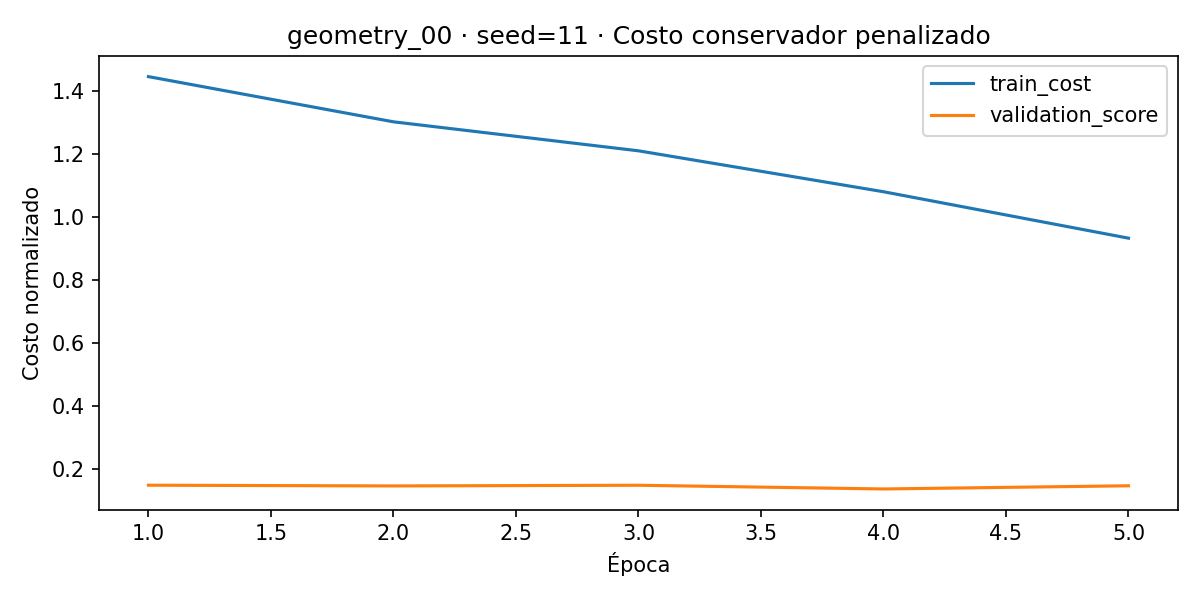

geometry_00/seed_29/final/learning.png


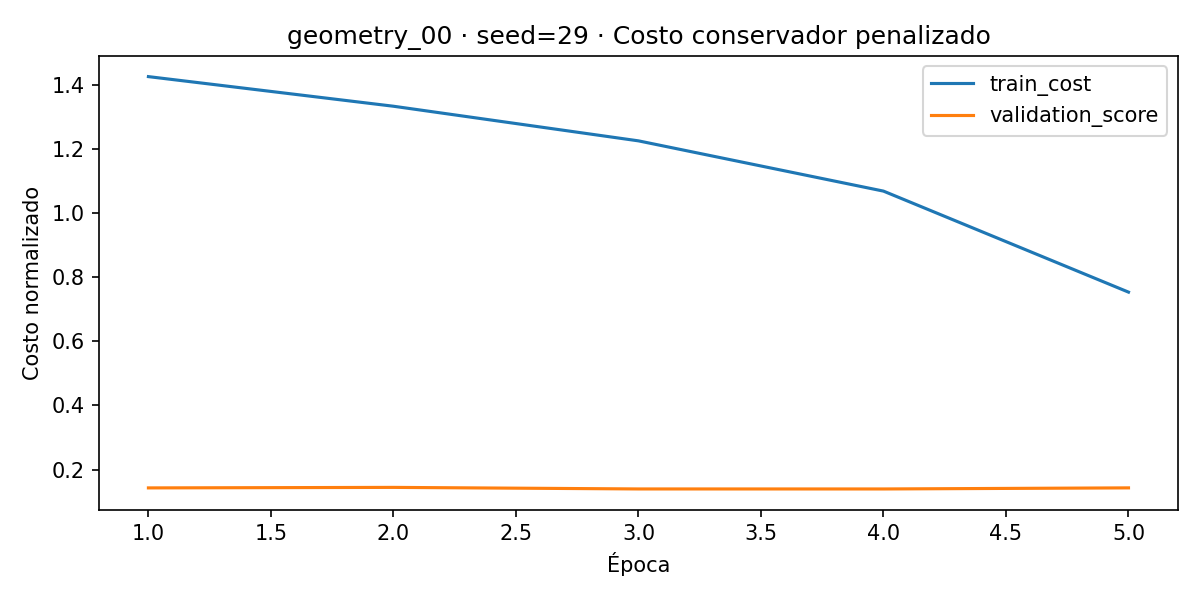

geometry_00/seed_47/final/learning.png


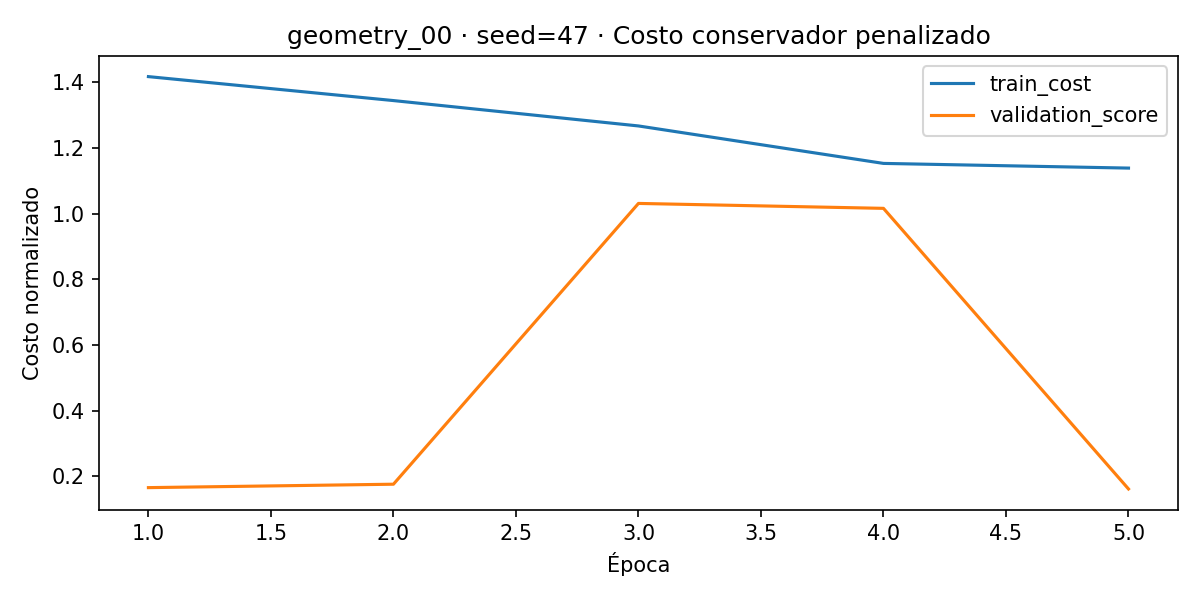

geometry_01/seed_11/final/learning.png


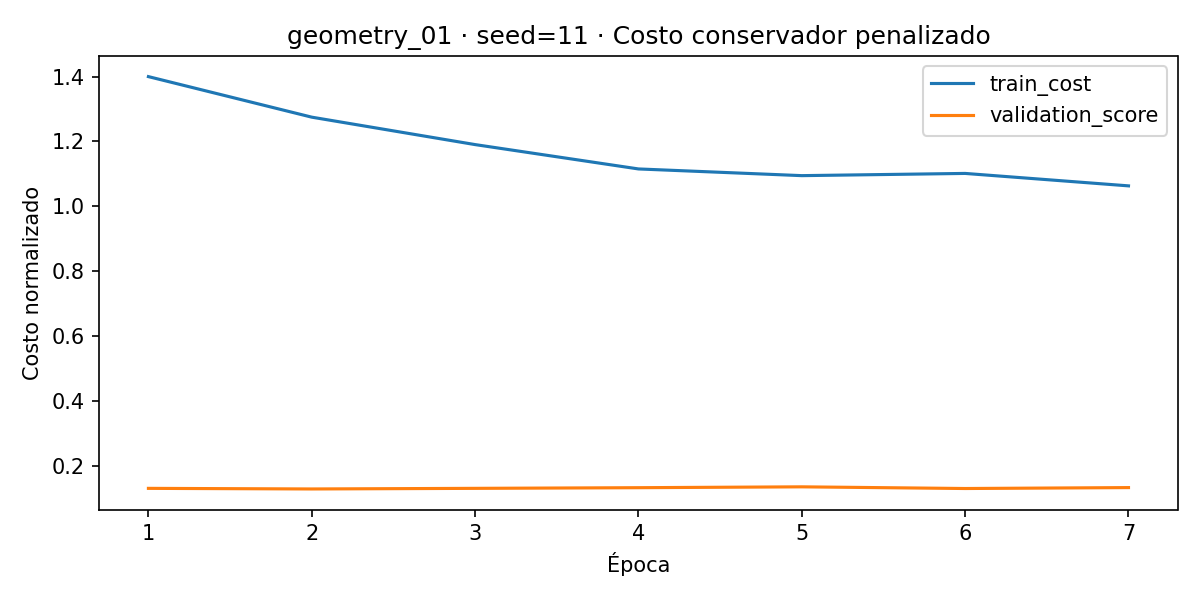

geometry_01/seed_29/final/learning.png


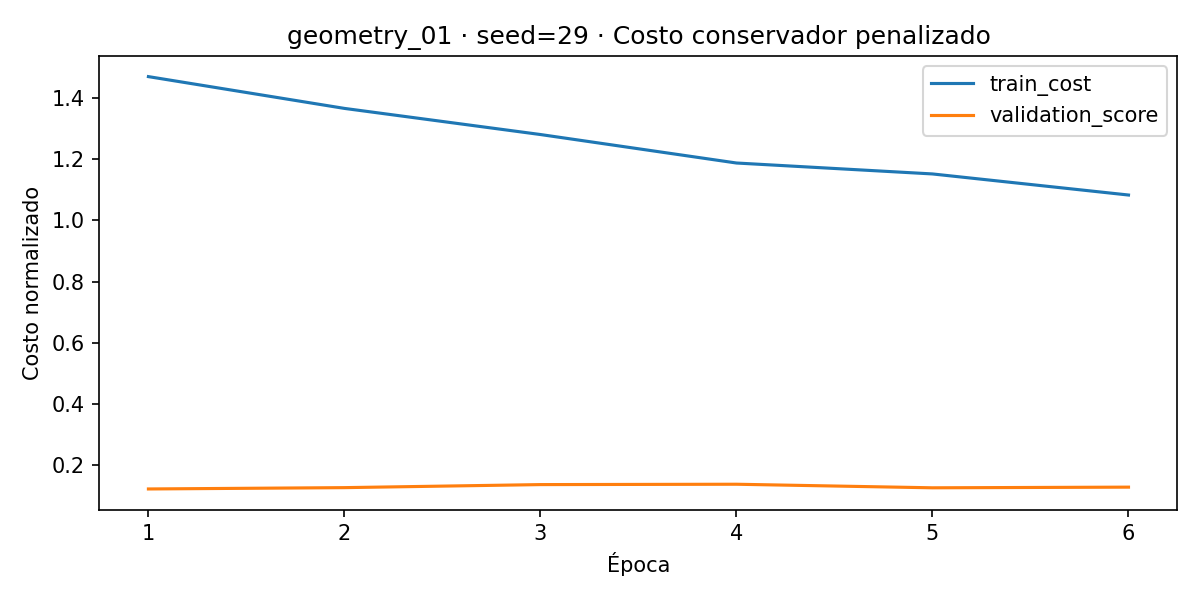

geometry_01/seed_47/final/learning.png


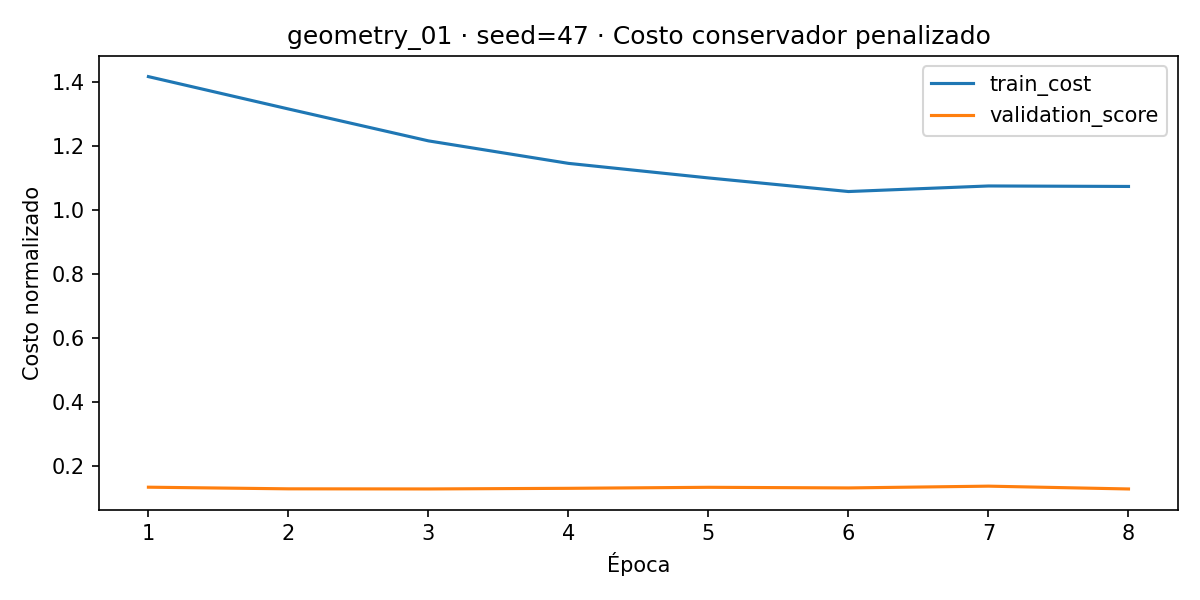

geometry_02/seed_11/final/learning.png


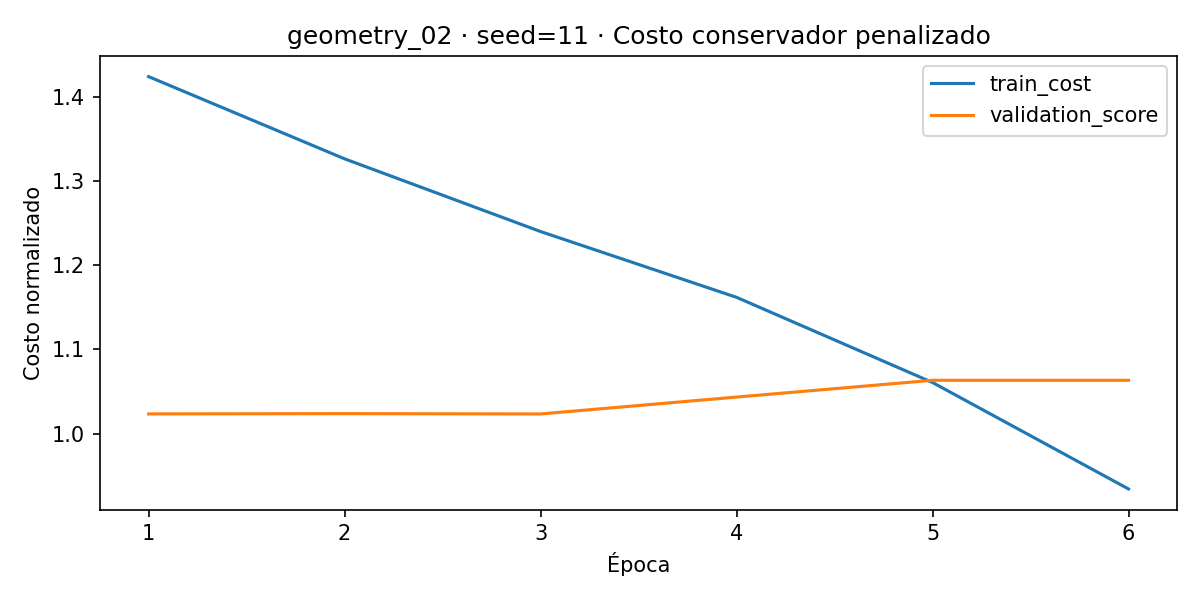

geometry_02/seed_29/final/learning.png


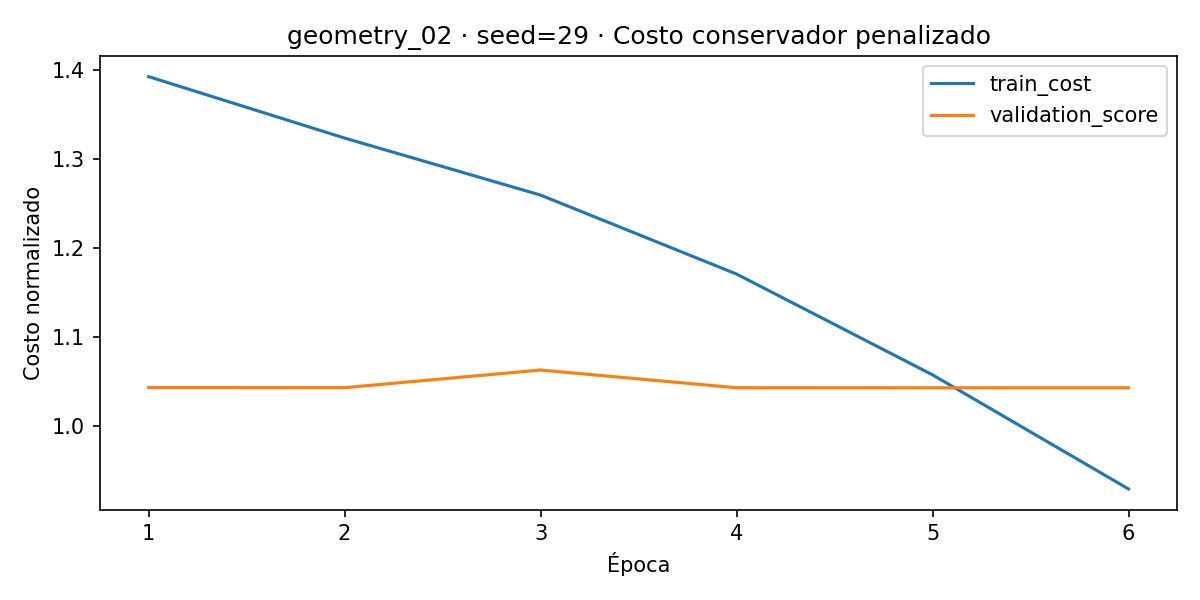

geometry_02/seed_47/final/learning.png


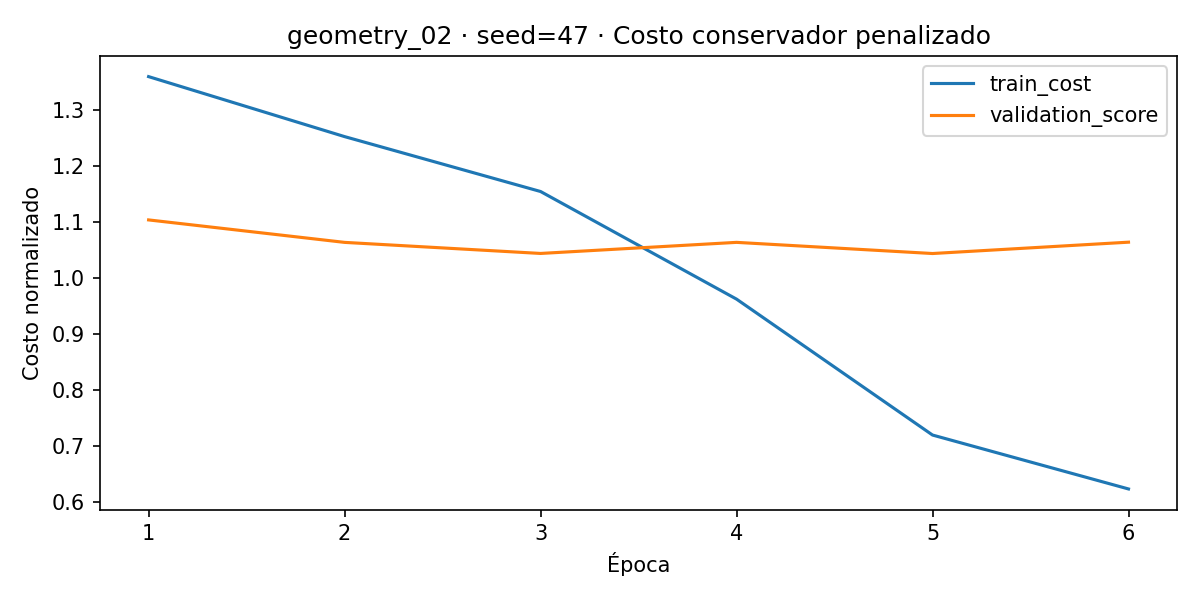

geometry_03/seed_11/final/learning.png


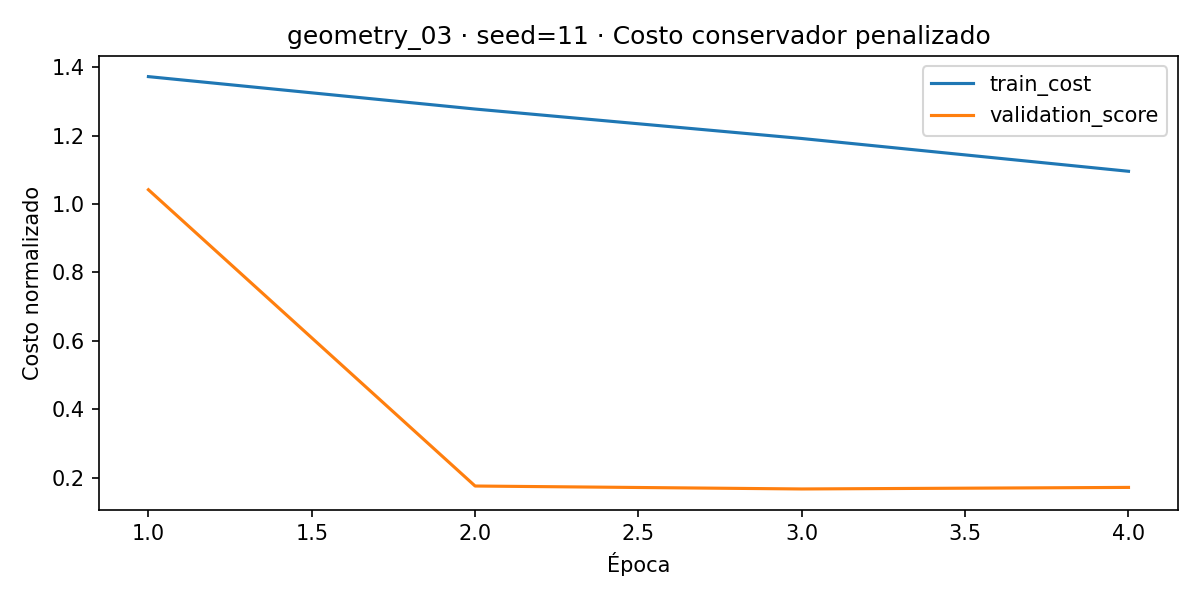

geometry_03/seed_29/final/learning.png


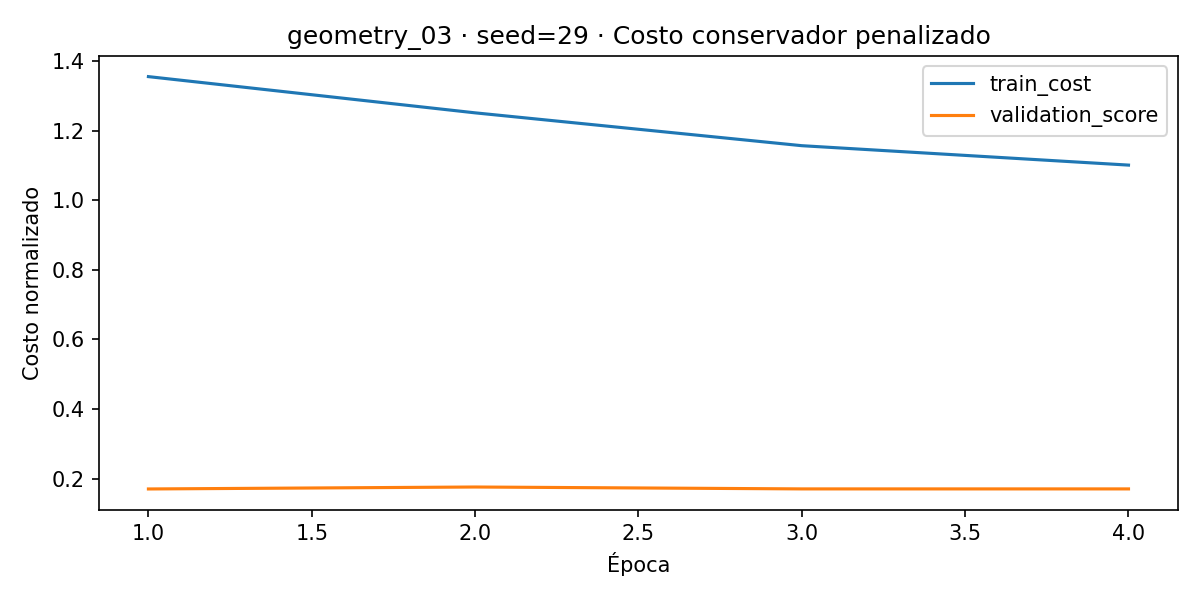

geometry_03/seed_47/final/learning.png


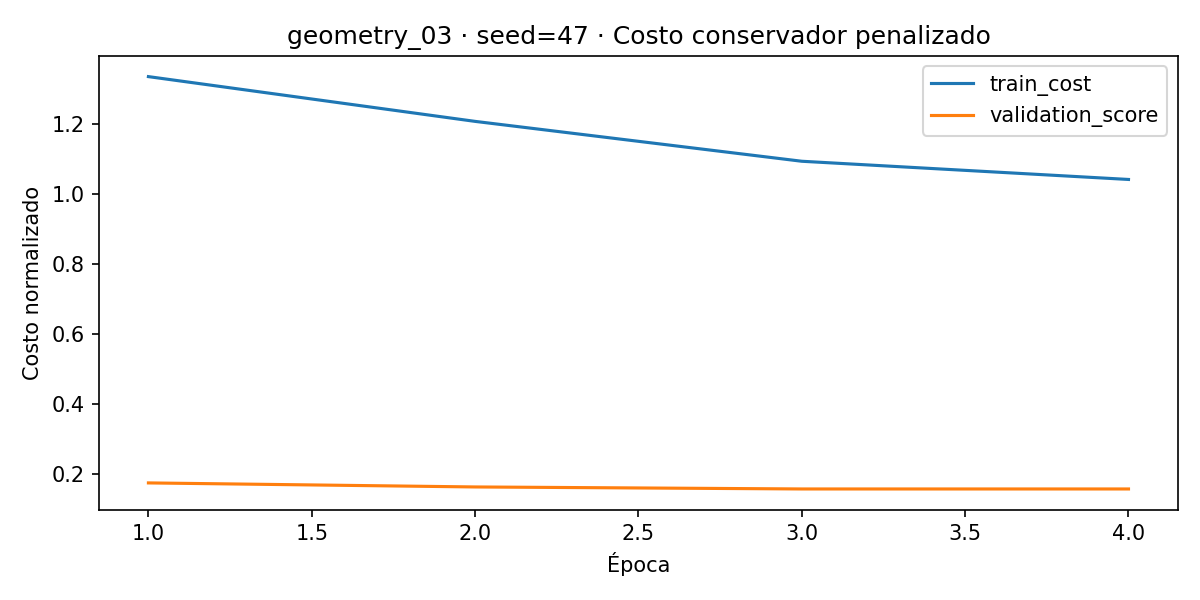

TODOS LOS MODELOS CONGELADOS; selección realizada sin escenarios de evaluación.


In [21]:
TRAINING = rl.train_crossfit(instances, TRAFFIC, REINFORCEMENT_CONFIG, CONFIG['seeds'],
                             WORK, DRIVE_ROOT, BANK_ID, BANK_SHA, EVALUATOR_SHA, device=str(DEVICE))
display(pd.read_csv(TRAINING / 'index/training_summary.csv'))
display(exp.read_json(TRAINING / 'index/offline_costs.json'))
for path in sorted(TRAINING.glob('geometry_*/seed_*/final/learning.png')):
    print(path.relative_to(TRAINING))
    display(Image(filename=str(path)))
print('TODOS LOS MODELOS CONGELADOS; selección realizada sin escenarios de evaluación.')


## 6. Inferencia fuera de geometría y evaluación común
Cada instancia/semilla carga sólo el checkpoint cuyo fold excluyó esa geometría tanto
de entrenamiento como de validación. Inicialmente se usan hasta 16 primeros clientes,
una ronda greedy y una ronda de muestreo, bajo el presupuesto común de 120 segundos.
El límite incluye carga de pesos, encoding y selección entre rutas completas por
costo conservador; CUDA se sincroniza para medir trabajo terminado.

Si todas las trayectorias son incompletas o se agota el presupuesto sin solución,
se registra `no_solution`; se conserva el diagnóstico. No se completan con certificados
ni se concede una reparación fuera del presupuesto. Las rutas se persisten antes de
Monte Carlo y se aplican los escenarios/políticas sellados del mismo evaluador de 01–03.


In [22]:
if p.verify_bundle(BANK) != BANK_SHA:
    raise ValueError('El banco cambió durante el entrenamiento.')
pomo_solver, METHOD_PROVENANCE = rl.make_solver(TRAINING, instances, TRAFFIC, str(DEVICE),
                                                expected_bank_sha256=BANK_SHA)
RUN = exp.run_methods(BANK, CONFIG, {'pomo': pomo_solver}, WORK, DRIVE_ROOT,
                      run_id=RESUME_RUN_ID or None, validation_artifacts=VALIDATION_FILES,
                      method_provenance=METHOD_PROVENANCE)


RUN_ID = 20260917T051517Z_b84740d5
Drive: /content/drive/MyDrive/TESIS-EHBG-FACS/method_runs/pilot00_280553a33c2ab594/20260917T051517Z_b84740d5
pomo/n0050/seed_11: búsqueda / recuperación...
pomo/n0050/seed_29: búsqueda / recuperación...
pomo/n0050/seed_47: búsqueda / recuperación...
pomo/n0100/seed_11: búsqueda / recuperación...
pomo/n0100/seed_29: búsqueda / recuperación...
pomo/n0100/seed_29: fixed_order, 256 escenarios...
pomo/n0100/seed_29: causal_edd, 256 escenarios...
pomo/n0100/seed_47: búsqueda / recuperación...
pomo/n0200/seed_11: búsqueda / recuperación...
pomo/n0200/seed_11: fixed_order, 256 escenarios...
pomo/n0200/seed_11: causal_edd, 256 escenarios...
pomo/n0200/seed_29: búsqueda / recuperación...
pomo/n0200/seed_29: fixed_order, 256 escenarios...
pomo/n0200/seed_29: causal_edd, 256 escenarios...
pomo/n0200/seed_47: búsqueda / recuperación...
pomo/n0200/seed_47: fixed_order, 256 escenarios...
pomo/n0200/seed_47: causal_edd, 256 escenarios...
pomo/n0300/seed_11: búsqueda 

## 7. Resultados visibles y archivos en Drive
`validated` indica que la revisión de evaluación/exportación pasó; no significa FR=1.
Se conservan todas las semillas y fallos. Interpretar costo junto con factibilidad.
Los tiempos offline se repiten por política para trazabilidad y no deben sumarse por fila:
`offline_costs.json` registra cada modelo una vez. No existe costo de profesores en 04.


,method,n_customers,solver_seed,fold_id,policy,solver_status,evaluation_status,nominal_feasible,scenario_strict_feasibility,mean_travel_minutes,cvar_travel_minutes,mean_lateness_minutes,mean_depot_overtime_minutes,used_vehicles,training_seconds,teacher_seconds,model_load_seconds,search_total_seconds,evaluation_seconds
0,pomo,50,11,geometry_03,fixed_order,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603.995190,0.0,0.033864,4.151395,NaN
1,pomo,50,11,geometry_03,causal_edd,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603.995190,0.0,0.033864,4.151395,NaN
2,pomo,50,29,geometry_03,fixed_order,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,605.534258,0.0,0.028920,3.890885,NaN
3,pomo,50,29,geometry_03,causal_edd,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,605.534258,0.0,0.028920,3.890885,NaN
4,pomo,50,47,geometry_03,fixed_order,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,641.038823,0.0,0.028604,4.339746,NaN
5,pomo,50,47,geometry_03,causal_edd,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,641.038823,0.0,0.028604,4.339746,NaN
6,pomo,100,11,geometry_00,fixed_order,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,642.844412,0.0,0.029746,9.311088,NaN
7,pomo,100,11,geometry_00,causal_edd,no_solution,no_solution,NaN,NaN,NaN,NaN,NaN,NaN,NaN,642.844412,0.0,0.029746,9.311088,NaN
8,pomo,100,29,geometry_00,fixed_order,feasible,validated,True,1.000000,22090.301878,22095.340362,0.000000,0.000000,24.0,632.094414,0.0,0.031616,9.298695,2.163103
9,pomo,100,29,geometry_00,causal_edd,feasible,validated,True,1.000000,22090.301878,22095.340362,0.000000,0.000000,24.0,632.094414,0.0,0.031616,9.298695,2.296335


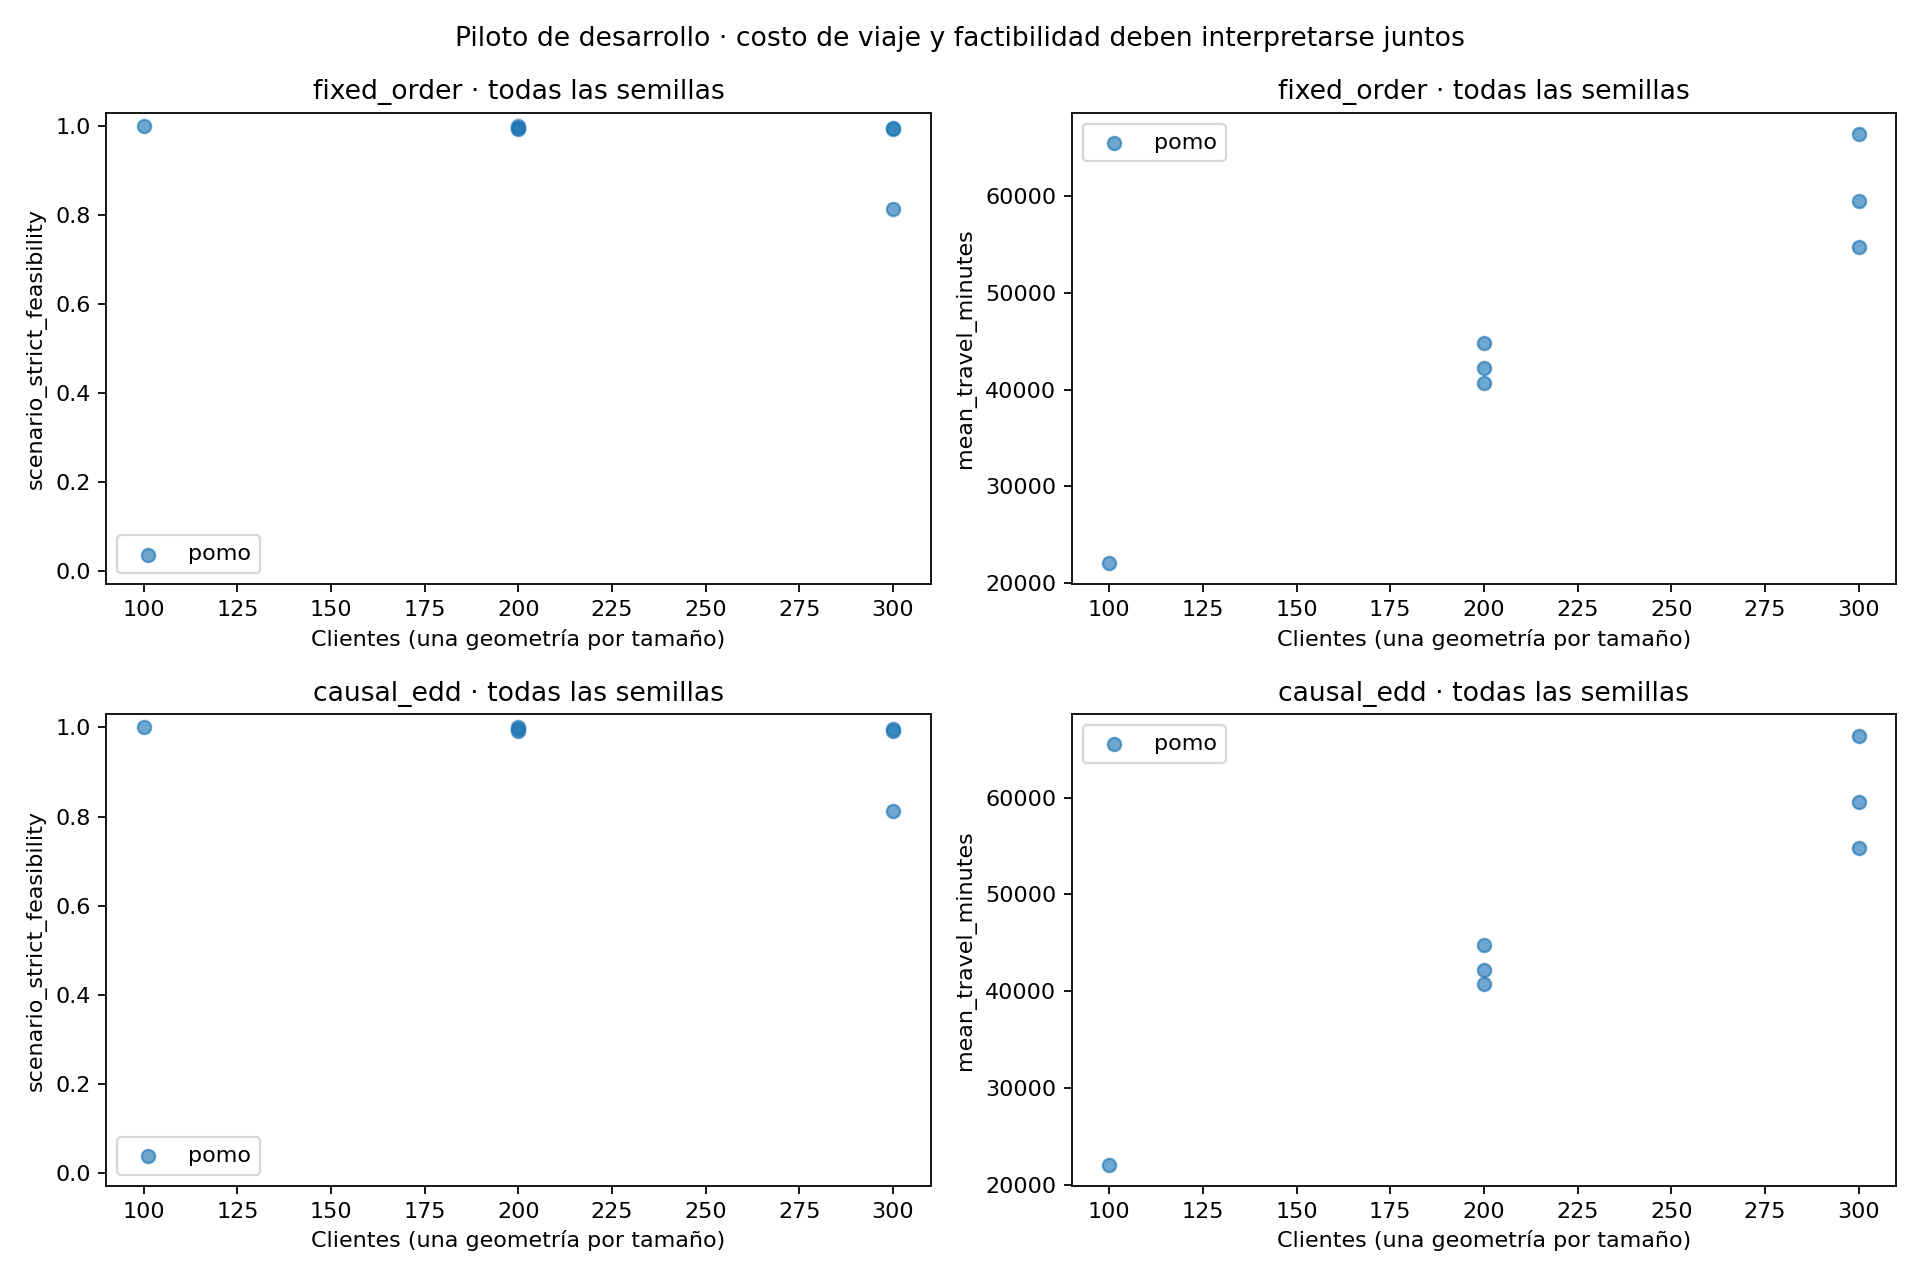

pomo/n0100/seed_29/solution/routes.png


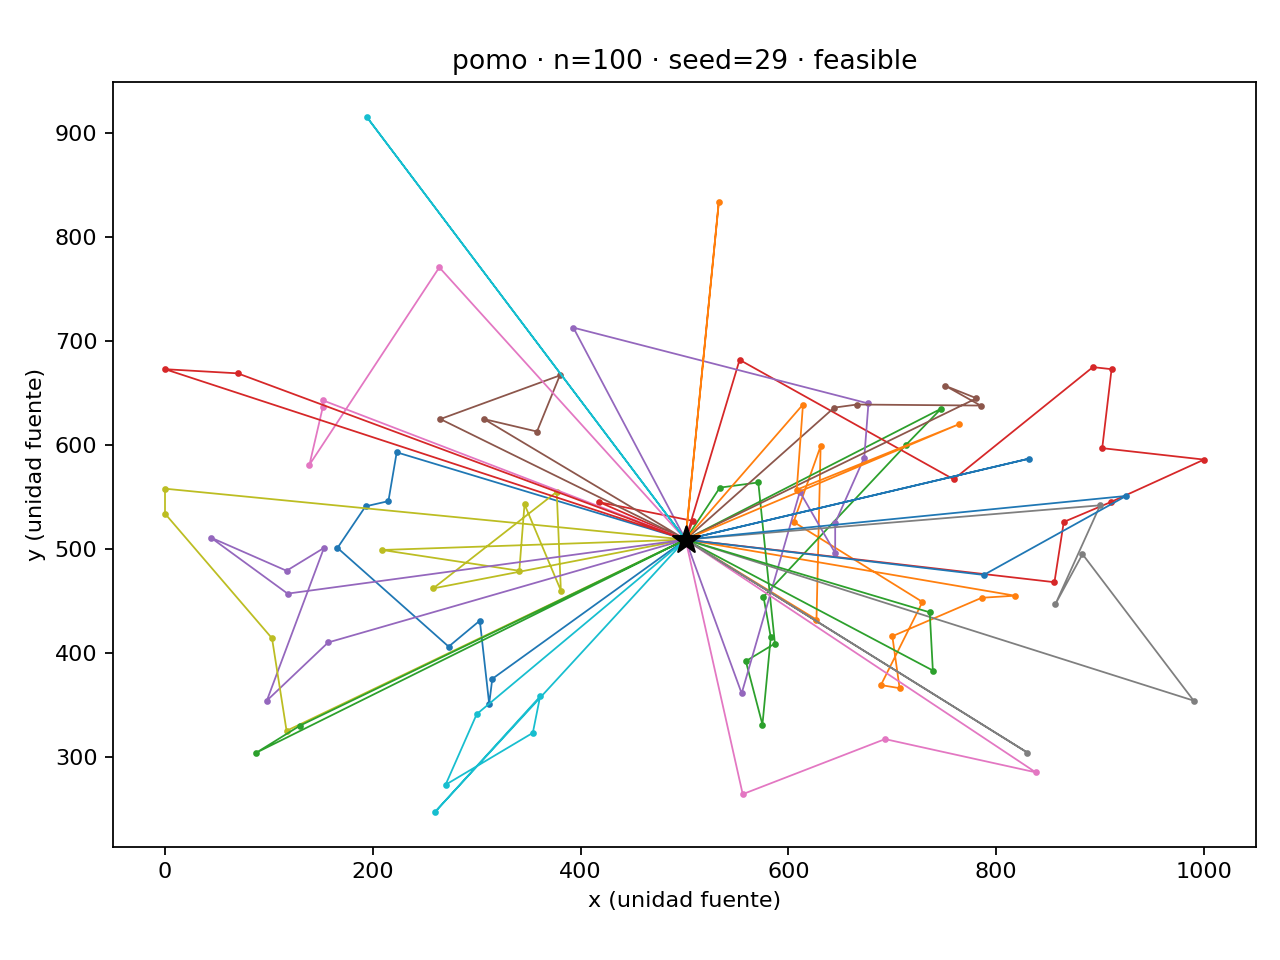

pomo/n0200/seed_11/solution/routes.png


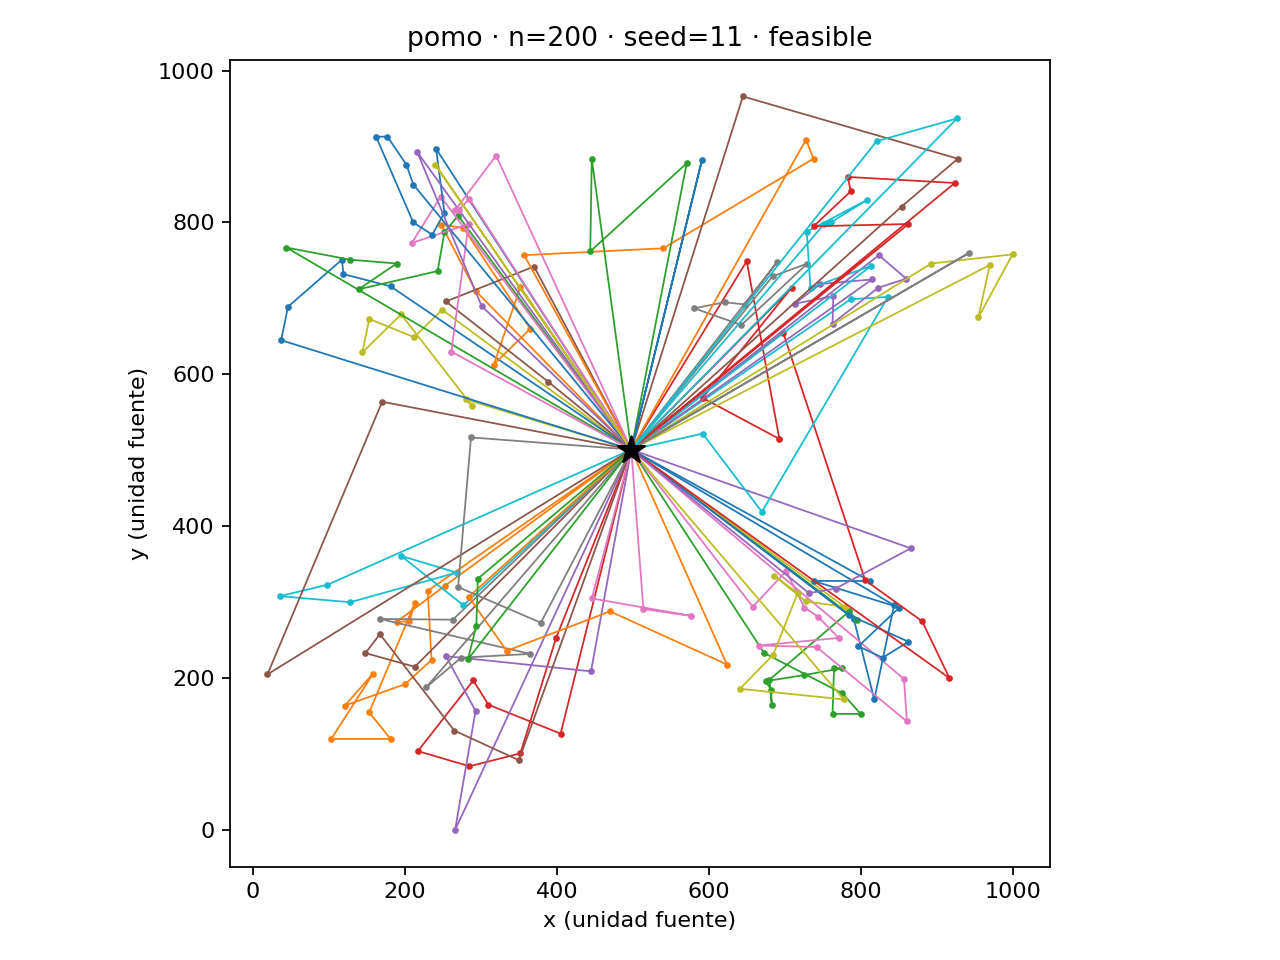

pomo/n0200/seed_29/solution/routes.png


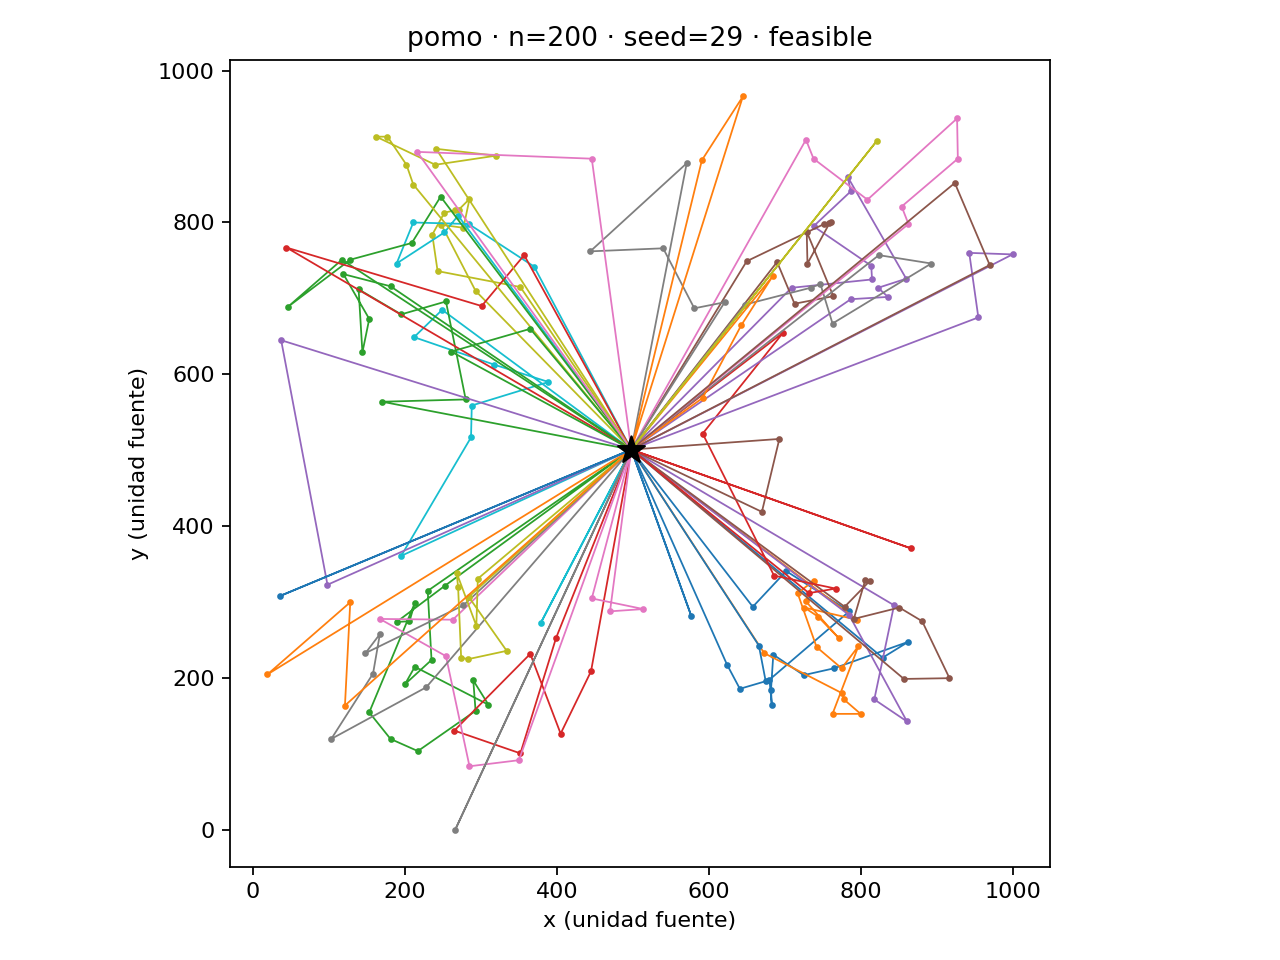

pomo/n0200/seed_47/solution/routes.png


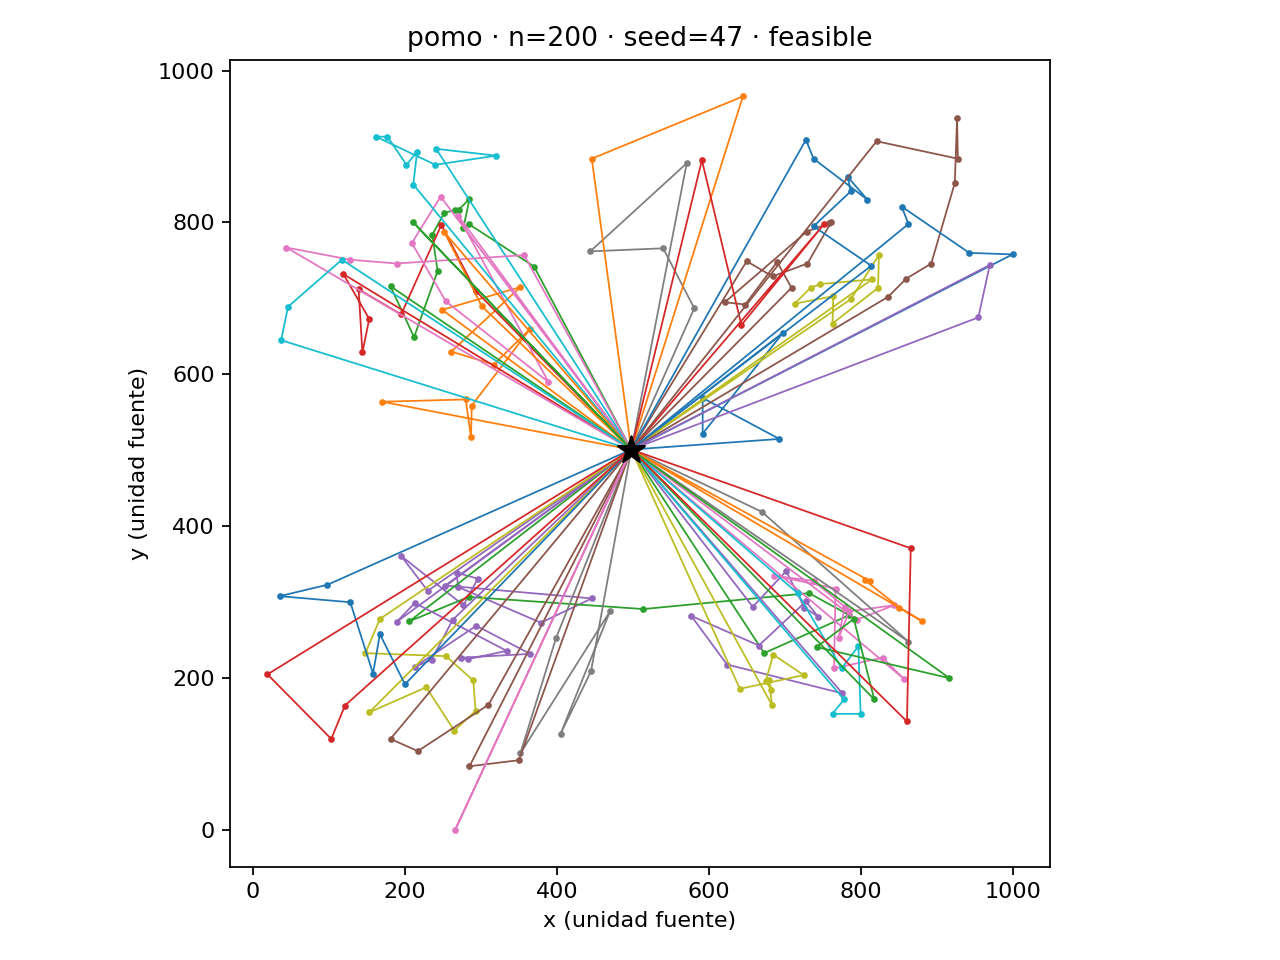

pomo/n0300/seed_11/solution/routes.png


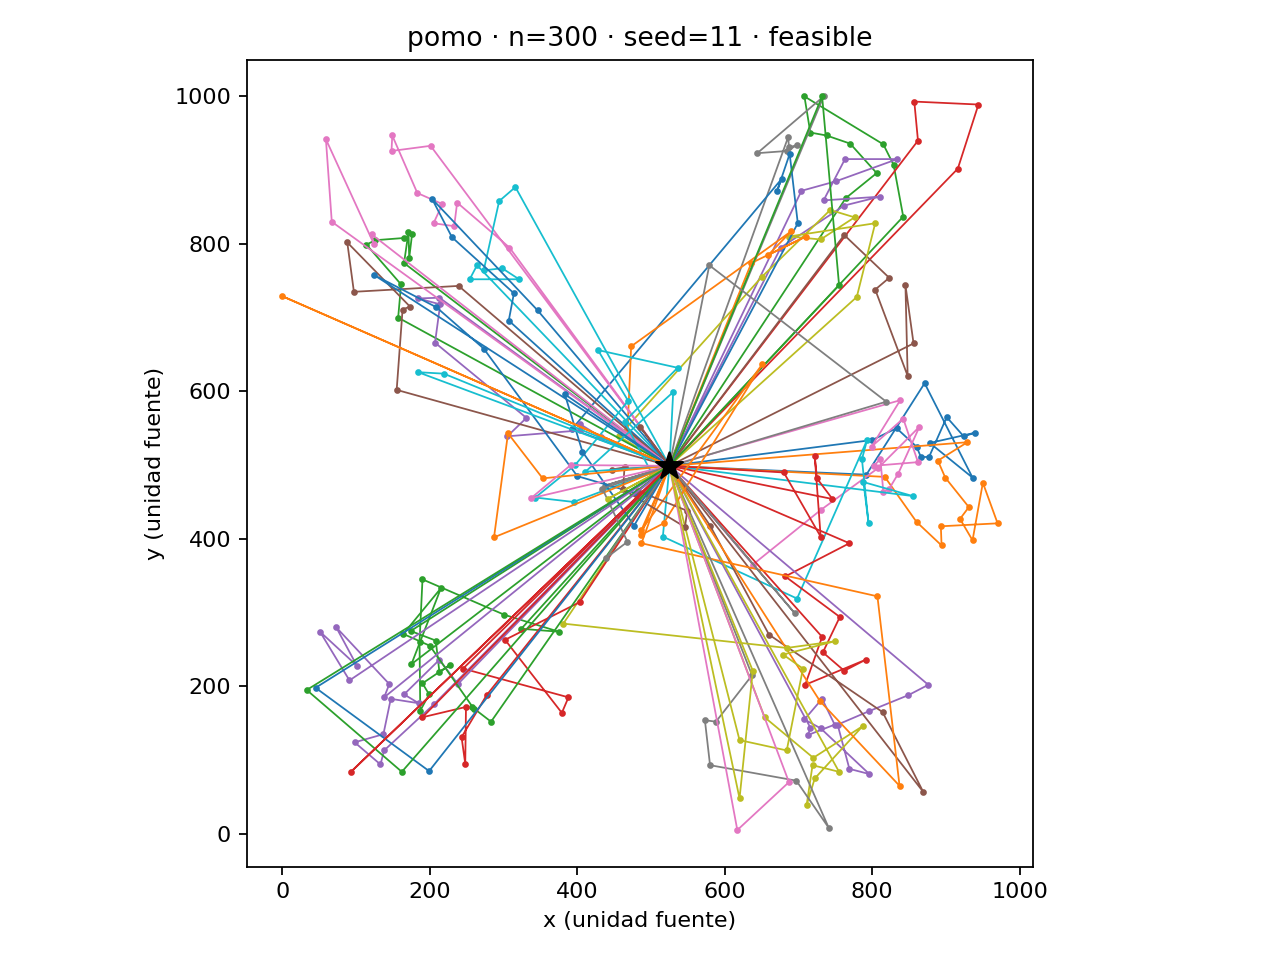

pomo/n0300/seed_29/solution/routes.png


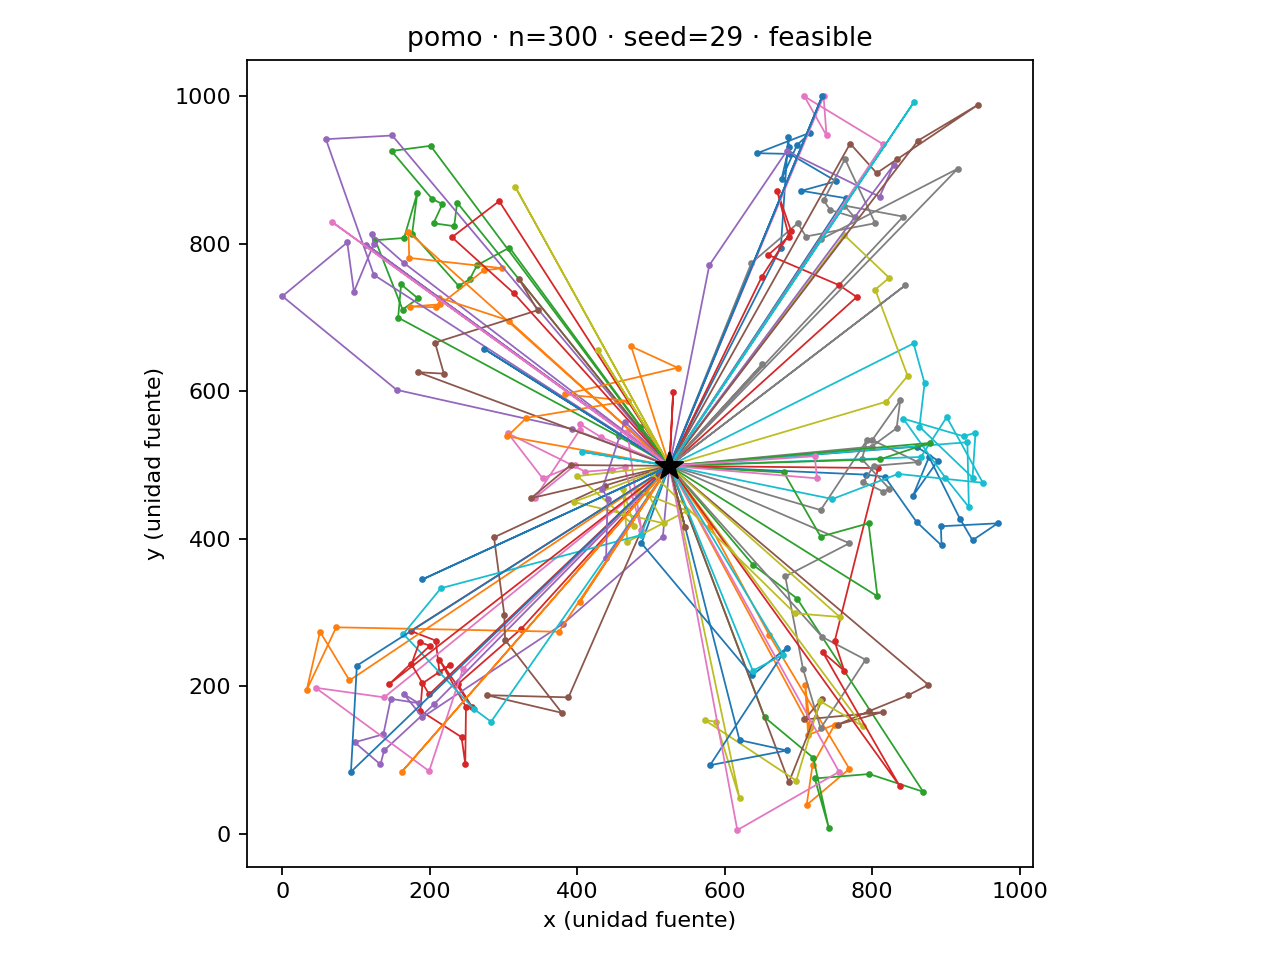

pomo/n0300/seed_47/solution/routes.png


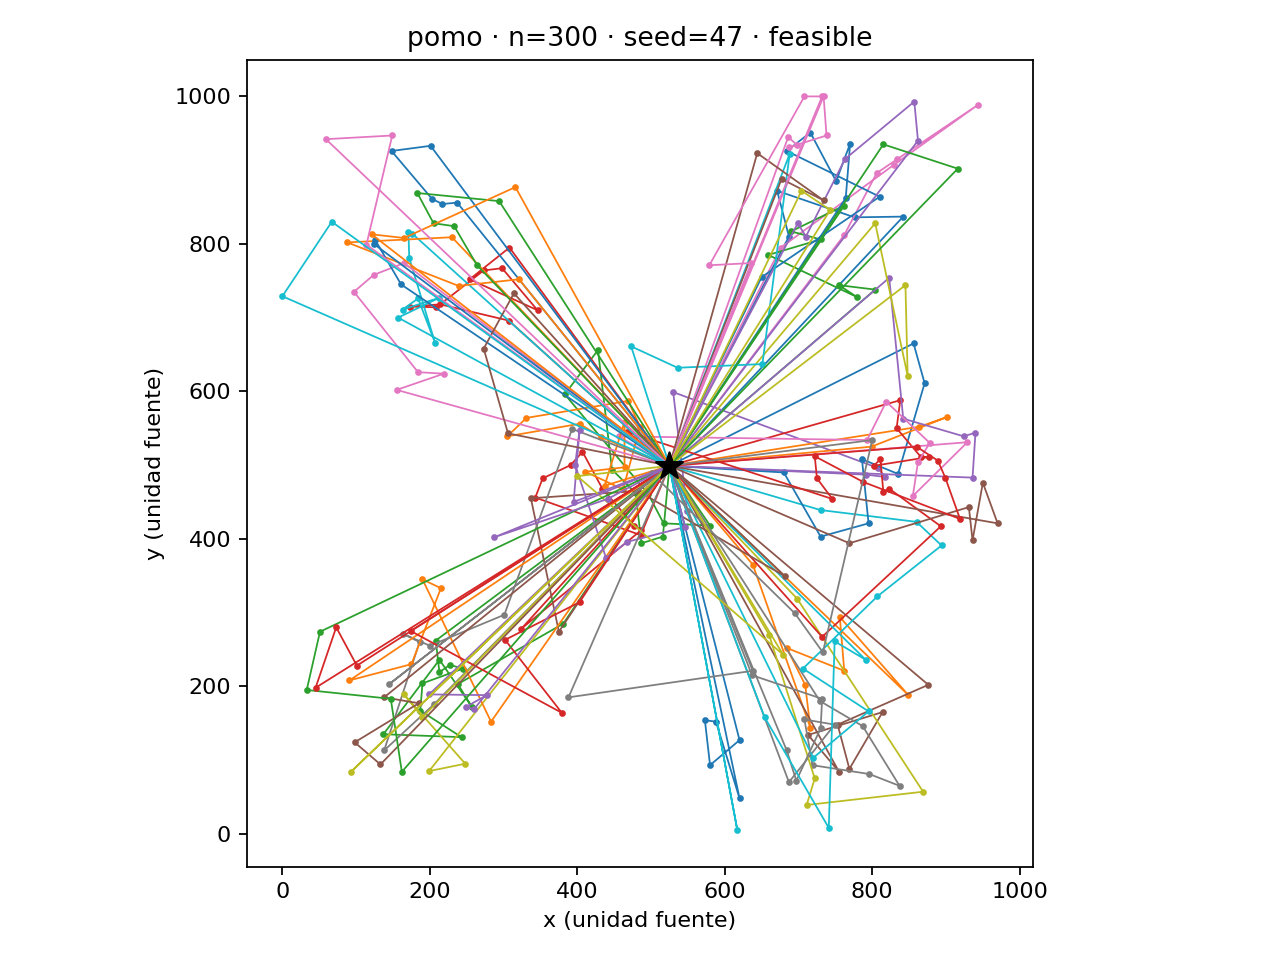

{'status': 'completed',
 'bank_unchanged': True,
 'attempts': 12,
 'summary_rows': 24,
 'unsolved_policy_rows': 10,
 'not_a_claim_of_all_routes_feasible': True,
 'ready_for_confirmatory_comparison': False}

Resultados: /content/drive/MyDrive/TESIS-EHBG-FACS/method_runs/pilot00_280553a33c2ab594/20260917T051517Z_b84740d5
Entrenamiento: /content/drive/MyDrive/TESIS-EHBG-FACS/rl_training/pilot00_280553a33c2ab594/pomo04_f2335785110e3027a9aa
comparison_id: 4c72030271f5bc11bd45f81eec3ba81d8c1c40ed6a59b722a46c36b636215b0c


In [23]:
summary = pd.read_csv(RUN / 'report/summary.csv', dtype={'solver_seed': str, 'training_seed': str})
columns = ['method','n_customers','solver_seed','fold_id','policy','solver_status','evaluation_status',
           'nominal_feasible','scenario_strict_feasibility','mean_travel_minutes','cvar_travel_minutes',
           'mean_lateness_minutes','mean_depot_overtime_minutes','used_vehicles',
           'training_seconds','teacher_seconds','model_load_seconds','search_total_seconds','evaluation_seconds']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(summary[columns])
if (RUN / 'report/metrics.png').exists():
    display(Image(filename=str(RUN / 'report/metrics.png')))
for path in sorted(RUN.glob('*/n*/seed_*/solution/routes.png')):
    print(path.relative_to(RUN))
    display(Image(filename=str(path)))
display(exp.read_json(RUN / 'report/validation.json'))
print('Resultados:', DRIVE_ROOT / 'method_runs' / BANK_ID / RUN.name)
print('Entrenamiento:', DRIVE_ROOT / 'rl_training' / BANK_ID / TRAINING.name)
print('comparison_id:', summary['comparison_id'].iloc[0])


```text
MyDrive/TESIS-EHBG-FACS/
  method_checks/<bank_id>/contract04_*/
  rl_training/<bank_id>/<pomo04_id>/
    meta/identity.json, folds.json, code/
    geometry_*/seed_*/meta/
    geometry_*/seed_*/epoch_*/state.pt, progress.json, environment.json
    geometry_*/seed_*/final/best.pt, summary.json, history.csv, history.json, learning.png
    failures/*/failure.json
    index/models.json, training_summary.csv, offline_costs.json
  method_runs/<bank_id>/<run_id>/
    meta/plan.json, metrics_schema.json, code/, validation/
    pomo/n0050/seed_11/solution/solution.json, planned_routes.csv, nominal_events.csv, routes.png
    pomo/n0050/seed_11/<policy>/scenario_metrics.csv, realized_routes.csv, events.csv, validation.json
    report/summary.csv, failures.csv, metrics.png, validation.json, bundles.json
```

Cada unidad lleva `CHECKSUMS.json` y se sincroniza con verificación. Los CSV incluyen
depósitos y vehículos vacíos; las listas JSON del solver excluyen el depósito. Importar
`scenario_seed` de CSV como texto para preservar los enteros de 64 bits.

Para comparar, regenerar 01–03 con el runner **methods-v2** de esta revisión.
`comparison_id` conserva banco, evaluador, contrato, objetivo, presupuesto y escenarios;
parámetros y checkpoints particulares quedan en la firma estricta de reanudación.
No mezclar automáticamente reportes methods-v1. Las semillas numéricamente iguales
no hacen equivalentes los flujos aleatorios de POMO y ACO. Respetar los niveles
geometría/modelo/escenario; este piloto no calcula p-valores ni demuestra superioridad.
